## Library yang digunakan


Output lama dicadangkan di `reports/notebook_backups/ai_1_nlu_v3_600_before_standalone_1790235729387.ipynb`.


In [1]:
# Library standar Python: file, konfigurasi, waktu, dan memori.
import gc
import json
import math
import platform
import tempfile
import time
from copy import deepcopy
from unittest.mock import patch
from pathlib import Path
from time import perf_counter

# Pengolahan data, visualisasi, dan penyimpanan model.
import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from tqdm import tqdm

# Model klasik, ekstraksi fitur, pencarian parameter, dan evaluasi.
import optuna
import sklearn
from sklearn.model_selection import _search as sklearn_search
from sklearn.calibration import CalibratedClassifierCV
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics import (
    accuracy_score, classification_report, confusion_matrix, f1_score,
)
from sklearn.model_selection import (
    GridSearchCV, ParameterGrid, StratifiedKFold, cross_val_score, cross_validate, train_test_split,
)
from sklearn.naive_bayes import MultinomialNB
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import LabelEncoder
from sklearn.svm import LinearSVC

# Dataset, training, dan inferensi Transformer/IndoBERT.
import torch
import transformers
from datasets import Dataset
from transformers import (
    AutoModelForSequenceClassification,
    AutoTokenizer,
    DataCollatorWithPadding,
    EarlyStoppingCallback,
    Trainer,
    TrainingArguments,
    set_seed,
)


C:\Users\andyc\Documents\a_skripsi\training\prethesis\venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## EDA



In [2]:
# Menentukan lokasi file dataset untuk EDA.
DATASET_PATH = Path("data/dataset_final3.csv")

# Chat tambahan (plan03, 27 Okt 2026) yang hanya dipakai train IndoBERT; validation dan test tetap dari DATASET_PATH.
DATASET_TAMBAHAN = Path("data/dataset_intent_tambahan.csv")

# Pesan sesi chat dari bagian train dataset target (pembagian sama dengan nlu_target) ikut ke train IndoBERT.
# Eksperimen nlu_intent_sesi.ipynb (27 Okt 2026): intent benar pada pesan sesi naik dari 0,57 ke 0,94.
PAKAI_PESAN_SESI = True
DATASET_TARGET = Path("data/dataset_final3_context_target_pilot25_lengkap.csv")
DATASET_TARGET_TAMBAHAN = Path("data/dataset_target_tambahan.csv")


### Aturan Label (relabel 26 Oktober 2026)

Label `dataset_final3.csv` diperiksa ulang dengan aturan tertulis di [`data/ATURAN_LABEL.md`](data/ATURAN_LABEL.md). Tujuannya agar kalimat yang mirip tidak lagi mendapat label berbeda. Sebelumnya ada kasus seperti "saya bukan hitman, saya stalker" yang kadang dilabel neutral, kadang defend. Arti label disamakan dengan cara bot di game memakai intent (`INTENT_AKSI`). Perubahan per baris dicatat di [`data/relabel_2026-10-26.csv`](data/relabel_2026-10-26.csv), dan label lama tetap ada di riwayat git.

| Nama variabel / proses | Untuk apa? | Arti nilai dan pengaruhnya |
| --- | --- | --- |
| `offend` | Pesan menaikkan kecurigaan atau mendorong vote ke pemain atau kelompok berciri. | Termasuk hasil Peek yang memberatkan, menyerang kredibilitas, pertanyaan bernada sindiran, dan mengalihkan kecurigaan. Kalimat **campuran** (membela + menuduh) = offend; relasi per pemain dicatat Model 2. |
| `defend` | Tidak ada unsur offend, dan pesan melindungi pemain dari kecurigaan. | Sangkalan diri, klaim role yang dipakai membela diri, membersihkan pemain lain (mis. hasil Peek "aman"), membantah tuduhan, menjelaskan perilaku yang dicurigai (mis. alasan koneksi). |
| `neutral` | Selain dua di atas. | Klaim role murni, pertanyaan info tanpa sindiran, logistik game, nasihat umum tanpa sasaran, pernyataan umum tentang Hitman. |
| `relabel` | Pemeriksaan ulang semua 5.615 chat. | 331 label berubah (5,9%): neutral→defend 183, defend→offend 84, offend→neutral 30, neutral→offend 23, offend→defend 9, defend→neutral 2. |
| `split test` | Pembagian 65/15/20 dengan stratifikasi label. | Karena label berubah, isi test berbeda dari run sebelum relabel. Untuk perbandingan adil dengan model lama, pakai teks yang ada di **kedua** test set (lihat catatan IndoBERT di akhir notebook). |

### Pembersihan Data Chat


Data dibersihkan agar chat dan label konsisten sebelum dianalisis atau dilatih.

| Nama variabel / proses | Untuk apa? | Arti nilai dan pengaruhnya |
| --- | --- | --- |
| `raw / clean` | Tabel awal dan tabel hasil pembersihan. | clean hanya memakai teks_chat dan label_intent; raw mempertahankan isi awal CSV. |
| `dropna / empty_mask` | Menemukan data kosong. | dropna membuang nilai tidak terisi; empty_mask menandai teks kosong, termasuk spasi yang sudah dirapikan. |
| `replace / strip / lower` | Menyeragamkan penulisan. | Spasi berulang diringkas dan spasi tepi dihapus; lower di tahap ini hanya mengubah label menjadi huruf kecil. |
| `drop_duplicates` | Membuang pasangan chat-label yang identik. | Satu pasangan disimpan sekali agar contoh sama tidak dihitung berulang. |
| `conflicting_texts` | Menemukan teks identik dengan label berbeda. | Jika satu teks punya lebih dari 1 label, semua baris teks itu dibuang agar target tidak bertentangan. |
| `class_counts / report` | Mencatat jumlah tiap intent dan kualitas data. | Hanya laporan; jumlah kelas kecil/besar membantu melihat ketimpangan dataset. |


In [3]:
# Membaca CSV, membersihkan chat dan label, lalu mengembalikan data bersih serta laporan kualitasnya.
def load_clean_nlu_dataset(dataset_path):

    # Menghentikan proses dengan pesan jelas jika file dataset tidak ditemukan.
    path = Path(dataset_path)
    if not path.is_file():
        raise FileNotFoundError(f"Dataset tidak ditemukan: {path}")

    # Membaca isi CSV ke tabel pandas.
    raw = pd.read_csv(path)

    # Mencatat jumlah baris awal dan nilai kosong sebelum data dibersihkan.
    report = {
        "dataset_path": str(path),
        "rows_raw": len(raw),
        "missing_cells_raw": raw[["teks_chat", "label_intent"]].isna().sum().to_dict(),    
    }


    # Mengambil kolom chat dan label, membuang nilai kosong, merapikan spasi, serta menyeragamkan label ke huruf kecil.
    clean = raw[["teks_chat", "label_intent"]].dropna().copy()
    clean["teks_chat"] = clean["teks_chat"].astype(str).str.replace(r"\s+", " ", regex=True).str.strip()
    clean["label_intent"] = clean["label_intent"].astype(str).str.strip().str.lower()
    empty_mask = (clean["teks_chat"] == "") | (clean["label_intent"] == "")


    # Menghitung lalu menghapus baris yang chat atau labelnya menjadi teks kosong setelah dirapikan.
    report["empty_rows_removed"] = int(empty_mask.sum())
    clean = clean.loc[~empty_mask].copy()

    # Menghitung lalu menghapus pasangan chat dan label yang sama persis.
    report["exact_duplicates_removed"] = int(clean.duplicated(["teks_chat", "label_intent"]).sum())
    clean = clean.drop_duplicates(["teks_chat", "label_intent"]).copy()

    # Mencari chat yang memiliki lebih dari satu label dan menghapus semua baris chat tersebut jika ditemukan.
    label_count_per_text = clean.groupby("teks_chat")["label_intent"].nunique()
    conflicting_texts = label_count_per_text[label_count_per_text > 1].index
    report["conflicting_texts_removed"] = int(len(conflicting_texts))
    if len(conflicting_texts):
        clean = clean.loc[~clean["teks_chat"].isin(conflicting_texts)].copy()


    # Menghitung jumlah data tiap intent setelah pembersihan.
    class_counts = clean["label_intent"].value_counts().sort_index()

    # Melengkapi laporan dengan jumlah data bersih, jumlah intent, dan ukuran kelas.
    report.update(
        {
            "rows_clean": len(clean),
            "class_count": int(class_counts.size),
            "class_distribution": class_counts.to_dict(),
            "min_class_size": int(class_counts.min()),
            "max_class_size": int(class_counts.max()),
        }
    )

    # Mengembalikan data dengan indeks baru beserta laporan pembersihannya.
    return clean.reset_index(drop=True), report


### Statistik Panjang Chat


EDA menjelaskan isi dataset; belum mengukur kemampuan model.

| Nama variabel / proses | Untuk apa? | Arti nilai dan pengaruhnya |
| --- | --- | --- |
| `lengths / words` | Mengukur panjang chat. | lengths menghitung karakter; words menghitung bagian teks yang dipisahkan spasi. |
| `length_by_intent` | Membandingkan panjang chat antar-intent. | Menghitung jumlah chat, rata-rata kata/karakter, dan median kata tiap kelas. |
| `average_words / median_words` | Meringkas panjang chat. | Rata-rata terpengaruh chat sangat panjang; median adalah nilai tengah setelah diurutkan. |
| `short_chat_under_3_words` | Menghitung chat pendek. | Kurang dari 3 berarti 1 atau 2 kata pada data bersih; tidak otomatis dihapus. |


In [4]:
# Menghitung panjang chat dan statistik per intent untuk melengkapi laporan EDA.
def build_eda_summary(dataset_path):

    # Mengambil data bersih dan laporan pembersihan.
    clean, report = load_clean_nlu_dataset(dataset_path)

    # Menghitung jumlah karakter dan kata pada setiap chat.
    lengths = clean["teks_chat"].str.len()
    words = clean["teks_chat"].str.split().str.len()

    # Mengelompokkan chat per intent untuk menghitung jumlah dan rata-rata panjangnya.
    length_by_intent = (
        pd.DataFrame({"label_intent": clean["label_intent"], "karakter": lengths, "kata": words})
        .groupby("label_intent")
        .agg(jumlah=("kata", "size"), rata_kata=("kata", "mean"), median_kata=("kata", "median"), rata_karakter=("karakter", "mean"))
        .round(2)
        .sort_index()
    )

    # Menambahkan jumlah chat pendek serta rata-rata dan median jumlah kata ke laporan.
    report["short_chat_under_3_words"] = int((words < 3).sum())
    report["average_words"] = round(float(words.mean()), 2)
    report["median_words"] = round(float(words.median()), 2)
    return clean, report, length_by_intent


### Membaca Hasil EDA


Fungsi run_eda memanggil laporan untuk dataset notebook.

| Nama variabel / proses | Untuk apa? | Arti nilai dan pengaruhnya |
| --- | --- | --- |
| `rows_raw / rows_clean` | Membandingkan jumlah sebelum/sesudah pembersihan. | Selisih berasal dari baris kosong, duplikat, atau konflik yang dihapus. |
| `class_distribution / class_count` | Melihat jumlah chat per kelas dan jumlah kelas. | Distribusi timpang berarti salah satu intent memiliki jauh lebih banyak contoh. |
| `plot=True` | Menampilkan grafik batang. | Tinggi batang adalah jumlah chat, bukan accuracy. |
| `data_bersih / laporan_eda` | Hasil pemanggilan EDA. | Menyimpan data bersih dan statistik untuk diperiksa; tidak melakukan training. |


In [5]:
# Menampilkan laporan kualitas data, statistik panjang chat, dan grafik distribusi intent.
def run_nlu_eda(dataset_path, plot = True):

    # Mengambil statistik EDA yang akan ditampilkan.
    clean, report, length_by_intent = build_eda_summary(dataset_path)

    # Menampilkan laporan kualitas, distribusi intent, dan panjang chat dalam bentuk teks.
    print("=" * 58)
    print("EDA DATASET NLU HOSTAGE")
    print("=" * 58)
    print(f"Dataset                 : {report['dataset_path']}")
    print(f"Baris mentah / bersih   : {report['rows_raw']} / {report['rows_clean']}")
    print(f"Nilai kosong            : {report['missing_cells_raw']}")
    print(f"Duplikat tepat dihapus  : {report['exact_duplicates_removed']}")
    print(f"Teks konflik dihapus    : {report['conflicting_texts_removed']}")
    print(f"Jumlah intent           : {report['class_count']}")
    print(f"Ukuran kelas min--maks  : {report['min_class_size']}--{report['max_class_size']}")
    print(f"Rata-rata kata/chat     : {report['average_words']}")
    print(f"Chat < 3 kata           : {report['short_chat_under_3_words']}")
    print("\nDistribusi intent:")
    print(pd.Series(report["class_distribution"], name="jumlah"))
    print("\nStatistik panjang chat per intent:")
    print(length_by_intent)

    # Jika plot diaktifkan, menampilkan grafik batang jumlah chat pada setiap intent.
    if plot:
        distribution = pd.Series(report["class_distribution"]).sort_values(ascending=False)
        ax = distribution.plot.bar(figsize=(10, 4), color="#4C78A8", title="Distribusi data per intent")
        ax.set_xlabel("Intent")
        ax.set_ylabel("Jumlah chat")
        plt.xticks(rotation=30, ha="right")
        plt.tight_layout()
        plt.show()

    return clean, report


# Menjalankan EDA menggunakan lokasi dataset yang sudah diatur di atas.
def run_eda(plot=True):
    return run_nlu_eda(DATASET_PATH, plot=plot)


### Tampilkan distribusi dan kualitas data


EDA DATASET NLU HOSTAGE
Dataset                 : data\dataset_final3.csv
Baris mentah / bersih   : 5615 / 5611
Nilai kosong            : {'teks_chat': 0, 'label_intent': 0}
Duplikat tepat dihapus  : 4
Teks konflik dihapus    : 0
Jumlah intent           : 3
Ukuran kelas min--maks  : 1048--2629
Rata-rata kata/chat     : 11.76
Chat < 3 kata           : 2

Distribusi intent:
defend     1048
neutral    1934
offend     2629
Name: jumlah, dtype: int64

Statistik panjang chat per intent:
              jumlah  rata_kata  median_kata  rata_karakter
label_intent                                               
defend          1048      11.78         12.0          70.57
neutral         1934       9.25          9.0          56.50
offend          2629      13.60         13.0          83.26


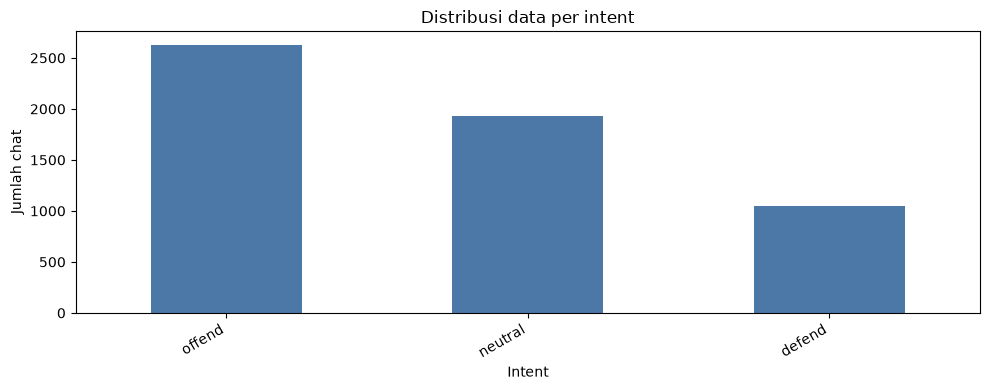

In [6]:
data_bersih, laporan_eda = run_eda()


## Cara membaca dan menjalankan notebook

Setelah EDA, kode disusun per fungsi pekerjaan. Baca penjelasan di atas cell, lalu jalankan cell tersebut: **definisi tahap dan pemanggilannya ada dalam cell yang sama**. SVM, Naive Bayes, dan IndoBERT memiliki urutan persiapan → training → evaluasi → penyimpanan → laporan. Fungsi bantu ditulis dekat pemakaiannya; tidak ada kumpulan fungsi training yang harus dicari di bagian lain. Jalankan dari atas ke bawah pada kernel baru. Output non-EDA dikosongkan karena susunan cell berubah; hasil lama ada di [backup notebook](../reports/notebook_backups/nlu_cells_before_20261001/nlu_baru.ipynb).


## Pengaturan eksperimen

Konfigurasi bersama ditetapkan sebelum bagian model. Parameter asli, seed, data test, dan aturan pemilihan model dipertahankan.


### Seed Eksperimen


Seed membantu mengulang pengacakan secara konsisten.

| Nama variabel / proses | Untuk apa? | Arti nilai dan pengaruhnya |
| --- | --- | --- |
| `RANDOM_STATE=42` | Menjadi acuan pengacakan split, CV, SVM, Optuna, dan IndoBERT. | 42 adalah angka pilihan, bukan tingkat akurasi. Menggantinya dapat mengubah pembagian dan hasil; seed tetap bukan jaminan hasil identik pada semua perangkat. |


In [7]:
# Menetapkan seed untuk pembagian data, cross-validation, dan training yang konsisten.
RANDOM_STATE = 42

# Folder penyimpanan model hasil training.
MODEL_DIR = Path("models/notebook_standalone")


In [8]:
#  settinggan untuk biar training cpu/gpu gitu ga ngaruh ke ini skripsi-----------------------------------------------------------------------------

# Model klasik dijalankan pada CPU.
CLASSICAL_DEVICE = "cpu"

# Gunakan seluruh core CPU yang tersedia untuk CV paralel.
CV_N_JOBS = -1

### Model yang Dilatih pada Run Ini

Tiga saklar ini menentukan model mana yang benar-benar dilatih saat notebook dijalankan (Run All). Fungsi training tetap didefinisikan semuanya.

| Nama variabel / proses | Untuk apa? | Arti nilai dan pengaruhnya |
| --- | --- | --- |
| `LATIH_SVM` | Melatih SVM baseline, Grid Search, dan Optuna. | False: cell training dan laporan SVM hanya mencetak "dilewati". |
| `LATIH_NB` | Melatih Naive Bayes baseline, Grid Search, dan Optuna. | False: cell training dan laporan NB hanya mencetak "dilewati". |
| `LATIH_INDOBERT` | Melatih IndoBERT (dipakai bot di game). | False: cell training dan laporan IndoBERT dilewati. |

Tabel perbandingan di akhir hanya berisi model yang dilatih pada run ini. File `grid_comparison.csv` dan `optuna_comparison.csv` lama tidak ditimpa bila SVM/NB dilewati.

In [9]:
# Saklar model: True = dilatih pada run ini, False = dilewati.
LATIH_SVM = False
LATIH_NB = False
LATIH_INDOBERT = True

### Pengaturan CV dan Batas Optuna


CV menilai kandidat pada data train; Optuna berhenti sesuai batas trial, waktu, atau stagnasi.

| Nama variabel / proses | Untuk apa? | Arti nilai dan pengaruhnya |
| --- | --- | --- |
| `CV_FOLDS=5` | Jumlah pembagian cross-validation. | Belajar pada 4 bagian, dinilai pada 1 bagian, bergantian 5 kali. Makin banyak fold, makin banyak pekerjaan training. |
| `OPTUNA_MIN_TRIALS=100` | Fase awal sebelum menghitung stagnasi. | Mulai menghitung stagnasi setelah 100 trial COMPLETE; error atau timeout masih bisa menghentikan lebih awal. |
| `OPTUNA_PATIENCE=30` | Toleransi trial stagnan setelah fase awal. | Berhenti setelah 30 trial COMPLETE tanpa peningkatan cukup. Lebih besar memberi pencarian lebih lama. |
| `OPTUNA_MIN_DELTA=0.001` | Batas kenaikan skor yang dianggap cukup. | 0.850 ke 0.851 naik 0.001 atau 0.1 poin persentase. Lebih kecil membuat peningkatan kecil lebih mudah diterima. |
| `OPTUNA_MAX_TRIALS=500` | Batas jumlah percobaan. | Maksimal 500 trial, bisa berhenti lebih awal; tidak harus 500 kombinasi unik. |
| `OPTUNA_TIMEOUT=None` | Batas waktu pencarian. | None berarti tanpa batas waktu; angka berarti detik dan dapat menghentikan sebelum minimum trial tercapai. |


In [10]:
# Jumlah fold untuk cross-validation saat tuning. artinya Dipakai saat Grid Search dan Optuna untuk menilai kandidat parameter,ata training dibagi menjadi 5 bagian.
# Setiap kandidat dilatih memakai 4 bagian dan dinilai pada 1 bagian, bergantian sebanyak 5 kali. Rata-rata macro-F1 dipakai untuk memilih parameter terbaik.
CV_FOLDS = 5


# Batas trial dan aturan berhenti Optuna saat skor tidak membaik.
OPTUNA_MIN_TRIALS = 100

# klo dia udh lewat min_trial kita set dia baca max 30 klo ga membaik tolak
OPTUNA_PATIENCE = 30

# batas minila peningkatan skot macro-F1 yang dianggap membaik. Jika perbaikan kurang dari ini, Optuna akan menghentikan pencarian parameter.
OPTUNA_MIN_DELTA = 0.001

# Batas maksimal trial Optuna. Jika diisi, Optuna akan berhenti setelah mencapai jumlah ini meski skor masih membaik.
OPTUNA_MAX_TRIALS = 500

OPTUNA_TIMEOUT = None  # Bila diisi, timeout boleh menghentikan sebelum 100 trial.


### Contoh Chat untuk Pemeriksaan


Sepuluh contoh memperlihatkan perilaku model; terpisah dari evaluasi dataset test.

| Nama variabel / proses | Untuk apa? | Arti nilai dan pengaruhnya |
| --- | --- | --- |
| `HOSTAGE_TEST_CASES` | Pasangan label yang diharapkan dan teks chat. | Contoh (defend, Aku bukan Hitman) berarti prediksi yang diharapkan adalah defend. |
| `Benar dari 10` | Jumlah contoh yang diprediksi sesuai label. | 9/10 berarti 90% pada sepuluh chat tersebut; bukan pengganti accuracy seluruh test. |


In [11]:
# Contoh chat dan label yang diharapkan untuk evaluasi tambahan.
HOSTAGE_TEST_CASES = [
    ("offend", "B kena Gag Order ketika mulai ditanya alibinya, menurutku itu pola Hitman."),
    ("defend", "Aku bukan Hitman. Tuduhan itu tidak punya bukti dari chat publik."),
    ("defend", "Aku Spy dan semalam Guard Raka, jadi jangan curigai dia."),
    ("neutral", "Stalker, kamu Peek siapa semalam dan apa hasil yang kamu lihat?"),
    ("offend", "Jangan hanya fokus ke aku; cek D yang ceritanya berubah setiap ditanya."),
    ("offend", "Vote C saja, dia paling diuntungkan ketika seseorang mendadak diam."),
    ("defend", "Klaimku Civilian, jadi aku memang tidak memiliki aksi malam."),
    ("neutral", "Malam ini chat terkunci, kita lanjut diskusi setelah fase pagi."),
    ("offend", "A selalu menghindar saat kita tanya kenapa dia menuduh tanpa bukti."),
    ("defend", "aku diam aja dari awal bukan berarti aku pelakunya; aku masih bisa menjelaskan alibiku di fase siang."),
]


## SVM

Bagian ini berisi baseline, Grid Search, dan Optuna SVM. Setiap eksperimen dipecah menurut tugasnya agar persiapan, training, evaluasi, dan penyimpanan bisa diperiksa terpisah.


### Parameter Khusus SVM


SVM belajar batas pemisah antar-intent. Regularisasi membatasi bobot agar tidak terlalu mengikuti pola kebetulan.

| Nama variabel / proses | Untuk apa? | Arti nilai dan pengaruhnya |
| --- | --- | --- |
| `SVM_C_VALUES` | Pilihan C untuk tuning. | 0.25?8.0 adalah nilai yang dicoba. Kecil: pembatasan lebih kuat, bisa melewatkan pola penting. Besar: lebih mengejar kecocokan training, bisa mengikuti pola kebetulan. |
| `SVM_MAX_ITER=10000` | Batas langkah solver memperbaiki bobot. | Maksimal 10.000 iterasi dan bisa selesai lebih cepat bila stabil; bukan epoch IndoBERT, jumlah chat, atau trial. |
| `C terbaik` | Memilih konfigurasi yang sesuai data. | Ditentukan dari macro-F1 CV; C terbesar tidak otomatis paling akurat. |


In [12]:
# Pilihan nilai C untuk tuning SVM; penjelasan ada di bawah.
SVM_C_VALUES = [0.25, 0.5, 0.75, 1.0, 1.25, 1.5, 2.0, 4.0, 8.0]

# Batas maksimum iterasi solver LinearSVC untuk mencari solusi training.
SVM_MAX_ITER = 10000


Baseline adalah pembanding dengan parameter tetap sebelum tuning.

| Nama variabel / proses | Untuk apa? | Arti nilai dan pengaruhnya |
| --- | --- | --- |
| `ngram_range=(1,2)` | Mengambil kata tunggal dan pasangan dua kata. | Contoh bukan dan bukan hitman dipakai bersama sebagai fitur. |
| `min_df=1 / max_df=0.98` | Menyaring fitur menurut jumlah chat. | Boleh muncul hanya pada 1 chat; dibuang jika muncul pada lebih dari 98% chat training. |
| `sublinear_tf=True` | Mengurangi dominasi fitur berulang. | Frekuensi positif menjadi 1 + log(frekuensi), sehingga pengaruh pengulangan bertambah lebih lambat. |
| `strip_accents="unicode"` | Menyeragamkan karakter beraksen. | Variasi aksen huruf dinormalisasi agar tidak selalu menjadi fitur berbeda. |


**TF-IDF mengubah chat menjadi angka** agar SVM dan Naive Bayes bisa mengenali intent `offend`, `defend`, atau `neutral`. Angka tersebut mewakili bobot kata atau potongan karakter: seberapa sering muncul dalam satu chat, serta seberapa umum di kumpulan chat training.

Daftar `[ ... ]` berisi **pilihan yang dicoba saat tuning**, bukan semuanya dipakai sekaligus. `common` berisi pilihan bersama; perulangan `for analyzer, ngrams` memasangkan jenis fitur dengan panjang rangkaiannya. Awalan `tfidf__`, `svm__`, dan `nb__` menunjukkan bagian model yang diatur.

| Nama parameter | Untuk apa? | Arti nilai dan pengaruhnya |
| --- | --- | --- |
| `tfidf__min_df` | Membuang fitur yang terlalu jarang muncul. | `1`: cukup ada di 1 chat; `2`: harus ada di minimal 2 chat. Makin besar, makin banyak fitur langka dibuang. Ini jumlah **chat**, bukan pengulangan kata dalam satu chat. |
| `tfidf__max_df` | Membuang fitur yang terlalu umum. | `0.95`: buang fitur yang muncul di lebih dari 95% chat; `1.0`: boleh muncul di semua chat. Makin kecil, makin ketat menyaring fitur umum. |
| `tfidf__sublinear_tf` | Mengatur pengaruh kata/fitur yang berulang dalam satu chat. | `True`: gunakan `1 + log(jumlah kemunculan)` agar pengulangan tidak terlalu dominan. `False`: gunakan jumlah asli, misalnya muncul 5 kali berarti TF awal = 5. |
| `tfidf__analyzer` / `analyzer` | Memilih bentuk fitur teks. | `word`: kata atau rangkaian kata. `char_wb`: potongan karakter dalam batas kata, dengan spasi di tepinya; dapat membantu mengenali variasi ejaan. |
| `tfidf__ngram_range` / `ngrams` untuk `word` | Memilih panjang rangkaian kata. | `(1,1)`: kata tunggal; `(1,2)`: kata tunggal + pasangan 2 kata; `(1,3)`: tambah rangkaian 3 kata. Contoh: **aku**, **bukan hitman**, **aku bukan hitman**. Batas atas lebih besar menangkap konteks lebih panjang, tetapi bisa menambah jumlah fitur. SVM mencoba ketiganya; NB mencoba dua pertama. |
| `tfidf__ngram_range` / `ngrams` untuk `char_wb` | Memilih panjang potongan karakter untuk SVM. | `(3,5)`: semua panjang 3 sampai 5 karakter; `(3,6)`: 3 sampai 6 karakter. Contoh dari **hitman**: **hit**, **hitm**, **hitma**. Angkanya menghitung karakter, bukan kata; batas lebih besar menambah potongan yang lebih panjang. |
| `svm__C` | Mengatur seberapa kuat SVM mengejar kecocokan dengan data latih. | Mengambil pilihan `SVM_C_VALUES` (0.25?8.0). C kecil: bobot lebih dibatasi, tetapi pola penting bisa terlewat. C besar: kesalahan training lebih ditekan, tetapi pola kebetulan bisa ikut dipelajari. |
| `svm__class_weight` | Mengatur bobot kesalahan tiap intent. | `None`: semua kelas berbobot sama. `balanced`: kelas yang datanya lebih sedikit mendapat bobot lebih besar; jumlah datanya tidak berubah. |
| `tfidf__use_idf` | Mengatur apakah fitur umum diberi bobot lebih rendah dibanding fitur yang jarang tersebar. | `True`: gunakan IDF, yaitu bobot berdasarkan penyebaran fitur antar-chat. `False`: tidak gunakan IDF. Pilihan ini dicoba pada tuning NB. |
| `tfidf__norm` | Menyamakan skala vektor fitur agar panjang chat tidak langsung mendominasi. | `l1`: jumlah bobot absolut dibuat 1. `l2`: akar jumlah kuadrat bobot dibuat 1. `None`: tidak dinormalisasi. Ini pilihan cara penskalaan, bukan urutan kecil?besar. |
| `nb__alpha` | Menambahkan bobot kecil pada fitur agar fitur yang belum muncul di suatu kelas tidak berpeluang nol (**smoothing**). | Mengambil pilihan `NB_ALPHA_VALUES` (0.01?2.0). Kecil: lebih mengikuti data latih. Besar: peluang fitur dalam kelas lebih merata, tetapi perbedaan fitur penting bisa melemah. |
| `nb__fit_prior` | Mengatur peluang awal setiap intent sebelum melihat isi chat. | `True`: mengikuti proporsi kelas pada data latih. `False`: semua intent memiliki peluang awal yang sama. |

**Nilai lebih besar tidak otomatis lebih bagus.** Kandidat dipilih berdasarkan rata-rata macro-F1 cross-validation, bukan skor data test.


Fold dibuat sekali agar semua kandidat dinilai pada pembagian yang sama.

| Nama variabel / proses | Untuk apa? | Arti nilai dan pengaruhnya |
| --- | --- | --- |
| `cv_folds / folds` | Jumlah bagian dan indeks train/validation tiap fold. | Default 5; semuanya berasal dari data train, bukan data test. |
| `shuffle / RANDOM_STATE` | Mengacak pembagian secara konsisten. | StratifiedKFold menjaga proporsi kelas pada tiap bagian. |
| `calibration_folds` | Pembagian tambahan untuk confidence SVM. | 3 untuk SVM, dilakukan di dalam data train fold utama. 0 untuk NB berarti tanpa kalibrasi tambahan. |


### SVM baseline

Jalankan cell tahap berikut berurutan. Setiap cell mendefinisikan fungsi tahap itu, lalu langsung memanggilnya. Fungsi bantu yang diperlukan ditulis di dalam tahap pemakaiannya. Variabel hasil diteruskan secara eksplisit ke tahap berikutnya.


#### Konfigurasi run

Cell ini menetapkan input run dan mengosongkan hasil sebelumnya. Durasi merupakan jumlah waktu eksekusi tahap, sehingga jeda saat membaca antar-cell tidak ikut dihitung.


In [13]:
# Konfigurasi dan hasil awal untuk run ini.
dataset_path = DATASET_PATH
model_dir = MODEL_DIR
filename = 'intent_classifier_svm.pkl'
svm_baseline = None
waktu_svm_baseline = 0.0


#### 1. Menyiapkan data dan pipeline baseline

Data chat dibagi secara stratified dengan seed tetap; test sama pada semua model. TF-IDF dan classifier memakai parameter baseline tetap. Kalibrasi SVM tetap mencakup pipeline lengkap.

Masukan dari tahap sebelumnya: `dataset_path`.

Hasil untuk tahap selanjutnya: `model`, `report`, `x_test`, `x_train`, `y_test`, `y_train`.


In [14]:
# Cell ini untuk menyiapkan data dan pipeline baseline.
def siapkan_svm_baseline(dataset_path):
    # Membagi data bersih menjadi data latih dan uji dengan proporsi intent tetap terwakili.
    def _split_dataset(dataset_path, test_size = 0.2):
        data, data_report = load_clean_nlu_dataset(dataset_path)
        x_train, x_test, y_train, y_test = train_test_split(
            data["teks_chat"],
            data["label_intent"],
            test_size=test_size,
            random_state=RANDOM_STATE,
            stratify=data["label_intent"],
        )
        return x_train, x_test, y_train, y_test, data_report

    # Membuat pengubah teks menjadi fitur TF-IDF untuk model baseline.
    def _baseline_tfidf():
        """Fitur baseline tetap; kalibrasi SVM memakai pipeline lengkap."""
        return TfidfVectorizer(
            ngram_range=(1, 2), min_df=1, max_df=0.98,
            sublinear_tf=True, strip_accents="unicode",
        )

    # Membuat pipeline TF-IDF dan SVM dengan kalibrasi agar menghasilkan probabilitas kelas.
    def _calibrated_linear_svm(
        c,
        class_weight = "balanced",
        calibration_cv = 3,
        *,
        vectorizer = None,
    ):
        """Kalibrasi sigmoid atas seluruh pipeline, termasuk vocabulary dan IDF."""

        # Menggabungkan pengubahan teks ke TF-IDF dan classifier SVM dalam satu pipeline.
        pipeline = Pipeline([
            ("tfidf", vectorizer if vectorizer is not None else TfidfVectorizer(
                strip_accents="unicode",
            )),
            ("svm", LinearSVC(
                C=c, class_weight=class_weight,
                random_state=RANDOM_STATE, max_iter=SVM_MAX_ITER,
            )),
        ])

        # Mengkalibrasi skor SVM dengan metode sigmoid pada pembagian data terpisah.
        return CalibratedClassifierCV(
            estimator=pipeline,
            method="sigmoid",
            cv=StratifiedKFold(
                n_splits=calibration_cv, shuffle=True, random_state=RANDOM_STATE,
            ),
            ensemble=True,
            n_jobs=1,  # Paralel hanya di CV luar, bukan di kedua tingkat sekaligus.
        )

    # Menyiapkan data serta pipeline SVM sebelum pelatihan.
    x_train, x_test, y_train, y_test, report = _split_dataset(dataset_path)
    model = _calibrated_linear_svm(
        c=2.0, calibration_cv=3, vectorizer=_baseline_tfidf(),
    )
    return (model, report, x_test, x_train, y_test, y_train)

# Langsung jalankan tahap di atas.
if LATIH_SVM:
    _mulai_tahap = perf_counter()
    model, report, x_test, x_train, y_test, y_train = siapkan_svm_baseline(dataset_path)
    waktu_svm_baseline += perf_counter() - _mulai_tahap
    print('Menyiapkan data dan pipeline baseline' + " selesai.")
else:
    print("Menyiapkan data dan pipeline baseline dilewati: LATIH_SVM = False.")


Menyiapkan data dan pipeline baseline dilewati: LATIH_SVM = False.


#### 2. Melatih model baseline

Cell ini menjalankan fit pada train yang sudah disiapkan. Data test belum digunakan.

Masukan dari tahap sebelumnya: `model`, `x_train`, `y_train`.

Tahap ini memperbarui objek model yang diteruskan dari tahap sebelumnya.


In [15]:
# Cell ini untuk melatih model baseline.
def latih_svm_baseline(model, x_train, y_train):
    # Melatih model, mengukur hasil pada data uji, lalu menyimpannya.
    model.fit(x_train, y_train)

# Langsung jalankan tahap di atas.
if LATIH_SVM:
    _mulai_tahap = perf_counter()
    latih_svm_baseline(model, x_train, y_train)
    waktu_svm_baseline += perf_counter() - _mulai_tahap
    print('Melatih model baseline' + " selesai.")
else:
    print("Melatih model baseline dilewati: LATIH_SVM = False.")


Melatih model baseline dilewati: LATIH_SVM = False.


#### 3. Mengevaluasi model baseline

Prediksi pada test dibandingkan dengan label asli untuk menghitung accuracy, macro-F1, weighted-F1, dan laporan per intent.

Masukan dari tahap sebelumnya: `model`, `x_test`, `y_test`.

Hasil untuk tahap selanjutnya: `metrics`.


In [16]:
# Cell ini untuk mengevaluasi model baseline.
def evaluasi_svm_baseline(model, x_test, y_test):
    # -----------------------------------------------------------------------------
    # Evaluasi, penyimpanan model, dan prediksi model klasik.
    # -----------------------------------------------------------------------------

    # Menghitung metrik data test; tampilannya diatur pada cell training dan laporan.
    def _evaluate(model, x_test, y_test, title):

        # Memprediksi data uji lalu menghitung ukuran ketepatan model.
        y_pred = model.predict(x_test)
        metrics = {
            "accuracy": round(float(accuracy_score(y_test, y_pred)), 4),
            "f1_macro": round(float(f1_score(y_test, y_pred, average="macro", zero_division=0)), 4),
            "f1_weighted": round(float(f1_score(y_test, y_pred, average="weighted", zero_division=0)), 4),
            "classification_report": classification_report(y_test, y_pred, zero_division=0),
        }

        return metrics

    metrics = _evaluate(model, x_test, y_test, "SVM baseline")
    return metrics

# Langsung jalankan tahap di atas.
if LATIH_SVM:
    _mulai_tahap = perf_counter()
    metrics = evaluasi_svm_baseline(model, x_test, y_test)
    waktu_svm_baseline += perf_counter() - _mulai_tahap
    print('Mengevaluasi model baseline' + " selesai.")
else:
    print("Mengevaluasi model baseline dilewati: LATIH_SVM = False.")


Mengevaluasi model baseline dilewati: LATIH_SVM = False.


#### 4. Menyimpan model dan hasil baseline

Pipeline hasil fit disimpan ke file. Metrik, laporan data, dan path model dikemas untuk laporan berikutnya.

Masukan dari tahap sebelumnya: `filename`, `metrics`, `model`, `model_dir`, `report`.

Hasil untuk tahap selanjutnya: `svm_baseline`.


In [17]:
# Cell ini untuk menyimpan model dan hasil baseline.
def simpan_svm_baseline(filename, metrics, model, model_dir, report):
    # Menyimpan model klasik ke file agar dapat dipakai lagi untuk prediksi.
    def _save_sklearn_model(model, model_dir, filename):
        output_dir = Path(model_dir)
        output_dir.mkdir(parents=True, exist_ok=True)
        model_path = output_dir / filename
        joblib.dump(model, model_path)
        return model_path

    # Mengemas model, metrik, laporan data, dan lokasi file dalam format hasil yang seragam.
    def _result(
        model,
        metrics,
        report,
        model_path,
        **extra,
    ):
        """Samakan format hasil agar notebook dapat membandingkan semua model."""
        return {
            "model": model,
            "metrics": metrics,
            "data_report": report,
            "model_path": str(model_path),
            **extra,
        }

    path = _save_sklearn_model(model, model_dir, filename)
    svm_baseline = _result(model, metrics, report, path)
    return svm_baseline

# Langsung jalankan tahap di atas.
if LATIH_SVM:
    _mulai_tahap = perf_counter()
    svm_baseline = simpan_svm_baseline(filename, metrics, model, model_dir, report)
    waktu_svm_baseline += perf_counter() - _mulai_tahap
    print('Menyimpan model dan hasil baseline' + " selesai.")
else:
    print("Menyimpan model dan hasil baseline dilewati: LATIH_SVM = False.")


Menyimpan model dan hasil baseline dilewati: LATIH_SVM = False.


#### Laporan dan contoh prediksi

Cell ini mendefinisikan sekaligus menjalankan laporan model yang baru selesai. Metrik berasal dari test; sepuluh contoh chat hanya untuk memeriksa perilaku prediksi dan tidak dipakai memilih model. Prediksi memakai file model yang baru disimpan. Menjalankan ulang cell laporan tidak melatih model lagi.


In [18]:
# Cell ini untuk menampilkan metrik dan mencoba model tersimpan.
# Menampilkan format laporan yang sama untuk satu model, tanpa melatih ulang model tersebut.
def laporan_svm_baseline(result, nama_model, waktu_detik, transformer=False):
    # Memuat model klasik pilihan, lalu mengembalikan prediksi intent dan confidence untuk satu chat.
    def predict_intent(text, model_dir, filename):
        """Prediksi label dan confidence dari nama file model yang disebutkan eksplisit."""

        # Memastikan file model tersedia sebelum dimuat.

        model_path = Path(model_dir) / filename
        if not model_path.is_file():
            raise FileNotFoundError(f"File model tidak ditemukan: {model_path}. Periksa nama file dan folder model yang dipakai.")

        # Memuat model tersimpan dan memprediksi label chat.
        model = joblib.load(model_path)
        predicted = str(model.predict([str(text)])[0])

        # Menghitung confidence dari probabilitas jika tersedia, atau dari skor keputusan; jika keduanya tidak ada, memakai NaN.
        if hasattr(model, "predict_proba"):
            confidence = float(np.max(model.predict_proba([str(text)])[0]) * 100)
        elif hasattr(model, "decision_function"):
            scores = np.asarray(model.decision_function([str(text)]), dtype=float).reshape(1, -1)
            probabilities = np.exp(scores - scores.max(axis=1, keepdims=True))
            probabilities /= probabilities.sum(axis=1, keepdims=True)
            confidence = float(probabilities.max() * 100)
        else:
            confidence = float("nan")

        return predicted, round(confidence, 2)

    metrics = result["metrics"]
    summary = result.get("training_summary", {})
    row = {
        "model": nama_model,
        "accuracy_holdout": metrics["accuracy"],
        "macro_f1_holdout": metrics["f1_macro"],
        "weighted_f1_holdout": metrics["f1_weighted"],
        "waktu_detik": round(waktu_detik, 1),
        "status": "berhasil",
    }

    # Hasil tuning menambahkan skor CV dan catatan proses pencarian.
    if "cv_f1_macro" in result:
        row.update({
            "macro_f1_cv": result["cv_f1_macro"], "std_f1_cv": result["cv_std"],
            "jumlah_kandidat_trial": summary.get("candidate_count", summary.get("n_trials_attempted")),
            "alasan_berhenti": summary.get("stop_reason", "seluruh_grid_selesai"),
            "run_dir": result["run_dir"],
        })

    training_table = pd.DataFrame([row])
    print("RINGKASAN EVALUASI:")
    # Tabel utama hanya berisi metrik; rincian pencarian dan lokasi file dipisahkan.
    display(training_table[[
        "model", "accuracy_holdout", "macro_f1_holdout", "weighted_f1_holdout", "waktu_detik",
    ]].rename(columns={
        "model": "Model", "accuracy_holdout": "Test accuracy", "macro_f1_holdout": "Test macro-F1",
        "weighted_f1_holdout": "Test weighted-F1", "waktu_detik": "Durasi (detik)",
    }).style.format({
        "Test accuracy": "{:.4f}", "Test macro-F1": "{:.4f}",
        "Test weighted-F1": "{:.4f}", "Durasi (detik)": "{:.1f}",
    }).hide(axis="index"))

    if "cv_f1_macro" in result:
        print("HASIL PENCARIAN PARAMETER:")
        display(pd.DataFrame([{
            "Macro-F1 CV": result["cv_f1_macro"], "Std CV": result["cv_std"],
            "Kandidat / trial": row["jumlah_kandidat_trial"], "Alasan berhenti": row["alasan_berhenti"],
        }]).style.format({"Macro-F1 CV": "{:.4f}", "Std CV": "{:.4f}"}).hide(axis="index"))
        print("PARAMETER TERBAIK:")
        display(pd.DataFrame([
            {"Parameter": key, "Nilai": str(value)}
            for key, value in result["best_params"].items()
        ]).style.format(escape="html").hide(axis="index"))

    print(f"Model tersimpan: {result['model_path']}")
    print("LAPORAN PER INTENT:")
    print(metrics["classification_report"])

    # Contoh chat dinilai terpisah; tidak dipakai untuk memilih parameter model.
    chats = []
    for expected, chat in HOSTAGE_TEST_CASES:
        predicted, confidence = predict_intent(chat, MODEL_DIR, filename=Path(result["model_path"]).name)

        chats.append({
            "model": nama_model, "chat": chat, "expected": expected,
            "predicted": predicted, "confidence_persen": confidence,
            "benar": predicted == expected,
        })

    chat_table = pd.DataFrame(chats)
    print("HASIL 10 CHAT UJI (bukan data pemilihan model):")
    display(chat_table[["chat", "expected", "predicted", "confidence_persen", "benar"]].rename(columns={
        "chat": "Chat", "expected": "Label asli", "predicted": "Prediksi",
        "confidence_persen": "Confidence (%)", "benar": "Cocok",
    }).style.format({"Confidence (%)": "{:.2f}"}, escape="html").hide(axis="index").set_properties(
        subset=["Chat"], **{"white-space": "normal", "max-width": "450px"},
    ))
    display(chat_table.groupby("model")["benar"].agg(
        jumlah_benar="sum", jumlah_chat="count", akurasi="mean",
    ).reset_index())
    return training_table, chat_table

# Langsung tampilkan hasil run ini.
if svm_baseline is not None:
    hasil_svm_baseline, chat_svm_baseline = laporan_svm_baseline(
        svm_baseline, 'SVM baseline', waktu_svm_baseline, transformer=False,
    )
else:
    hasil_svm_baseline, chat_svm_baseline = pd.DataFrame(), pd.DataFrame()
    print("Laporan SVM baseline dilewati karena model tidak dilatih.")


Laporan SVM baseline dilewati karena model tidak dilatih.


### SVM Grid Search

Jalankan cell tahap berikut berurutan. Setiap cell mendefinisikan fungsi tahap itu, lalu langsung memanggilnya. Fungsi bantu yang diperlukan ditulis di dalam tahap pemakaiannya. Variabel hasil diteruskan secara eksplisit ke tahap berikutnya.


#### Konfigurasi run

Cell ini menetapkan input run dan mengosongkan hasil sebelumnya. Durasi merupakan jumlah waktu eksekusi tahap, sehingga jeda saat membaca antar-cell tidak ikut dihitung.


In [19]:
# Konfigurasi dan hasil awal untuk run ini.
dataset_path = DATASET_PATH
model_dir = MODEL_DIR
filename = 'intent_classifier_svm_tuned.pkl'
model_kind = 'svm'
cv_folds = CV_FOLDS
n_jobs = CV_N_JOBS
svm_grid = None
waktu_svm_grid = 0.0


#### 1. Menyiapkan data, fold, dan grid

Data chat dibagi secara stratified dengan seed tetap; test sama pada semua model. Grid memuat pilihan TF-IDF dan parameter classifier. Fold yang sama dipakai untuk menilai semua kandidat.

Masukan dari tahap sebelumnya: `cv_folds`, `dataset_path`, `model_dir`, `model_kind`.

Hasil untuk tahap selanjutnya: `calibration_folds`, `folds`, `grid`, `model`, `prefix`, `report`, `run_dir`, `x_test`, `x_train`, `y_test`, `y_train`.


In [20]:
# Cell ini untuk menyiapkan data, fold, dan grid.
def siapkan_svm_grid(cv_folds, dataset_path, model_dir, model_kind):
    # Membagi data bersih menjadi data latih dan uji dengan proporsi intent tetap terwakili.
    def _split_dataset(dataset_path, test_size = 0.2):
        data, data_report = load_clean_nlu_dataset(dataset_path)
        x_train, x_test, y_train, y_test = train_test_split(
            data["teks_chat"],
            data["label_intent"],
            test_size=test_size,
            random_state=RANDOM_STATE,
            stratify=data["label_intent"],
        )
        return x_train, x_test, y_train, y_test, data_report

    # Menyediakan pilihan parameter SVM atau Naive Bayes untuk Grid Search dan Optuna.
    def _classical_search_spaces(model_kind):
        """Kembalikan grid baru agar mutasi satu eksperimen tidak mengubah lainnya."""
        common = {
            "tfidf__min_df": [1, 2],
            "tfidf__max_df": [0.95, 1.0],
            "tfidf__sublinear_tf": [True, False],
        }

        # Memilih ruang pencarian SVM, termasuk fitur kata atau karakter, nilai C, dan bobot kelas.
        return [
            {
                **deepcopy(common),
                "tfidf__analyzer": [analyzer],
                "tfidf__ngram_range": ngrams,
                "svm__C": list(SVM_C_VALUES),
                "svm__class_weight": [None, "balanced"],
            }
            for analyzer, ngrams in [
                ("word", [(1, 1), (1, 2), (1, 3)]),
                ("char_wb", [(3, 5), (3, 6)]),
            ]
        ]

        # Memilih ruang pencarian Naive Bayes, termasuk fitur kata, alpha, dan prior kelas.

        raise ValueError("model_kind harus 'svm' atau 'nb'.")

    # Menyiapkan fold CV yang sama untuk semua kandidat dan 3 fold kalibrasi khusus SVM.
    def _classical_cv(y_train, model_kind, cv_folds):
        cv = StratifiedKFold(n_splits=cv_folds, shuffle=True, random_state=RANDOM_STATE)
        folds = list(cv.split(np.zeros(len(y_train)), y_train))
        calibration_folds = 3 if model_kind == "svm" else 0
        return folds, calibration_folds

    # Membuat pipeline TF-IDF dan SVM dengan kalibrasi agar menghasilkan probabilitas kelas.
    def _calibrated_linear_svm(
        c,
        class_weight = "balanced",
        calibration_cv = 3,
        *,
        vectorizer = None,
    ):
        """Kalibrasi sigmoid atas seluruh pipeline, termasuk vocabulary dan IDF."""

        # Menggabungkan pengubahan teks ke TF-IDF dan classifier SVM dalam satu pipeline.
        pipeline = Pipeline([
            ("tfidf", vectorizer if vectorizer is not None else TfidfVectorizer(
                strip_accents="unicode",
            )),
            ("svm", LinearSVC(
                C=c, class_weight=class_weight,
                random_state=RANDOM_STATE, max_iter=SVM_MAX_ITER,
            )),
        ])

        # Mengkalibrasi skor SVM dengan metode sigmoid pada pembagian data terpisah.
        return CalibratedClassifierCV(
            estimator=pipeline,
            method="sigmoid",
            cv=StratifiedKFold(
                n_splits=calibration_cv, shuffle=True, random_state=RANDOM_STATE,
            ),
            ensemble=True,
            n_jobs=1,  # Paralel hanya di CV luar, bukan di kedua tingkat sekaligus.
        )

    # Menyiapkan data, fold, pilihan parameter, dan folder hasil Grid Search.
    x_train, x_test, y_train, y_test, report = _split_dataset(dataset_path)
    folds, calibration_folds = _classical_cv(y_train, model_kind, cv_folds)
    spaces = _classical_search_spaces(model_kind)
    prefix = "estimator__" if model_kind == "svm" else ""
    grid = [{prefix + key: values for key, values in space.items()} for space in spaces]

    # Membuat pipeline di tempat kandidat dilatih agar alurnya mudah ditelusuri.
    model = _calibrated_linear_svm(1.0, None, calibration_folds)

    output_root = Path(model_dir) / "grid_results"
    output_root.mkdir(parents=True, exist_ok=True)
    run_dir = Path(tempfile.mkdtemp(prefix=f"{model_kind}_", dir=output_root))
    return (calibration_folds, folds, grid, model, prefix, report, run_dir, x_test, x_train, y_test, y_train)

# Langsung jalankan tahap di atas.
if LATIH_SVM:
    _mulai_tahap = perf_counter()
    (
        calibration_folds,
        folds,
        grid,
        model,
        prefix,
        report,
        run_dir,
        x_test,
        x_train,
        y_test,
        y_train,
    ) = siapkan_svm_grid(cv_folds, dataset_path, model_dir, model_kind)
    waktu_svm_grid += perf_counter() - _mulai_tahap
    print('Menyiapkan data, fold, dan grid' + " selesai.")
else:
    print("Menyiapkan data, fold, dan grid dilewati: LATIH_SVM = False.")


Menyiapkan data, fold, dan grid dilewati: LATIH_SVM = False.


#### 2. Menjalankan Grid Search

Semua kombinasi dinilai dengan CV macro-F1 pada train. Kandidat terbaik di-fit ulang pada seluruh train; progress bar menunjukkan fit yang sudah selesai.

Masukan dari tahap sebelumnya: `folds`, `grid`, `model`, `model_kind`, `n_jobs`, `x_train`, `y_train`.

Hasil untuk tahap selanjutnya: `search`, `search_seconds`.


In [21]:
# Cell ini untuk menjalankan grid search.
def cari_svm_grid(folds, grid, model, model_kind, n_jobs, x_train, y_train):
    # Mencoba seluruh kombinasi dengan macro-F1 CV sebagai penentu model terbaik.
    search = GridSearchCV(
        model, grid, scoring={"accuracy": "accuracy", "f1_macro": "f1_macro"}, cv=folds, n_jobs=n_jobs,
        refit="f1_macro", verbose=0, error_score="raise", return_train_score=False,
    )
    total_fits = len(ParameterGrid(grid)) * len(folds)

    # Hasil fold diambil berurutan dari pekerjaan paralel; urutan kandidat dan jumlah worker tetap sama.
    class ProgressParallel(sklearn_search.Parallel):
        def __init__(self, *args, **kwargs):
            super().__init__(*args, return_as="generator", **kwargs)

        def __call__(self, tasks):
            results = []
            best_f1, best_accuracy = None, None
            for result in super().__call__(tasks):
                results.append(result)
                completed = len(results)
                if completed % len(folds) == 0:
                    candidate = results[-len(folds):]
                    candidate_f1 = float(np.mean([r["test_scores"]["f1_macro"] for r in candidate]))
                    if best_f1 is None or candidate_f1 > best_f1:
                        best_f1 = candidate_f1
                        best_accuracy = float(np.mean([r["test_scores"]["accuracy"] for r in candidate]))
                # Postfix menampilkan skor CV kandidat terbaik yang seluruh fold-nya selesai.
                if best_f1 is not None:
                    progress.set_postfix(
                        cv_accuracy=f"{best_accuracy:.4f}", cv_macro_f1=f"{best_f1:.4f}", refresh=False,
                    )
                progress.update(1)
                if completed == total_fits:
                    progress.set_description(f"Grid {model_kind.upper()} - refit terbaik")
            return results

    started = perf_counter()
    # tqdm memperbarui satu baris; adapter paralel hanya aktif selama GridSearchCV.fit().
    with tqdm(total=total_fits, desc=f"Grid {model_kind.upper()} - CV", unit="fit", dynamic_ncols=True) as progress:
        try:
            with patch.object(sklearn_search, "Parallel", ProgressParallel):
                search.fit(x_train, y_train)
        except BaseException:
            progress.set_description(f"Grid {model_kind.upper()} - terhenti")
            raise
        progress.set_description(f"Grid {model_kind.upper()} - selesai")
    search_seconds = perf_counter() - started
    return (search, search_seconds)

# Langsung jalankan tahap di atas.
if LATIH_SVM:
    _mulai_tahap = perf_counter()
    search, search_seconds = cari_svm_grid(folds, grid, model, model_kind, n_jobs, x_train, y_train)
    waktu_svm_grid += perf_counter() - _mulai_tahap
    print('Menjalankan Grid Search' + " selesai.")
else:
    print("Menjalankan Grid Search dilewati: LATIH_SVM = False.")


Menjalankan Grid Search dilewati: LATIH_SVM = False.


#### 3. Membaca kandidat terbaik

Riwayat CV disimpan ke CSV. Parameter terbaik, variasi skor CV, dan estimator hasil refit diambil tanpa melatih ulang.

Masukan dari tahap sebelumnya: `prefix`, `run_dir`, `search`.

Hasil untuk tahap selanjutnya: `best`, `cv_std`, `model`.


In [22]:
# Cell ini untuk membaca kandidat terbaik.
def pilih_svm_grid(prefix, run_dir, search):
    # Menyimpan hasil setiap kandidat dan mengambil parameter serta variasi skor kandidat terbaik.
    search.cv_results_["mean_test_score"] = search.cv_results_["mean_test_f1_macro"]
    search.cv_results_["std_test_score"] = search.cv_results_["std_test_f1_macro"]
    search.cv_results_["rank_test_score"] = search.cv_results_["rank_test_f1_macro"]
    pd.DataFrame(search.cv_results_).to_csv(run_dir / "cv_results.csv", index=False)
    best = {key.removeprefix(prefix): value for key, value in search.best_params_.items()}
    cv_std = float(search.cv_results_["std_test_f1_macro"][search.best_index_])

    # Tidak ada perubahan struktur estimator setelah pemilihan kandidat.
    model = search.best_estimator_
    return (best, cv_std, model)

# Langsung jalankan tahap di atas.
if LATIH_SVM:
    _mulai_tahap = perf_counter()
    best, cv_std, model = pilih_svm_grid(prefix, run_dir, search)
    waktu_svm_grid += perf_counter() - _mulai_tahap
    print('Membaca kandidat terbaik' + " selesai.")
else:
    print("Membaca kandidat terbaik dilewati: LATIH_SVM = False.")


Membaca kandidat terbaik dilewati: LATIH_SVM = False.


#### 4. Mengevaluasi model Grid Search

Prediksi pada test dibandingkan dengan label asli untuk menghitung accuracy, macro-F1, weighted-F1, dan laporan per intent.

Masukan dari tahap sebelumnya: `model`, `model_kind`, `x_test`, `y_test`.

Hasil untuk tahap selanjutnya: `metrics`.


In [23]:
# Cell ini untuk mengevaluasi model grid search.
def evaluasi_svm_grid(model, model_kind, x_test, y_test):
    # -----------------------------------------------------------------------------
    # Evaluasi, penyimpanan model, dan prediksi model klasik.
    # -----------------------------------------------------------------------------

    # Menghitung metrik data test; tampilannya diatur pada cell training dan laporan.
    def _evaluate(model, x_test, y_test, title):

        # Memprediksi data uji lalu menghitung ukuran ketepatan model.
        y_pred = model.predict(x_test)
        metrics = {
            "accuracy": round(float(accuracy_score(y_test, y_pred)), 4),
            "f1_macro": round(float(f1_score(y_test, y_pred, average="macro", zero_division=0)), 4),
            "f1_weighted": round(float(f1_score(y_test, y_pred, average="weighted", zero_division=0)), 4),
            "classification_report": classification_report(y_test, y_pred, zero_division=0),
        }

        return metrics

    metrics = _evaluate(model, x_test, y_test, f"{model_kind.upper()} Grid Search")
    return metrics

# Langsung jalankan tahap di atas.
if LATIH_SVM:
    _mulai_tahap = perf_counter()
    metrics = evaluasi_svm_grid(model, model_kind, x_test, y_test)
    waktu_svm_grid += perf_counter() - _mulai_tahap
    print('Mengevaluasi model Grid Search' + " selesai.")
else:
    print("Mengevaluasi model Grid Search dilewati: LATIH_SVM = False.")


Mengevaluasi model Grid Search dilewati: LATIH_SVM = False.


#### 5. Menyimpan model dan laporan Grid Search

Model, parameter pemenang, versi library, serta indeks/grup split disimpan untuk audit. Hasil dikemas untuk tabel perbandingan.

Masukan dari tahap sebelumnya: `best`, `calibration_folds`, `cv_std`, `filename`, `folds`, `metrics`, `model`, `model_dir`, `model_kind`, `report`, `run_dir`, `search`, `search_seconds`, `x_test`, `x_train`.

Hasil untuk tahap selanjutnya: `svm_grid`.


In [24]:
# Cell ini untuk menyimpan model dan laporan grid search.
def simpan_svm_grid(
    best,
    calibration_folds,
    cv_std,
    filename,
    folds,
    metrics,
    model,
    model_dir,
    model_kind,
    report,
    run_dir,
    search,
    search_seconds,
    x_test,
    x_train,
):
    # Menyimpan model klasik ke file agar dapat dipakai lagi untuk prediksi.
    def _save_sklearn_model(model, model_dir, filename):
        output_dir = Path(model_dir)
        output_dir.mkdir(parents=True, exist_ok=True)
        model_path = output_dir / filename
        joblib.dump(model, model_path)
        return model_path

    # Mengemas model, metrik, laporan data, dan lokasi file dalam format hasil yang seragam.
    def _result(
        model,
        metrics,
        report,
        model_path,
        **extra,
    ):
        """Samakan format hasil agar notebook dapat membandingkan semua model."""
        return {
            "model": model,
            "metrics": metrics,
            "data_report": report,
            "model_path": str(model_path),
            **extra,
        }

    # Menyimpan ringkasan eksperimen, versi library, dan indeks pembagian data untuk pemeriksaan ulang.
    def _save_search_report(run_dir, x_train, x_test, folds, summary):
        """Simpan audit split dan metadata; indeks merujuk pada dataset bersih."""

        # Mencatat versi library dan menyimpan ringkasan pencarian ke JSON.
        summary["environment"] = {
            "python": platform.python_version(), "sklearn": sklearn.__version__,
            "numpy": np.__version__, "pandas": pd.__version__,
        }
        (run_dir / "summary.json").write_text(
            json.dumps(summary, indent=2, ensure_ascii=False), encoding="utf-8",
        )

        # Menyimpan indeks train, test, dan fold CV agar pembagiannya bisa diperiksa ulang.
        split = {
            "train": x_train.index.tolist(), "test": x_test.index.tolist(),
            "cv": [
                {
                    "train": x_train.iloc[a].index.tolist(),
                    "validation": x_train.iloc[b].index.tolist(),
                }
                for a, b in folds
            ],
        }
        (run_dir / "split_indices.json").write_text(
            json.dumps(split, indent=2), encoding="utf-8",
        )

    path = _save_sklearn_model(model, model_dir, filename)

    # Merangkum konfigurasi, durasi, dan hasil evaluasi untuk laporan eksperimen.
    summary = {
        "method": "Grid Search", "model_kind": model_kind, "seed": RANDOM_STATE,
        "candidate_count": len(search.cv_results_["params"]),
        "cv_folds": len(folds), "calibration_folds": calibration_folds or None,
        "selection_metric": "cv_f1_macro", "test_used_for_selection": False,
        "best_params": best, "cv_f1_macro": float(search.best_score_), "cv_std": cv_std,
        "search_and_refit_seconds": search_seconds,
        "metrics": metrics, "data_report": report, "model_path": str(path),
    }
    _save_search_report(run_dir, x_train, x_test, folds, summary)
    svm_grid = _result(
        model, metrics, report, path, best_params=best,
        cv_f1_macro=round(float(search.best_score_), 4), cv_std=cv_std,
        run_dir=str(run_dir), training_summary=summary,
    )
    return svm_grid

# Langsung jalankan tahap di atas.
if LATIH_SVM:
    _mulai_tahap = perf_counter()
    svm_grid = simpan_svm_grid(
        best,
        calibration_folds,
        cv_std,
        filename,
        folds,
        metrics,
        model,
        model_dir,
        model_kind,
        report,
        run_dir,
        search,
        search_seconds,
        x_test,
        x_train,
    )
    waktu_svm_grid += perf_counter() - _mulai_tahap
    print('Menyimpan model dan laporan Grid Search' + " selesai.")
else:
    print("Menyimpan model dan laporan Grid Search dilewati: LATIH_SVM = False.")


Menyimpan model dan laporan Grid Search dilewati: LATIH_SVM = False.


#### Laporan dan contoh prediksi

Cell ini mendefinisikan sekaligus menjalankan laporan model yang baru selesai. Metrik berasal dari test; sepuluh contoh chat hanya untuk memeriksa perilaku prediksi dan tidak dipakai memilih model. Prediksi memakai file model yang baru disimpan. Menjalankan ulang cell laporan tidak melatih model lagi.


In [25]:
# Cell ini untuk menampilkan metrik dan mencoba model tersimpan.
# Menampilkan format laporan yang sama untuk satu model, tanpa melatih ulang model tersebut.
def laporan_svm_grid(result, nama_model, waktu_detik, transformer=False):
    # Memuat model klasik pilihan, lalu mengembalikan prediksi intent dan confidence untuk satu chat.
    def predict_intent(text, model_dir, filename):
        """Prediksi label dan confidence dari nama file model yang disebutkan eksplisit."""

        # Memastikan file model tersedia sebelum dimuat.

        model_path = Path(model_dir) / filename
        if not model_path.is_file():
            raise FileNotFoundError(f"File model tidak ditemukan: {model_path}. Periksa nama file dan folder model yang dipakai.")

        # Memuat model tersimpan dan memprediksi label chat.
        model = joblib.load(model_path)
        predicted = str(model.predict([str(text)])[0])

        # Menghitung confidence dari probabilitas jika tersedia, atau dari skor keputusan; jika keduanya tidak ada, memakai NaN.
        if hasattr(model, "predict_proba"):
            confidence = float(np.max(model.predict_proba([str(text)])[0]) * 100)
        elif hasattr(model, "decision_function"):
            scores = np.asarray(model.decision_function([str(text)]), dtype=float).reshape(1, -1)
            probabilities = np.exp(scores - scores.max(axis=1, keepdims=True))
            probabilities /= probabilities.sum(axis=1, keepdims=True)
            confidence = float(probabilities.max() * 100)
        else:
            confidence = float("nan")

        return predicted, round(confidence, 2)

    metrics = result["metrics"]
    summary = result.get("training_summary", {})
    row = {
        "model": nama_model,
        "accuracy_holdout": metrics["accuracy"],
        "macro_f1_holdout": metrics["f1_macro"],
        "weighted_f1_holdout": metrics["f1_weighted"],
        "waktu_detik": round(waktu_detik, 1),
        "status": "berhasil",
    }

    # Hasil tuning menambahkan skor CV dan catatan proses pencarian.
    if "cv_f1_macro" in result:
        row.update({
            "macro_f1_cv": result["cv_f1_macro"], "std_f1_cv": result["cv_std"],
            "jumlah_kandidat_trial": summary.get("candidate_count", summary.get("n_trials_attempted")),
            "alasan_berhenti": summary.get("stop_reason", "seluruh_grid_selesai"),
            "run_dir": result["run_dir"],
        })

    training_table = pd.DataFrame([row])
    print("RINGKASAN EVALUASI:")
    # Tabel utama hanya berisi metrik; rincian pencarian dan lokasi file dipisahkan.
    display(training_table[[
        "model", "accuracy_holdout", "macro_f1_holdout", "weighted_f1_holdout", "waktu_detik",
    ]].rename(columns={
        "model": "Model", "accuracy_holdout": "Test accuracy", "macro_f1_holdout": "Test macro-F1",
        "weighted_f1_holdout": "Test weighted-F1", "waktu_detik": "Durasi (detik)",
    }).style.format({
        "Test accuracy": "{:.4f}", "Test macro-F1": "{:.4f}",
        "Test weighted-F1": "{:.4f}", "Durasi (detik)": "{:.1f}",
    }).hide(axis="index"))

    if "cv_f1_macro" in result:
        print("HASIL PENCARIAN PARAMETER:")
        display(pd.DataFrame([{
            "Macro-F1 CV": result["cv_f1_macro"], "Std CV": result["cv_std"],
            "Kandidat / trial": row["jumlah_kandidat_trial"], "Alasan berhenti": row["alasan_berhenti"],
        }]).style.format({"Macro-F1 CV": "{:.4f}", "Std CV": "{:.4f}"}).hide(axis="index"))
        print("PARAMETER TERBAIK:")
        display(pd.DataFrame([
            {"Parameter": key, "Nilai": str(value)}
            for key, value in result["best_params"].items()
        ]).style.format(escape="html").hide(axis="index"))

    print(f"Model tersimpan: {result['model_path']}")
    print("LAPORAN PER INTENT:")
    print(metrics["classification_report"])

    # Contoh chat dinilai terpisah; tidak dipakai untuk memilih parameter model.
    chats = []
    for expected, chat in HOSTAGE_TEST_CASES:
        predicted, confidence = predict_intent(chat, MODEL_DIR, filename=Path(result["model_path"]).name)

        chats.append({
            "model": nama_model, "chat": chat, "expected": expected,
            "predicted": predicted, "confidence_persen": confidence,
            "benar": predicted == expected,
        })

    chat_table = pd.DataFrame(chats)
    print("HASIL 10 CHAT UJI (bukan data pemilihan model):")
    display(chat_table[["chat", "expected", "predicted", "confidence_persen", "benar"]].rename(columns={
        "chat": "Chat", "expected": "Label asli", "predicted": "Prediksi",
        "confidence_persen": "Confidence (%)", "benar": "Cocok",
    }).style.format({"Confidence (%)": "{:.2f}"}, escape="html").hide(axis="index").set_properties(
        subset=["Chat"], **{"white-space": "normal", "max-width": "450px"},
    ))
    display(chat_table.groupby("model")["benar"].agg(
        jumlah_benar="sum", jumlah_chat="count", akurasi="mean",
    ).reset_index())
    return training_table, chat_table

# Langsung tampilkan hasil run ini.
if svm_grid is not None:
    hasil_svm_grid, chat_svm_grid = laporan_svm_grid(
        svm_grid, 'SVM Grid Search', waktu_svm_grid, transformer=False,
    )
else:
    hasil_svm_grid, chat_svm_grid = pd.DataFrame(), pd.DataFrame()
    print("Laporan SVM Grid Search dilewati karena model tidak dilatih.")


Laporan SVM Grid Search dilewati karena model tidak dilatih.


### SVM Optuna

Jalankan cell tahap berikut berurutan. Setiap cell mendefinisikan fungsi tahap itu, lalu langsung memanggilnya. Fungsi bantu yang diperlukan ditulis di dalam tahap pemakaiannya. Variabel hasil diteruskan secara eksplisit ke tahap berikutnya.


#### Konfigurasi run

Cell ini menetapkan input run dan mengosongkan hasil sebelumnya. Durasi merupakan jumlah waktu eksekusi tahap, sehingga jeda saat membaca antar-cell tidak ikut dihitung.


In [26]:
# Konfigurasi dan hasil awal untuk run ini.
dataset_path = DATASET_PATH
model_dir = MODEL_DIR
filename = 'intent_classifier_svm_optuna.pkl'
model_kind = 'svm'
cv_folds = CV_FOLDS
n_jobs = CV_N_JOBS
n_trials = OPTUNA_MAX_TRIALS
min_trials = OPTUNA_MIN_TRIALS
patience = OPTUNA_PATIENCE
min_delta = OPTUNA_MIN_DELTA
timeout = OPTUNA_TIMEOUT
svm_optuna = None
waktu_svm_optuna = 0.0


#### 1. Menyiapkan data dan study Optuna

Data chat dibagi secara stratified dengan seed tetap; test sama pada semua model. TPE memakai seed tetap. Penghentian stagnasi mengikuti batas trial awal, patience, dan peningkatan minimum yang dikonfigurasi.

Masukan dari tahap sebelumnya: `cv_folds`, `dataset_path`, `min_delta`, `min_trials`, `model_dir`, `model_kind`, `patience`.

Hasil untuk tahap selanjutnya: `calibration_folds`, `folds`, `report`, `run_dir`, `stopper`, `study`, `x_test`, `x_train`, `y_test`, `y_train`.


In [27]:
# Cell ini untuk menyiapkan data dan study optuna.
def siapkan_svm_optuna(cv_folds, dataset_path, min_delta, min_trials, model_dir, model_kind, patience):
    # Membagi data bersih menjadi data latih dan uji dengan proporsi intent tetap terwakili.
    def _split_dataset(dataset_path, test_size = 0.2):
        data, data_report = load_clean_nlu_dataset(dataset_path)
        x_train, x_test, y_train, y_test = train_test_split(
            data["teks_chat"],
            data["label_intent"],
            test_size=test_size,
            random_state=RANDOM_STATE,
            stratify=data["label_intent"],
        )
        return x_train, x_test, y_train, y_test, data_report

    # Menyiapkan fold CV yang sama untuk semua kandidat dan 3 fold kalibrasi khusus SVM.
    def _classical_cv(y_train, model_kind, cv_folds):
        cv = StratifiedKFold(n_splits=cv_folds, shuffle=True, random_state=RANDOM_STATE)
        folds = list(cv.split(np.zeros(len(y_train)), y_train))
        calibration_folds = 3 if model_kind == "svm" else 0
        return folds, calibration_folds

    class OptunaStagnationStopper:
        """Hentikan study setelah fase awal dan beberapa trial COMPLETE stagnan.

        Setelah min_trials selesai, skor terbaik menjadi acuan. Peningkatan kecil
        dapat terakumulasi terhadap acuan tersebut. Patience baru dihitung setelah
        fase awal; FAIL/PRUNED tidak dihitung. Pemilihan model tetap memakai best
        trial sebenarnya, bukan skor acuan penghentian.
        """

        # Menyiapkan batas trial awal, toleransi stagnasi, dan penghitung untuk penghentian Optuna.
        def __init__(self, min_trials=100, patience=30, min_delta=0.001):

            # Menginisialisasi pengaturan dan penghitung sebelum pencarian dimulai.
            self.min_trials = min_trials
            self.patience = patience
            self.min_delta = min_delta
            self.completed = 0
            self.stale_trials = 0
            self.reference_best = None
            self.stop_reason = None

        # Memperbarui perkembangan skor setiap trial dan menghentikan Optuna bila terlalu lama tidak meningkat.
        def __call__(self, study, trial):

            # Mengabaikan trial yang belum selesai atau tidak menghasilkan skor yang valid.
            if trial.state.name != "COMPLETE" or trial.value is None:
                return

            if not math.isfinite(trial.value):
                return

            # Menghitung trial selesai dan mengambil skor terbaik sejauh ini.
            self.completed += 1
            best = float(study.best_value)

            # Selama fase awal, memperbarui skor acuan tanpa menghitung stagnasi.
            if self.completed <= self.min_trials:
                self.reference_best = best
                self.stale_trials = 0
                phase = f"fase awal {self.completed}/{self.min_trials}"
            else:
                gain = best - self.reference_best

                # Mereset penghitung jika peningkatan cukup besar; selain itu menambah jumlah trial stagnan.
                if gain > 0 and gain + 1e-12 >= self.min_delta:
                    self.reference_best = best
                    self.stale_trials = 0
                else:
                    self.stale_trials += 1
                phase = f"stagnasi {self.stale_trials}/{self.patience}"

                # Menghentikan pencarian ketika jumlah trial stagnan mencapai patience.
                if self.stale_trials >= self.patience:
                    self.stop_reason = "stagnation"
                    study.stop()

            # Mencatat status penghentian; progress ditampilkan oleh Optuna.
            study.set_user_attr("stopping_state", self.state())

        # Mengembalikan jumlah trial dan status penghentian untuk dicatat dalam laporan.
        def state(self):
            return {
                "completed": self.completed, "stale_trials": self.stale_trials,
                "reference_best": self.reference_best, "stop_reason": self.stop_reason,
            }

    # Menyiapkan penghentian otomatis saat skor Optuna tidak membaik.
    stopper = OptunaStagnationStopper(min_trials, patience, min_delta)

    # Menyiapkan pembagian data dan folder penyimpanan hasil Optuna.
    x_train, x_test, y_train, y_test, report = _split_dataset(dataset_path)
    folds, calibration_folds = _classical_cv(y_train, model_kind, cv_folds)
    output_root = Path(model_dir) / "optuna_results"
    output_root.mkdir(parents=True, exist_ok=True)
    run_dir = Path(tempfile.mkdtemp(prefix=f"{model_kind}_", dir=output_root))

    # Membuat pencarian TPE yang memaksimalkan macro-F1 tanpa memangkas trial di tengah evaluasi.
    study = optuna.create_study(
        direction="maximize",
        sampler=optuna.samplers.TPESampler(seed=RANDOM_STATE),
        pruner=optuna.pruners.NopPruner(),  # Satu kandidat dinilai dengan semua fold.
        study_name=f"{model_kind}_macro_f1",
    )
    return (calibration_folds, folds, report, run_dir, stopper, study, x_test, x_train, y_test, y_train)

# Langsung jalankan tahap di atas.
if LATIH_SVM:
    _mulai_tahap = perf_counter()
    (
        calibration_folds,
        folds,
        report,
        run_dir,
        stopper,
        study,
        x_test,
        x_train,
        y_test,
        y_train,
    ) = siapkan_svm_optuna(cv_folds, dataset_path, min_delta, min_trials, model_dir, model_kind, patience)
    waktu_svm_optuna += perf_counter() - _mulai_tahap
    print('Menyiapkan data dan study Optuna' + " selesai.")
else:
    print("Menyiapkan data dan study Optuna dilewati: LATIH_SVM = False.")


Menyiapkan data dan study Optuna dilewati: LATIH_SVM = False.


#### 2. Menjalankan trial dan refit Optuna

Objective menilai tiap kandidat dengan CV train. Callback mencatat progress dan riwayat trial; kandidat terbaik tetap dipilih lalu di-fit pada seluruh train.

Masukan dari tahap sebelumnya: `calibration_folds`, `folds`, `model_kind`, `n_jobs`, `n_trials`, `patience`, `run_dir`, `stopper`, `study`, `timeout`, `x_train`, `y_train`.

Hasil untuk tahap selanjutnya: `best`, `model`, `reason`, `search_seconds`.


In [28]:
# Cell ini untuk menjalankan trial dan refit optuna.
def cari_svm_optuna(
    calibration_folds,
    folds,
    model_kind,
    n_jobs,
    n_trials,
    patience,
    run_dir,
    stopper,
    study,
    timeout,
    x_train,
    y_train,
):
    # Menyediakan pilihan parameter SVM atau Naive Bayes untuk Grid Search dan Optuna.
    def _classical_search_spaces(model_kind):
        """Kembalikan grid baru agar mutasi satu eksperimen tidak mengubah lainnya."""
        common = {
            "tfidf__min_df": [1, 2],
            "tfidf__max_df": [0.95, 1.0],
            "tfidf__sublinear_tf": [True, False],
        }

        # Memilih ruang pencarian SVM, termasuk fitur kata atau karakter, nilai C, dan bobot kelas.
        return [
            {
                **deepcopy(common),
                "tfidf__analyzer": [analyzer],
                "tfidf__ngram_range": ngrams,
                "svm__C": list(SVM_C_VALUES),
                "svm__class_weight": [None, "balanced"],
            }
            for analyzer, ngrams in [
                ("word", [(1, 1), (1, 2), (1, 3)]),
                ("char_wb", [(3, 5), (3, 6)]),
            ]
        ]

        # Memilih ruang pencarian Naive Bayes, termasuk fitur kata, alpha, dan prior kelas.

        raise ValueError("model_kind harus 'svm' atau 'nb'.")

    # Meminta Optuna memilih satu kombinasi parameter dari pilihan yang tersedia.
    def _suggest_optuna_params(trial, model_kind):
        """TPE memilih nilai diskret yang sama persis dengan Grid Search."""
        spaces = _classical_search_spaces(model_kind)

        # Memilih jenis fitur SVM; Naive Bayes memakai fitur kata.
        analyzers = [space["tfidf__analyzer"][0] for space in spaces]
        analyzer = trial.suggest_categorical("analyzer", analyzers)
        space = next(s for s in spaces if s["tfidf__analyzer"] == [analyzer])

        params = {"tfidf__analyzer": analyzer}

        # Optuna menyimpan kategori primitif; tuple n-gram dikodekan sebagai string.
        # Nama n-gram berbeda per analyzer agar distribution tidak berubah antar-trial.
        choices = [f"{low},{high}" for low, high in space["tfidf__ngram_range"]]
        encoded = trial.suggest_categorical(f"{analyzer}_ngram_range", choices)
        params["tfidf__ngram_range"] = tuple(map(int, encoded.split(",")))

        # Memilih nilai untuk parameter lain yang belum ditentukan.
        for key, choices in space.items():
            if key not in {"tfidf__analyzer", "tfidf__ngram_range"}:
                params[key] = trial.suggest_categorical(key, choices)

        return params

    # Membuat pipeline TF-IDF dan SVM dengan kalibrasi agar menghasilkan probabilitas kelas.
    def _calibrated_linear_svm(
        c,
        class_weight = "balanced",
        calibration_cv = 3,
        *,
        vectorizer = None,
    ):
        """Kalibrasi sigmoid atas seluruh pipeline, termasuk vocabulary dan IDF."""

        # Menggabungkan pengubahan teks ke TF-IDF dan classifier SVM dalam satu pipeline.
        pipeline = Pipeline([
            ("tfidf", vectorizer if vectorizer is not None else TfidfVectorizer(
                strip_accents="unicode",
            )),
            ("svm", LinearSVC(
                C=c, class_weight=class_weight,
                random_state=RANDOM_STATE, max_iter=SVM_MAX_ITER,
            )),
        ])

        # Mengkalibrasi skor SVM dengan metode sigmoid pada pembagian data terpisah.
        return CalibratedClassifierCV(
            estimator=pipeline,
            method="sigmoid",
            cv=StratifiedKFold(
                n_splits=calibration_cv, shuffle=True, random_state=RANDOM_STATE,
            ),
            ensemble=True,
            n_jobs=1,  # Paralel hanya di CV luar, bukan di kedua tingkat sekaligus.
        )

    # Mengukur rata-rata macro-F1 cross-validation untuk satu kombinasi parameter yang dicoba Optuna.
    def objective(trial):
        params = _suggest_optuna_params(trial, model_kind)

        # Catat konfigurasi juga bila training kandidat gagal.
        trial.set_user_attr("pipeline_params", params)

        # Membuat pipeline di tempat kandidat dilatih agar alurnya mudah ditelusuri.
        model = _calibrated_linear_svm(1.0, None, calibration_folds)
        model.set_params(**{f"estimator__{key}": value for key, value in params.items()})

        # Menilai kandidat pada seluruh fold dan menolak skor yang tidak valid.
        cv_results = cross_validate(
            model, x_train, y_train, cv=folds,
            scoring={"accuracy": "accuracy", "f1_macro": "f1_macro"},
            n_jobs=n_jobs, error_score="raise",
        )
        scores = cv_results["test_f1_macro"]
        trial.set_user_attr("cv_accuracy", float(cv_results["test_accuracy"].mean()))
        if not np.all(np.isfinite(scores)):
            raise ValueError("Skor CV tidak finite; periksa dataset dan kandidat.")

        trial.set_user_attr("fold_scores", scores.tolist())
        trial.set_user_attr("cv_std", float(scores.std()))
        return float(scores.mean())

    # Memeriksa kondisi berhenti dan menyimpan riwayat setelah satu trial Optuna selesai.
    def after_trial(study, trial):
        stopper(study, trial)
        if study.best_trials:
            best_trial = study.best_trial
            progress.set_postfix(
                cv_accuracy=f"{best_trial.user_attrs['cv_accuracy']:.4f}",
                cv_macro_f1=f"{best_trial.value:.4f}",
                stagnasi=f"{stopper.stale_trials}/{patience}", refresh=False,
            )
        progress.update(1)
        study.trials_dataframe().to_csv(run_dir / "trials.csv", index=False)

    with tqdm(total=n_trials, desc=f"Optuna {model_kind.upper()}", unit="trial", dynamic_ncols=True) as progress:
        started = perf_counter()

        # Trial berurutan untuk reproducibility; hanya fold CV yang paralel.
        # Kesalahan training tidak disembunyikan. Riwayat tetap disimpan di finally.
        # Sembunyikan log INFO per trial; warning/error tetap terlihat dan progress bar tetap berjalan.
        previous_verbosity = optuna.logging.get_verbosity()
        optuna.logging.set_verbosity(optuna.logging.WARNING)
        try:
            study.optimize(
                objective, n_trials=n_trials, timeout=timeout,
                n_jobs=1, callbacks=[after_trial], show_progress_bar=False,
            )
        finally:
            optuna.logging.set_verbosity(previous_verbosity)
            study.trials_dataframe().to_csv(run_dir / "trials.csv", index=False)

        # Mencatat durasi, alasan berhenti, dan parameter kandidat dengan skor terbaik.
        search_seconds = perf_counter() - started
        reason = stopper.stop_reason or (
            "max_trials" if len(study.trials) >= n_trials else "timeout"
        )
        progress.set_description(f"Optuna {model_kind.upper()} - refit ({reason})")
        best = dict(study.best_trial.user_attrs["pipeline_params"])
        best["tfidf__ngram_range"] = tuple(best["tfidf__ngram_range"])

        # Best trial tetap dipilih, termasuk peningkatan terakhir yang < min_delta.
        # Membuat pipeline di tempat kandidat dilatih agar alurnya mudah ditelusuri.
        model = _calibrated_linear_svm(1.0, None, calibration_folds)
        model.set_params(**{f"estimator__{key}": value for key, value in best.items()})

        model.fit(x_train, y_train)
        progress.set_description(f"Optuna {model_kind.upper()} - selesai ({reason})")
    return (best, model, reason, search_seconds)

# Langsung jalankan tahap di atas.
if LATIH_SVM:
    _mulai_tahap = perf_counter()
    best, model, reason, search_seconds = cari_svm_optuna(
        calibration_folds,
        folds,
        model_kind,
        n_jobs,
        n_trials,
        patience,
        run_dir,
        stopper,
        study,
        timeout,
        x_train,
        y_train,
    )
    waktu_svm_optuna += perf_counter() - _mulai_tahap
    print('Menjalankan trial dan refit Optuna' + " selesai.")
else:
    print("Menjalankan trial dan refit Optuna dilewati: LATIH_SVM = False.")


Menjalankan trial dan refit Optuna dilewati: LATIH_SVM = False.


#### 3. Mengevaluasi model Optuna

Prediksi pada test dibandingkan dengan label asli untuk menghitung accuracy, macro-F1, weighted-F1, dan laporan per intent.

Masukan dari tahap sebelumnya: `model`, `model_kind`, `x_test`, `y_test`.

Hasil untuk tahap selanjutnya: `metrics`.


In [29]:
# Cell ini untuk mengevaluasi model optuna.
def evaluasi_svm_optuna(model, model_kind, x_test, y_test):
    # -----------------------------------------------------------------------------
    # Evaluasi, penyimpanan model, dan prediksi model klasik.
    # -----------------------------------------------------------------------------

    # Menghitung metrik data test; tampilannya diatur pada cell training dan laporan.
    def _evaluate(model, x_test, y_test, title):

        # Memprediksi data uji lalu menghitung ukuran ketepatan model.
        y_pred = model.predict(x_test)
        metrics = {
            "accuracy": round(float(accuracy_score(y_test, y_pred)), 4),
            "f1_macro": round(float(f1_score(y_test, y_pred, average="macro", zero_division=0)), 4),
            "f1_weighted": round(float(f1_score(y_test, y_pred, average="weighted", zero_division=0)), 4),
            "classification_report": classification_report(y_test, y_pred, zero_division=0),
        }

        return metrics

    metrics = _evaluate(model, x_test, y_test, f"{model_kind.upper()} Optuna")
    return metrics

# Langsung jalankan tahap di atas.
if LATIH_SVM:
    _mulai_tahap = perf_counter()
    metrics = evaluasi_svm_optuna(model, model_kind, x_test, y_test)
    waktu_svm_optuna += perf_counter() - _mulai_tahap
    print('Mengevaluasi model Optuna' + " selesai.")
else:
    print("Mengevaluasi model Optuna dilewati: LATIH_SVM = False.")


Mengevaluasi model Optuna dilewati: LATIH_SVM = False.


#### 4. Menyimpan model dan laporan Optuna

File model, parameter terbaik, skor CV, alasan berhenti, riwayat, serta audit split disimpan. Nilai test tidak dipakai memilih trial.

Masukan dari tahap sebelumnya: `best`, `calibration_folds`, `filename`, `folds`, `metrics`, `min_delta`, `min_trials`, `model`, `model_dir`, `model_kind`, `n_trials`, `patience`, `reason`, `report`, `run_dir`, `search_seconds`, `stopper`, `study`, `timeout`, `x_test`, `x_train`.

Hasil untuk tahap selanjutnya: `svm_optuna`.


In [30]:
# Cell ini untuk menyimpan model dan laporan optuna.
def simpan_svm_optuna(
    best,
    calibration_folds,
    filename,
    folds,
    metrics,
    min_delta,
    min_trials,
    model,
    model_dir,
    model_kind,
    n_trials,
    patience,
    reason,
    report,
    run_dir,
    search_seconds,
    stopper,
    study,
    timeout,
    x_test,
    x_train,
):
    # Menyimpan model klasik ke file agar dapat dipakai lagi untuk prediksi.
    def _save_sklearn_model(model, model_dir, filename):
        output_dir = Path(model_dir)
        output_dir.mkdir(parents=True, exist_ok=True)
        model_path = output_dir / filename
        joblib.dump(model, model_path)
        return model_path

    # Mengemas model, metrik, laporan data, dan lokasi file dalam format hasil yang seragam.
    def _result(
        model,
        metrics,
        report,
        model_path,
        **extra,
    ):
        """Samakan format hasil agar notebook dapat membandingkan semua model."""
        return {
            "model": model,
            "metrics": metrics,
            "data_report": report,
            "model_path": str(model_path),
            **extra,
        }

    # Menyimpan ringkasan eksperimen, versi library, dan indeks pembagian data untuk pemeriksaan ulang.
    def _save_search_report(run_dir, x_train, x_test, folds, summary):
        """Simpan audit split dan metadata; indeks merujuk pada dataset bersih."""

        # Mencatat versi library dan menyimpan ringkasan pencarian ke JSON.
        summary["environment"] = {
            "python": platform.python_version(), "sklearn": sklearn.__version__,
            "numpy": np.__version__, "pandas": pd.__version__,
        }
        (run_dir / "summary.json").write_text(
            json.dumps(summary, indent=2, ensure_ascii=False), encoding="utf-8",
        )

        # Menyimpan indeks train, test, dan fold CV agar pembagiannya bisa diperiksa ulang.
        split = {
            "train": x_train.index.tolist(), "test": x_test.index.tolist(),
            "cv": [
                {
                    "train": x_train.iloc[a].index.tolist(),
                    "validation": x_train.iloc[b].index.tolist(),
                }
                for a, b in folds
            ],
        }
        (run_dir / "split_indices.json").write_text(
            json.dumps(split, indent=2), encoding="utf-8",
        )

    path = _save_sklearn_model(model, model_dir, filename)

    # Merangkum jumlah trial, parameter, skor, dan status penghentian untuk laporan.
    summary = {
        "method": "Optuna TPE", "search_space": "same_discrete_grid",
        "model_kind": model_kind, "seed": RANDOM_STATE,
        "optuna_version": optuna.__version__,
        "max_trials": n_trials, "min_trials": min_trials,
        "patience": patience, "min_delta": min_delta,
        "n_trials_attempted": len(study.trials),
        "n_trials_completed": stopper.completed,
        "unique_candidates": len({
            json.dumps(t.user_attrs.get("pipeline_params", {}), sort_keys=True)
            for t in study.trials if t.state.name == "COMPLETE"
        }),
        "stop_reason": reason, "stopping_state": stopper.state(),
        "timeout": timeout, "search_seconds": search_seconds,
        "cv_folds": len(folds), "calibration_folds": calibration_folds or None,
        "selection_metric": "cv_f1_macro", "test_used_for_selection": False,
        "best_trial": study.best_trial.number,
        "best_params": best, "cv_f1_macro": float(study.best_value),
        "cv_std": float(study.best_trial.user_attrs["cv_std"]),
        "metrics": metrics, "data_report": report, "model_path": str(path),
    }
    _save_search_report(run_dir, x_train, x_test, folds, summary)
    svm_optuna = _result(
        model, metrics, report, path, best_params=best,
        cv_f1_macro=round(float(study.best_value), 4), cv_std=summary["cv_std"],
        study=study, run_dir=str(run_dir), training_summary=summary,
    )
    return svm_optuna

# Langsung jalankan tahap di atas.
if LATIH_SVM:
    _mulai_tahap = perf_counter()
    svm_optuna = simpan_svm_optuna(
        best,
        calibration_folds,
        filename,
        folds,
        metrics,
        min_delta,
        min_trials,
        model,
        model_dir,
        model_kind,
        n_trials,
        patience,
        reason,
        report,
        run_dir,
        search_seconds,
        stopper,
        study,
        timeout,
        x_test,
        x_train,
    )
    waktu_svm_optuna += perf_counter() - _mulai_tahap
    print('Menyimpan model dan laporan Optuna' + " selesai.")
else:
    print("Menyimpan model dan laporan Optuna dilewati: LATIH_SVM = False.")


Menyimpan model dan laporan Optuna dilewati: LATIH_SVM = False.


#### Laporan dan contoh prediksi

Cell ini mendefinisikan sekaligus menjalankan laporan model yang baru selesai. Metrik berasal dari test; sepuluh contoh chat hanya untuk memeriksa perilaku prediksi dan tidak dipakai memilih model. Prediksi memakai file model yang baru disimpan. Menjalankan ulang cell laporan tidak melatih model lagi.


In [31]:
# Cell ini untuk menampilkan metrik dan mencoba model tersimpan.
# Menampilkan format laporan yang sama untuk satu model, tanpa melatih ulang model tersebut.
def laporan_svm_optuna(result, nama_model, waktu_detik, transformer=False):
    # Memuat model klasik pilihan, lalu mengembalikan prediksi intent dan confidence untuk satu chat.
    def predict_intent(text, model_dir, filename):
        """Prediksi label dan confidence dari nama file model yang disebutkan eksplisit."""

        # Memastikan file model tersedia sebelum dimuat.

        model_path = Path(model_dir) / filename
        if not model_path.is_file():
            raise FileNotFoundError(f"File model tidak ditemukan: {model_path}. Periksa nama file dan folder model yang dipakai.")

        # Memuat model tersimpan dan memprediksi label chat.
        model = joblib.load(model_path)
        predicted = str(model.predict([str(text)])[0])

        # Menghitung confidence dari probabilitas jika tersedia, atau dari skor keputusan; jika keduanya tidak ada, memakai NaN.
        if hasattr(model, "predict_proba"):
            confidence = float(np.max(model.predict_proba([str(text)])[0]) * 100)
        elif hasattr(model, "decision_function"):
            scores = np.asarray(model.decision_function([str(text)]), dtype=float).reshape(1, -1)
            probabilities = np.exp(scores - scores.max(axis=1, keepdims=True))
            probabilities /= probabilities.sum(axis=1, keepdims=True)
            confidence = float(probabilities.max() * 100)
        else:
            confidence = float("nan")

        return predicted, round(confidence, 2)

    metrics = result["metrics"]
    summary = result.get("training_summary", {})
    row = {
        "model": nama_model,
        "accuracy_holdout": metrics["accuracy"],
        "macro_f1_holdout": metrics["f1_macro"],
        "weighted_f1_holdout": metrics["f1_weighted"],
        "waktu_detik": round(waktu_detik, 1),
        "status": "berhasil",
    }

    # Hasil tuning menambahkan skor CV dan catatan proses pencarian.
    if "cv_f1_macro" in result:
        row.update({
            "macro_f1_cv": result["cv_f1_macro"], "std_f1_cv": result["cv_std"],
            "jumlah_kandidat_trial": summary.get("candidate_count", summary.get("n_trials_attempted")),
            "alasan_berhenti": summary.get("stop_reason", "seluruh_grid_selesai"),
            "run_dir": result["run_dir"],
        })

    training_table = pd.DataFrame([row])
    print("RINGKASAN EVALUASI:")
    # Tabel utama hanya berisi metrik; rincian pencarian dan lokasi file dipisahkan.
    display(training_table[[
        "model", "accuracy_holdout", "macro_f1_holdout", "weighted_f1_holdout", "waktu_detik",
    ]].rename(columns={
        "model": "Model", "accuracy_holdout": "Test accuracy", "macro_f1_holdout": "Test macro-F1",
        "weighted_f1_holdout": "Test weighted-F1", "waktu_detik": "Durasi (detik)",
    }).style.format({
        "Test accuracy": "{:.4f}", "Test macro-F1": "{:.4f}",
        "Test weighted-F1": "{:.4f}", "Durasi (detik)": "{:.1f}",
    }).hide(axis="index"))

    if "cv_f1_macro" in result:
        print("HASIL PENCARIAN PARAMETER:")
        display(pd.DataFrame([{
            "Macro-F1 CV": result["cv_f1_macro"], "Std CV": result["cv_std"],
            "Kandidat / trial": row["jumlah_kandidat_trial"], "Alasan berhenti": row["alasan_berhenti"],
        }]).style.format({"Macro-F1 CV": "{:.4f}", "Std CV": "{:.4f}"}).hide(axis="index"))
        print("PARAMETER TERBAIK:")
        display(pd.DataFrame([
            {"Parameter": key, "Nilai": str(value)}
            for key, value in result["best_params"].items()
        ]).style.format(escape="html").hide(axis="index"))

    print(f"Model tersimpan: {result['model_path']}")
    print("LAPORAN PER INTENT:")
    print(metrics["classification_report"])

    # Contoh chat dinilai terpisah; tidak dipakai untuk memilih parameter model.
    chats = []
    for expected, chat in HOSTAGE_TEST_CASES:
        predicted, confidence = predict_intent(chat, MODEL_DIR, filename=Path(result["model_path"]).name)

        chats.append({
            "model": nama_model, "chat": chat, "expected": expected,
            "predicted": predicted, "confidence_persen": confidence,
            "benar": predicted == expected,
        })

    chat_table = pd.DataFrame(chats)
    print("HASIL 10 CHAT UJI (bukan data pemilihan model):")
    display(chat_table[["chat", "expected", "predicted", "confidence_persen", "benar"]].rename(columns={
        "chat": "Chat", "expected": "Label asli", "predicted": "Prediksi",
        "confidence_persen": "Confidence (%)", "benar": "Cocok",
    }).style.format({"Confidence (%)": "{:.2f}"}, escape="html").hide(axis="index").set_properties(
        subset=["Chat"], **{"white-space": "normal", "max-width": "450px"},
    ))
    display(chat_table.groupby("model")["benar"].agg(
        jumlah_benar="sum", jumlah_chat="count", akurasi="mean",
    ).reset_index())
    return training_table, chat_table

# Langsung tampilkan hasil run ini.
if svm_optuna is not None:
    hasil_svm_optuna, chat_svm_optuna = laporan_svm_optuna(
        svm_optuna, 'SVM Optuna', waktu_svm_optuna, transformer=False,
    )
else:
    hasil_svm_optuna, chat_svm_optuna = pd.DataFrame(), pd.DataFrame()
    print("Laporan SVM Optuna dilewati karena model tidak dilatih.")


Laporan SVM Optuna dilewati karena model tidak dilatih.


## Naive Bayes

Bagian ini berisi baseline, Grid Search, dan Optuna Naive Bayes. Setiap eksperimen dipecah menurut tugasnya agar persiapan, training, evaluasi, dan penyimpanan bisa diperiksa terpisah.


### Parameter Khusus Naive Bayes


Naive Bayes menilai intent berdasarkan pola fitur teks per kelas.

| Nama variabel / proses | Untuk apa? | Arti nilai dan pengaruhnya |
| --- | --- | --- |
| `NB_ALPHA_VALUES` | Pilihan smoothing untuk tuning. | Smoothing menambahkan bobot semu pada tiap fitur per kelas sebelum peluang dihitung; tidak membuat chat baru. |
| `Alpha kecil, misalnya 0.01` | Lebih mengikuti pola data latih. | Fitur langka dapat sangat berpengaruh, termasuk kemunculan yang hanya kebetulan. |
| `Alpha besar, misalnya 2.0` | Membuat peluang fitur lebih merata dalam tiap kelas. | Mengurangi dominasi fitur langka, tetapi bisa melemahkan perbedaan fitur penting. |
| `Contoh smoothing` | Mencegah peluang fitur suatu kelas menjadi nol. | Kata bukti ada di kosakata tetapi belum muncul di defend: smoothing memberi peluangnya. Kata di luar kosakata tetap diabaikan. |


In [32]:
# Pilihan alpha untuk tuning Naive Bayes; penjelasan ada di bawah.
NB_ALPHA_VALUES = [0.01, 0.05, 0.075, 0.1, 0.15, 0.2, 0.25, 0.5, 1.0, 2.0]


Baseline adalah pembanding dengan parameter tetap sebelum tuning.

| Nama variabel / proses | Untuk apa? | Arti nilai dan pengaruhnya |
| --- | --- | --- |
| `ngram_range=(1,2)` | Mengambil kata tunggal dan pasangan dua kata. | Contoh bukan dan bukan hitman dipakai bersama sebagai fitur. |
| `min_df=1 / max_df=0.98` | Menyaring fitur menurut jumlah chat. | Boleh muncul hanya pada 1 chat; dibuang jika muncul pada lebih dari 98% chat training. |
| `sublinear_tf=True` | Mengurangi dominasi fitur berulang. | Frekuensi positif menjadi 1 + log(frekuensi), sehingga pengaruh pengulangan bertambah lebih lambat. |
| `strip_accents="unicode"` | Menyeragamkan karakter beraksen. | Variasi aksen huruf dinormalisasi agar tidak selalu menjadi fitur berbeda. |


**TF-IDF mengubah chat menjadi angka** agar SVM dan Naive Bayes bisa mengenali intent `offend`, `defend`, atau `neutral`. Angka tersebut mewakili bobot kata atau potongan karakter: seberapa sering muncul dalam satu chat, serta seberapa umum di kumpulan chat training.

Daftar `[ ... ]` berisi **pilihan yang dicoba saat tuning**, bukan semuanya dipakai sekaligus. `common` berisi pilihan bersama; perulangan `for analyzer, ngrams` memasangkan jenis fitur dengan panjang rangkaiannya. Awalan `tfidf__`, `svm__`, dan `nb__` menunjukkan bagian model yang diatur.

| Nama parameter | Untuk apa? | Arti nilai dan pengaruhnya |
| --- | --- | --- |
| `tfidf__min_df` | Membuang fitur yang terlalu jarang muncul. | `1`: cukup ada di 1 chat; `2`: harus ada di minimal 2 chat. Makin besar, makin banyak fitur langka dibuang. Ini jumlah **chat**, bukan pengulangan kata dalam satu chat. |
| `tfidf__max_df` | Membuang fitur yang terlalu umum. | `0.95`: buang fitur yang muncul di lebih dari 95% chat; `1.0`: boleh muncul di semua chat. Makin kecil, makin ketat menyaring fitur umum. |
| `tfidf__sublinear_tf` | Mengatur pengaruh kata/fitur yang berulang dalam satu chat. | `True`: gunakan `1 + log(jumlah kemunculan)` agar pengulangan tidak terlalu dominan. `False`: gunakan jumlah asli, misalnya muncul 5 kali berarti TF awal = 5. |
| `tfidf__analyzer` / `analyzer` | Memilih bentuk fitur teks. | `word`: kata atau rangkaian kata. `char_wb`: potongan karakter dalam batas kata, dengan spasi di tepinya; dapat membantu mengenali variasi ejaan. |
| `tfidf__ngram_range` / `ngrams` untuk `word` | Memilih panjang rangkaian kata. | `(1,1)`: kata tunggal; `(1,2)`: kata tunggal + pasangan 2 kata; `(1,3)`: tambah rangkaian 3 kata. Contoh: **aku**, **bukan hitman**, **aku bukan hitman**. Batas atas lebih besar menangkap konteks lebih panjang, tetapi bisa menambah jumlah fitur. SVM mencoba ketiganya; NB mencoba dua pertama. |
| `tfidf__ngram_range` / `ngrams` untuk `char_wb` | Memilih panjang potongan karakter untuk SVM. | `(3,5)`: semua panjang 3 sampai 5 karakter; `(3,6)`: 3 sampai 6 karakter. Contoh dari **hitman**: **hit**, **hitm**, **hitma**. Angkanya menghitung karakter, bukan kata; batas lebih besar menambah potongan yang lebih panjang. |
| `svm__C` | Mengatur seberapa kuat SVM mengejar kecocokan dengan data latih. | Mengambil pilihan `SVM_C_VALUES` (0.25?8.0). C kecil: bobot lebih dibatasi, tetapi pola penting bisa terlewat. C besar: kesalahan training lebih ditekan, tetapi pola kebetulan bisa ikut dipelajari. |
| `svm__class_weight` | Mengatur bobot kesalahan tiap intent. | `None`: semua kelas berbobot sama. `balanced`: kelas yang datanya lebih sedikit mendapat bobot lebih besar; jumlah datanya tidak berubah. |
| `tfidf__use_idf` | Mengatur apakah fitur umum diberi bobot lebih rendah dibanding fitur yang jarang tersebar. | `True`: gunakan IDF, yaitu bobot berdasarkan penyebaran fitur antar-chat. `False`: tidak gunakan IDF. Pilihan ini dicoba pada tuning NB. |
| `tfidf__norm` | Menyamakan skala vektor fitur agar panjang chat tidak langsung mendominasi. | `l1`: jumlah bobot absolut dibuat 1. `l2`: akar jumlah kuadrat bobot dibuat 1. `None`: tidak dinormalisasi. Ini pilihan cara penskalaan, bukan urutan kecil?besar. |
| `nb__alpha` | Menambahkan bobot kecil pada fitur agar fitur yang belum muncul di suatu kelas tidak berpeluang nol (**smoothing**). | Mengambil pilihan `NB_ALPHA_VALUES` (0.01?2.0). Kecil: lebih mengikuti data latih. Besar: peluang fitur dalam kelas lebih merata, tetapi perbedaan fitur penting bisa melemah. |
| `nb__fit_prior` | Mengatur peluang awal setiap intent sebelum melihat isi chat. | `True`: mengikuti proporsi kelas pada data latih. `False`: semua intent memiliki peluang awal yang sama. |

**Nilai lebih besar tidak otomatis lebih bagus.** Kandidat dipilih berdasarkan rata-rata macro-F1 cross-validation, bukan skor data test.


Fold dibuat sekali agar semua kandidat dinilai pada pembagian yang sama.

| Nama variabel / proses | Untuk apa? | Arti nilai dan pengaruhnya |
| --- | --- | --- |
| `cv_folds / folds` | Jumlah bagian dan indeks train/validation tiap fold. | Default 5; semuanya berasal dari data train, bukan data test. |
| `shuffle / RANDOM_STATE` | Mengacak pembagian secara konsisten. | StratifiedKFold menjaga proporsi kelas pada tiap bagian. |
| `calibration_folds` | Pembagian tambahan untuk confidence SVM. | 3 untuk SVM, dilakukan di dalam data train fold utama. 0 untuk NB berarti tanpa kalibrasi tambahan. |


### Naive Bayes baseline

Jalankan cell tahap berikut berurutan. Setiap cell mendefinisikan fungsi tahap itu, lalu langsung memanggilnya. Fungsi bantu yang diperlukan ditulis di dalam tahap pemakaiannya. Variabel hasil diteruskan secara eksplisit ke tahap berikutnya.


#### Konfigurasi run

Cell ini menetapkan input run dan mengosongkan hasil sebelumnya. Durasi merupakan jumlah waktu eksekusi tahap, sehingga jeda saat membaca antar-cell tidak ikut dihitung.


In [33]:
# Konfigurasi dan hasil awal untuk run ini.
dataset_path = DATASET_PATH
model_dir = MODEL_DIR
filename = 'intent_classifier_nb.pkl'
nb_baseline = None
waktu_nb_baseline = 0.0


#### 1. Menyiapkan data dan pipeline baseline

Data chat dibagi secara stratified dengan seed tetap; test sama pada semua model. TF-IDF dan classifier memakai parameter baseline tetap. Kalibrasi SVM tetap mencakup pipeline lengkap.

Masukan dari tahap sebelumnya: `dataset_path`.

Hasil untuk tahap selanjutnya: `model`, `report`, `x_test`, `x_train`, `y_test`, `y_train`.


In [34]:
# Cell ini untuk menyiapkan data dan pipeline baseline.
def siapkan_nb_baseline(dataset_path):
    # Membagi data bersih menjadi data latih dan uji dengan proporsi intent tetap terwakili.
    def _split_dataset(dataset_path, test_size = 0.2):
        data, data_report = load_clean_nlu_dataset(dataset_path)
        x_train, x_test, y_train, y_test = train_test_split(
            data["teks_chat"],
            data["label_intent"],
            test_size=test_size,
            random_state=RANDOM_STATE,
            stratify=data["label_intent"],
        )
        return x_train, x_test, y_train, y_test, data_report

    # Membuat pengubah teks menjadi fitur TF-IDF untuk model baseline.
    def _baseline_tfidf():
        """Fitur baseline tetap; kalibrasi SVM memakai pipeline lengkap."""
        return TfidfVectorizer(
            ngram_range=(1, 2), min_df=1, max_df=0.98,
            sublinear_tf=True, strip_accents="unicode",
        )

    # Menyiapkan data serta pipeline TF-IDF dan Naive Bayes.
    x_train, x_test, y_train, y_test, report = _split_dataset(dataset_path)
    model = Pipeline([("tfidf", _baseline_tfidf()), ("nb", MultinomialNB(alpha=0.5))])
    return (model, report, x_test, x_train, y_test, y_train)

# Langsung jalankan tahap di atas.
if LATIH_NB:
    _mulai_tahap = perf_counter()
    model, report, x_test, x_train, y_test, y_train = siapkan_nb_baseline(dataset_path)
    waktu_nb_baseline += perf_counter() - _mulai_tahap
    print('Menyiapkan data dan pipeline baseline' + " selesai.")
else:
    print("Menyiapkan data dan pipeline baseline dilewati: LATIH_NB = False.")


Menyiapkan data dan pipeline baseline dilewati: LATIH_NB = False.


#### 2. Melatih model baseline

Cell ini menjalankan fit pada train yang sudah disiapkan. Data test belum digunakan.

Masukan dari tahap sebelumnya: `model`, `x_train`, `y_train`.

Tahap ini memperbarui objek model yang diteruskan dari tahap sebelumnya.


In [35]:
# Cell ini untuk melatih model baseline.
def latih_nb_baseline(model, x_train, y_train):
    # Melatih model, mengukur hasil pada data uji, lalu menyimpannya.
    model.fit(x_train, y_train)

# Langsung jalankan tahap di atas.
if LATIH_NB:
    _mulai_tahap = perf_counter()
    latih_nb_baseline(model, x_train, y_train)
    waktu_nb_baseline += perf_counter() - _mulai_tahap
    print('Melatih model baseline' + " selesai.")
else:
    print("Melatih model baseline dilewati: LATIH_NB = False.")


Melatih model baseline dilewati: LATIH_NB = False.


#### 3. Mengevaluasi model baseline

Prediksi pada test dibandingkan dengan label asli untuk menghitung accuracy, macro-F1, weighted-F1, dan laporan per intent.

Masukan dari tahap sebelumnya: `model`, `x_test`, `y_test`.

Hasil untuk tahap selanjutnya: `metrics`.


In [36]:
# Cell ini untuk mengevaluasi model baseline.
def evaluasi_nb_baseline(model, x_test, y_test):
    # -----------------------------------------------------------------------------
    # Evaluasi, penyimpanan model, dan prediksi model klasik.
    # -----------------------------------------------------------------------------

    # Menghitung metrik data test; tampilannya diatur pada cell training dan laporan.
    def _evaluate(model, x_test, y_test, title):

        # Memprediksi data uji lalu menghitung ukuran ketepatan model.
        y_pred = model.predict(x_test)
        metrics = {
            "accuracy": round(float(accuracy_score(y_test, y_pred)), 4),
            "f1_macro": round(float(f1_score(y_test, y_pred, average="macro", zero_division=0)), 4),
            "f1_weighted": round(float(f1_score(y_test, y_pred, average="weighted", zero_division=0)), 4),
            "classification_report": classification_report(y_test, y_pred, zero_division=0),
        }

        return metrics

    metrics = _evaluate(model, x_test, y_test, "Naive Bayes baseline")
    return metrics

# Langsung jalankan tahap di atas.
if LATIH_NB:
    _mulai_tahap = perf_counter()
    metrics = evaluasi_nb_baseline(model, x_test, y_test)
    waktu_nb_baseline += perf_counter() - _mulai_tahap
    print('Mengevaluasi model baseline' + " selesai.")
else:
    print("Mengevaluasi model baseline dilewati: LATIH_NB = False.")


Mengevaluasi model baseline dilewati: LATIH_NB = False.


#### 4. Menyimpan model dan hasil baseline

Pipeline hasil fit disimpan ke file. Metrik, laporan data, dan path model dikemas untuk laporan berikutnya.

Masukan dari tahap sebelumnya: `filename`, `metrics`, `model`, `model_dir`, `report`.

Hasil untuk tahap selanjutnya: `nb_baseline`.


In [37]:
# Cell ini untuk menyimpan model dan hasil baseline.
def simpan_nb_baseline(filename, metrics, model, model_dir, report):
    # Menyimpan model klasik ke file agar dapat dipakai lagi untuk prediksi.
    def _save_sklearn_model(model, model_dir, filename):
        output_dir = Path(model_dir)
        output_dir.mkdir(parents=True, exist_ok=True)
        model_path = output_dir / filename
        joblib.dump(model, model_path)
        return model_path

    # Mengemas model, metrik, laporan data, dan lokasi file dalam format hasil yang seragam.
    def _result(
        model,
        metrics,
        report,
        model_path,
        **extra,
    ):
        """Samakan format hasil agar notebook dapat membandingkan semua model."""
        return {
            "model": model,
            "metrics": metrics,
            "data_report": report,
            "model_path": str(model_path),
            **extra,
        }

    path = _save_sklearn_model(model, model_dir, filename)
    nb_baseline = _result(model, metrics, report, path)
    return nb_baseline

# Langsung jalankan tahap di atas.
if LATIH_NB:
    _mulai_tahap = perf_counter()
    nb_baseline = simpan_nb_baseline(filename, metrics, model, model_dir, report)
    waktu_nb_baseline += perf_counter() - _mulai_tahap
    print('Menyimpan model dan hasil baseline' + " selesai.")
else:
    print("Menyimpan model dan hasil baseline dilewati: LATIH_NB = False.")


Menyimpan model dan hasil baseline dilewati: LATIH_NB = False.


#### Laporan dan contoh prediksi

Cell ini mendefinisikan sekaligus menjalankan laporan model yang baru selesai. Metrik berasal dari test; sepuluh contoh chat hanya untuk memeriksa perilaku prediksi dan tidak dipakai memilih model. Prediksi memakai file model yang baru disimpan. Menjalankan ulang cell laporan tidak melatih model lagi.


In [38]:
# Cell ini untuk menampilkan metrik dan mencoba model tersimpan.
# Menampilkan format laporan yang sama untuk satu model, tanpa melatih ulang model tersebut.
def laporan_nb_baseline(result, nama_model, waktu_detik, transformer=False):
    # Memuat model klasik pilihan, lalu mengembalikan prediksi intent dan confidence untuk satu chat.
    def predict_intent(text, model_dir, filename):
        """Prediksi label dan confidence dari nama file model yang disebutkan eksplisit."""

        # Memastikan file model tersedia sebelum dimuat.

        model_path = Path(model_dir) / filename
        if not model_path.is_file():
            raise FileNotFoundError(f"File model tidak ditemukan: {model_path}. Periksa nama file dan folder model yang dipakai.")

        # Memuat model tersimpan dan memprediksi label chat.
        model = joblib.load(model_path)
        predicted = str(model.predict([str(text)])[0])

        # Menghitung confidence dari probabilitas jika tersedia, atau dari skor keputusan; jika keduanya tidak ada, memakai NaN.
        if hasattr(model, "predict_proba"):
            confidence = float(np.max(model.predict_proba([str(text)])[0]) * 100)
        elif hasattr(model, "decision_function"):
            scores = np.asarray(model.decision_function([str(text)]), dtype=float).reshape(1, -1)
            probabilities = np.exp(scores - scores.max(axis=1, keepdims=True))
            probabilities /= probabilities.sum(axis=1, keepdims=True)
            confidence = float(probabilities.max() * 100)
        else:
            confidence = float("nan")

        return predicted, round(confidence, 2)

    metrics = result["metrics"]
    summary = result.get("training_summary", {})
    row = {
        "model": nama_model,
        "accuracy_holdout": metrics["accuracy"],
        "macro_f1_holdout": metrics["f1_macro"],
        "weighted_f1_holdout": metrics["f1_weighted"],
        "waktu_detik": round(waktu_detik, 1),
        "status": "berhasil",
    }

    # Hasil tuning menambahkan skor CV dan catatan proses pencarian.
    if "cv_f1_macro" in result:
        row.update({
            "macro_f1_cv": result["cv_f1_macro"], "std_f1_cv": result["cv_std"],
            "jumlah_kandidat_trial": summary.get("candidate_count", summary.get("n_trials_attempted")),
            "alasan_berhenti": summary.get("stop_reason", "seluruh_grid_selesai"),
            "run_dir": result["run_dir"],
        })

    training_table = pd.DataFrame([row])
    print("RINGKASAN EVALUASI:")
    # Tabel utama hanya berisi metrik; rincian pencarian dan lokasi file dipisahkan.
    display(training_table[[
        "model", "accuracy_holdout", "macro_f1_holdout", "weighted_f1_holdout", "waktu_detik",
    ]].rename(columns={
        "model": "Model", "accuracy_holdout": "Test accuracy", "macro_f1_holdout": "Test macro-F1",
        "weighted_f1_holdout": "Test weighted-F1", "waktu_detik": "Durasi (detik)",
    }).style.format({
        "Test accuracy": "{:.4f}", "Test macro-F1": "{:.4f}",
        "Test weighted-F1": "{:.4f}", "Durasi (detik)": "{:.1f}",
    }).hide(axis="index"))

    if "cv_f1_macro" in result:
        print("HASIL PENCARIAN PARAMETER:")
        display(pd.DataFrame([{
            "Macro-F1 CV": result["cv_f1_macro"], "Std CV": result["cv_std"],
            "Kandidat / trial": row["jumlah_kandidat_trial"], "Alasan berhenti": row["alasan_berhenti"],
        }]).style.format({"Macro-F1 CV": "{:.4f}", "Std CV": "{:.4f}"}).hide(axis="index"))
        print("PARAMETER TERBAIK:")
        display(pd.DataFrame([
            {"Parameter": key, "Nilai": str(value)}
            for key, value in result["best_params"].items()
        ]).style.format(escape="html").hide(axis="index"))

    print(f"Model tersimpan: {result['model_path']}")
    print("LAPORAN PER INTENT:")
    print(metrics["classification_report"])

    # Contoh chat dinilai terpisah; tidak dipakai untuk memilih parameter model.
    chats = []
    for expected, chat in HOSTAGE_TEST_CASES:
        predicted, confidence = predict_intent(chat, MODEL_DIR, filename=Path(result["model_path"]).name)

        chats.append({
            "model": nama_model, "chat": chat, "expected": expected,
            "predicted": predicted, "confidence_persen": confidence,
            "benar": predicted == expected,
        })

    chat_table = pd.DataFrame(chats)
    print("HASIL 10 CHAT UJI (bukan data pemilihan model):")
    display(chat_table[["chat", "expected", "predicted", "confidence_persen", "benar"]].rename(columns={
        "chat": "Chat", "expected": "Label asli", "predicted": "Prediksi",
        "confidence_persen": "Confidence (%)", "benar": "Cocok",
    }).style.format({"Confidence (%)": "{:.2f}"}, escape="html").hide(axis="index").set_properties(
        subset=["Chat"], **{"white-space": "normal", "max-width": "450px"},
    ))
    display(chat_table.groupby("model")["benar"].agg(
        jumlah_benar="sum", jumlah_chat="count", akurasi="mean",
    ).reset_index())
    return training_table, chat_table

# Langsung tampilkan hasil run ini.
if nb_baseline is not None:
    hasil_nb_baseline, chat_nb_baseline = laporan_nb_baseline(
        nb_baseline, 'Naive Bayes baseline', waktu_nb_baseline, transformer=False,
    )
else:
    hasil_nb_baseline, chat_nb_baseline = pd.DataFrame(), pd.DataFrame()
    print("Laporan Naive Bayes baseline dilewati karena model tidak dilatih.")


Laporan Naive Bayes baseline dilewati karena model tidak dilatih.


### Naive Bayes Grid Search

Jalankan cell tahap berikut berurutan. Setiap cell mendefinisikan fungsi tahap itu, lalu langsung memanggilnya. Fungsi bantu yang diperlukan ditulis di dalam tahap pemakaiannya. Variabel hasil diteruskan secara eksplisit ke tahap berikutnya.


#### Konfigurasi run

Cell ini menetapkan input run dan mengosongkan hasil sebelumnya. Durasi merupakan jumlah waktu eksekusi tahap, sehingga jeda saat membaca antar-cell tidak ikut dihitung.


In [39]:
# Konfigurasi dan hasil awal untuk run ini.
dataset_path = DATASET_PATH
model_dir = MODEL_DIR
filename = 'intent_classifier_nb_tuned.pkl'
model_kind = 'nb'
cv_folds = CV_FOLDS
n_jobs = CV_N_JOBS
nb_grid = None
waktu_nb_grid = 0.0


#### 1. Menyiapkan data, fold, dan grid

Data chat dibagi secara stratified dengan seed tetap; test sama pada semua model. Grid memuat pilihan TF-IDF dan parameter classifier. Fold yang sama dipakai untuk menilai semua kandidat.

Masukan dari tahap sebelumnya: `cv_folds`, `dataset_path`, `model_dir`, `model_kind`.

Hasil untuk tahap selanjutnya: `calibration_folds`, `folds`, `grid`, `model`, `prefix`, `report`, `run_dir`, `x_test`, `x_train`, `y_test`, `y_train`.


In [40]:
# Cell ini untuk menyiapkan data, fold, dan grid.
def siapkan_nb_grid(cv_folds, dataset_path, model_dir, model_kind):
    # Membagi data bersih menjadi data latih dan uji dengan proporsi intent tetap terwakili.
    def _split_dataset(dataset_path, test_size = 0.2):
        data, data_report = load_clean_nlu_dataset(dataset_path)
        x_train, x_test, y_train, y_test = train_test_split(
            data["teks_chat"],
            data["label_intent"],
            test_size=test_size,
            random_state=RANDOM_STATE,
            stratify=data["label_intent"],
        )
        return x_train, x_test, y_train, y_test, data_report

    # Menyediakan pilihan parameter SVM atau Naive Bayes untuk Grid Search dan Optuna.
    def _classical_search_spaces(model_kind):
        """Kembalikan grid baru agar mutasi satu eksperimen tidak mengubah lainnya."""
        common = {
            "tfidf__min_df": [1, 2],
            "tfidf__max_df": [0.95, 1.0],
            "tfidf__sublinear_tf": [True, False],
        }

        # Memilih ruang pencarian SVM, termasuk fitur kata atau karakter, nilai C, dan bobot kelas.

        # Memilih ruang pencarian Naive Bayes, termasuk fitur kata, alpha, dan prior kelas.
        return [{
            **deepcopy(common),
            "tfidf__analyzer": ["word"],
            "tfidf__ngram_range": [(1, 1), (1, 2)],
            "tfidf__use_idf": [True, False],
            "tfidf__norm": ["l2", "l1", None],
            "nb__alpha": list(NB_ALPHA_VALUES),
            "nb__fit_prior": [True, False],
        }]

        raise ValueError("model_kind harus 'svm' atau 'nb'.")

    # Menyiapkan fold CV yang sama untuk semua kandidat dan 3 fold kalibrasi khusus SVM.
    def _classical_cv(y_train, model_kind, cv_folds):
        cv = StratifiedKFold(n_splits=cv_folds, shuffle=True, random_state=RANDOM_STATE)
        folds = list(cv.split(np.zeros(len(y_train)), y_train))
        calibration_folds = 3 if model_kind == "svm" else 0
        return folds, calibration_folds

    # Menyiapkan data, fold, pilihan parameter, dan folder hasil Grid Search.
    x_train, x_test, y_train, y_test, report = _split_dataset(dataset_path)
    folds, calibration_folds = _classical_cv(y_train, model_kind, cv_folds)
    spaces = _classical_search_spaces(model_kind)
    prefix = "estimator__" if model_kind == "svm" else ""
    grid = [{prefix + key: values for key, values in space.items()} for space in spaces]

    # Membuat pipeline di tempat kandidat dilatih agar alurnya mudah ditelusuri.
    model = Pipeline([
        ("tfidf", TfidfVectorizer(strip_accents="unicode")),
        ("nb", MultinomialNB()),
    ])

    output_root = Path(model_dir) / "grid_results"
    output_root.mkdir(parents=True, exist_ok=True)
    run_dir = Path(tempfile.mkdtemp(prefix=f"{model_kind}_", dir=output_root))
    return (calibration_folds, folds, grid, model, prefix, report, run_dir, x_test, x_train, y_test, y_train)

# Langsung jalankan tahap di atas.
if LATIH_NB:
    _mulai_tahap = perf_counter()
    (
        calibration_folds,
        folds,
        grid,
        model,
        prefix,
        report,
        run_dir,
        x_test,
        x_train,
        y_test,
        y_train,
    ) = siapkan_nb_grid(cv_folds, dataset_path, model_dir, model_kind)
    waktu_nb_grid += perf_counter() - _mulai_tahap
    print('Menyiapkan data, fold, dan grid' + " selesai.")
else:
    print("Menyiapkan data, fold, dan grid dilewati: LATIH_NB = False.")


Menyiapkan data, fold, dan grid dilewati: LATIH_NB = False.


#### 2. Menjalankan Grid Search

Semua kombinasi dinilai dengan CV macro-F1 pada train. Kandidat terbaik di-fit ulang pada seluruh train; progress bar menunjukkan fit yang sudah selesai.

Masukan dari tahap sebelumnya: `folds`, `grid`, `model`, `model_kind`, `n_jobs`, `x_train`, `y_train`.

Hasil untuk tahap selanjutnya: `search`, `search_seconds`.


In [41]:
# Cell ini untuk menjalankan grid search.
def cari_nb_grid(folds, grid, model, model_kind, n_jobs, x_train, y_train):
    # Mencoba seluruh kombinasi dengan macro-F1 CV sebagai penentu model terbaik.
    search = GridSearchCV(
        model, grid, scoring={"accuracy": "accuracy", "f1_macro": "f1_macro"}, cv=folds, n_jobs=n_jobs,
        refit="f1_macro", verbose=0, error_score="raise", return_train_score=False,
    )
    total_fits = len(ParameterGrid(grid)) * len(folds)

    # Hasil fold diambil berurutan dari pekerjaan paralel; urutan kandidat dan jumlah worker tetap sama.
    class ProgressParallel(sklearn_search.Parallel):
        def __init__(self, *args, **kwargs):
            super().__init__(*args, return_as="generator", **kwargs)

        def __call__(self, tasks):
            results = []
            best_f1, best_accuracy = None, None
            for result in super().__call__(tasks):
                results.append(result)
                completed = len(results)
                if completed % len(folds) == 0:
                    candidate = results[-len(folds):]
                    candidate_f1 = float(np.mean([r["test_scores"]["f1_macro"] for r in candidate]))
                    if best_f1 is None or candidate_f1 > best_f1:
                        best_f1 = candidate_f1
                        best_accuracy = float(np.mean([r["test_scores"]["accuracy"] for r in candidate]))
                # Postfix menampilkan skor CV kandidat terbaik yang seluruh fold-nya selesai.
                if best_f1 is not None:
                    progress.set_postfix(
                        cv_accuracy=f"{best_accuracy:.4f}", cv_macro_f1=f"{best_f1:.4f}", refresh=False,
                    )
                progress.update(1)
                if completed == total_fits:
                    progress.set_description(f"Grid {model_kind.upper()} - refit terbaik")
            return results

    started = perf_counter()
    # tqdm memperbarui satu baris; adapter paralel hanya aktif selama GridSearchCV.fit().
    with tqdm(total=total_fits, desc=f"Grid {model_kind.upper()} - CV", unit="fit", dynamic_ncols=True) as progress:
        try:
            with patch.object(sklearn_search, "Parallel", ProgressParallel):
                search.fit(x_train, y_train)
        except BaseException:
            progress.set_description(f"Grid {model_kind.upper()} - terhenti")
            raise
        progress.set_description(f"Grid {model_kind.upper()} - selesai")
    search_seconds = perf_counter() - started
    return (search, search_seconds)

# Langsung jalankan tahap di atas.
if LATIH_NB:
    _mulai_tahap = perf_counter()
    search, search_seconds = cari_nb_grid(folds, grid, model, model_kind, n_jobs, x_train, y_train)
    waktu_nb_grid += perf_counter() - _mulai_tahap
    print('Menjalankan Grid Search' + " selesai.")
else:
    print("Menjalankan Grid Search dilewati: LATIH_NB = False.")


Menjalankan Grid Search dilewati: LATIH_NB = False.


#### 3. Membaca kandidat terbaik

Riwayat CV disimpan ke CSV. Parameter terbaik, variasi skor CV, dan estimator hasil refit diambil tanpa melatih ulang.

Masukan dari tahap sebelumnya: `prefix`, `run_dir`, `search`.

Hasil untuk tahap selanjutnya: `best`, `cv_std`, `model`.


In [42]:
# Cell ini untuk membaca kandidat terbaik.
def pilih_nb_grid(prefix, run_dir, search):
    # Menyimpan hasil setiap kandidat dan mengambil parameter serta variasi skor kandidat terbaik.
    search.cv_results_["mean_test_score"] = search.cv_results_["mean_test_f1_macro"]
    search.cv_results_["std_test_score"] = search.cv_results_["std_test_f1_macro"]
    search.cv_results_["rank_test_score"] = search.cv_results_["rank_test_f1_macro"]
    pd.DataFrame(search.cv_results_).to_csv(run_dir / "cv_results.csv", index=False)
    best = {key.removeprefix(prefix): value for key, value in search.best_params_.items()}
    cv_std = float(search.cv_results_["std_test_f1_macro"][search.best_index_])

    # Tidak ada perubahan struktur estimator setelah pemilihan kandidat.
    model = search.best_estimator_
    return (best, cv_std, model)

# Langsung jalankan tahap di atas.
if LATIH_NB:
    _mulai_tahap = perf_counter()
    best, cv_std, model = pilih_nb_grid(prefix, run_dir, search)
    waktu_nb_grid += perf_counter() - _mulai_tahap
    print('Membaca kandidat terbaik' + " selesai.")
else:
    print("Membaca kandidat terbaik dilewati: LATIH_NB = False.")


Membaca kandidat terbaik dilewati: LATIH_NB = False.


#### 4. Mengevaluasi model Grid Search

Prediksi pada test dibandingkan dengan label asli untuk menghitung accuracy, macro-F1, weighted-F1, dan laporan per intent.

Masukan dari tahap sebelumnya: `model`, `model_kind`, `x_test`, `y_test`.

Hasil untuk tahap selanjutnya: `metrics`.


In [43]:
# Cell ini untuk mengevaluasi model grid search.
def evaluasi_nb_grid(model, model_kind, x_test, y_test):
    # -----------------------------------------------------------------------------
    # Evaluasi, penyimpanan model, dan prediksi model klasik.
    # -----------------------------------------------------------------------------

    # Menghitung metrik data test; tampilannya diatur pada cell training dan laporan.
    def _evaluate(model, x_test, y_test, title):

        # Memprediksi data uji lalu menghitung ukuran ketepatan model.
        y_pred = model.predict(x_test)
        metrics = {
            "accuracy": round(float(accuracy_score(y_test, y_pred)), 4),
            "f1_macro": round(float(f1_score(y_test, y_pred, average="macro", zero_division=0)), 4),
            "f1_weighted": round(float(f1_score(y_test, y_pred, average="weighted", zero_division=0)), 4),
            "classification_report": classification_report(y_test, y_pred, zero_division=0),
        }

        return metrics

    metrics = _evaluate(model, x_test, y_test, f"{model_kind.upper()} Grid Search")
    return metrics

# Langsung jalankan tahap di atas.
if LATIH_NB:
    _mulai_tahap = perf_counter()
    metrics = evaluasi_nb_grid(model, model_kind, x_test, y_test)
    waktu_nb_grid += perf_counter() - _mulai_tahap
    print('Mengevaluasi model Grid Search' + " selesai.")
else:
    print("Mengevaluasi model Grid Search dilewati: LATIH_NB = False.")


Mengevaluasi model Grid Search dilewati: LATIH_NB = False.


#### 5. Menyimpan model dan laporan Grid Search

Model, parameter pemenang, versi library, serta indeks/grup split disimpan untuk audit. Hasil dikemas untuk tabel perbandingan.

Masukan dari tahap sebelumnya: `best`, `calibration_folds`, `cv_std`, `filename`, `folds`, `metrics`, `model`, `model_dir`, `model_kind`, `report`, `run_dir`, `search`, `search_seconds`, `x_test`, `x_train`.

Hasil untuk tahap selanjutnya: `nb_grid`.


In [44]:
# Cell ini untuk menyimpan model dan laporan grid search.
def simpan_nb_grid(
    best,
    calibration_folds,
    cv_std,
    filename,
    folds,
    metrics,
    model,
    model_dir,
    model_kind,
    report,
    run_dir,
    search,
    search_seconds,
    x_test,
    x_train,
):
    # Menyimpan model klasik ke file agar dapat dipakai lagi untuk prediksi.
    def _save_sklearn_model(model, model_dir, filename):
        output_dir = Path(model_dir)
        output_dir.mkdir(parents=True, exist_ok=True)
        model_path = output_dir / filename
        joblib.dump(model, model_path)
        return model_path

    # Mengemas model, metrik, laporan data, dan lokasi file dalam format hasil yang seragam.
    def _result(
        model,
        metrics,
        report,
        model_path,
        **extra,
    ):
        """Samakan format hasil agar notebook dapat membandingkan semua model."""
        return {
            "model": model,
            "metrics": metrics,
            "data_report": report,
            "model_path": str(model_path),
            **extra,
        }

    # Menyimpan ringkasan eksperimen, versi library, dan indeks pembagian data untuk pemeriksaan ulang.
    def _save_search_report(run_dir, x_train, x_test, folds, summary):
        """Simpan audit split dan metadata; indeks merujuk pada dataset bersih."""

        # Mencatat versi library dan menyimpan ringkasan pencarian ke JSON.
        summary["environment"] = {
            "python": platform.python_version(), "sklearn": sklearn.__version__,
            "numpy": np.__version__, "pandas": pd.__version__,
        }
        (run_dir / "summary.json").write_text(
            json.dumps(summary, indent=2, ensure_ascii=False), encoding="utf-8",
        )

        # Menyimpan indeks train, test, dan fold CV agar pembagiannya bisa diperiksa ulang.
        split = {
            "train": x_train.index.tolist(), "test": x_test.index.tolist(),
            "cv": [
                {
                    "train": x_train.iloc[a].index.tolist(),
                    "validation": x_train.iloc[b].index.tolist(),
                }
                for a, b in folds
            ],
        }
        (run_dir / "split_indices.json").write_text(
            json.dumps(split, indent=2), encoding="utf-8",
        )

    path = _save_sklearn_model(model, model_dir, filename)

    # Merangkum konfigurasi, durasi, dan hasil evaluasi untuk laporan eksperimen.
    summary = {
        "method": "Grid Search", "model_kind": model_kind, "seed": RANDOM_STATE,
        "candidate_count": len(search.cv_results_["params"]),
        "cv_folds": len(folds), "calibration_folds": calibration_folds or None,
        "selection_metric": "cv_f1_macro", "test_used_for_selection": False,
        "best_params": best, "cv_f1_macro": float(search.best_score_), "cv_std": cv_std,
        "search_and_refit_seconds": search_seconds,
        "metrics": metrics, "data_report": report, "model_path": str(path),
    }
    _save_search_report(run_dir, x_train, x_test, folds, summary)
    nb_grid = _result(
        model, metrics, report, path, best_params=best,
        cv_f1_macro=round(float(search.best_score_), 4), cv_std=cv_std,
        run_dir=str(run_dir), training_summary=summary,
    )
    return nb_grid

# Langsung jalankan tahap di atas.
if LATIH_NB:
    _mulai_tahap = perf_counter()
    nb_grid = simpan_nb_grid(
        best,
        calibration_folds,
        cv_std,
        filename,
        folds,
        metrics,
        model,
        model_dir,
        model_kind,
        report,
        run_dir,
        search,
        search_seconds,
        x_test,
        x_train,
    )
    waktu_nb_grid += perf_counter() - _mulai_tahap
    print('Menyimpan model dan laporan Grid Search' + " selesai.")
else:
    print("Menyimpan model dan laporan Grid Search dilewati: LATIH_NB = False.")


Menyimpan model dan laporan Grid Search dilewati: LATIH_NB = False.


#### Laporan dan contoh prediksi

Cell ini mendefinisikan sekaligus menjalankan laporan model yang baru selesai. Metrik berasal dari test; sepuluh contoh chat hanya untuk memeriksa perilaku prediksi dan tidak dipakai memilih model. Prediksi memakai file model yang baru disimpan. Menjalankan ulang cell laporan tidak melatih model lagi.


In [45]:
# Cell ini untuk menampilkan metrik dan mencoba model tersimpan.
# Menampilkan format laporan yang sama untuk satu model, tanpa melatih ulang model tersebut.
def laporan_nb_grid(result, nama_model, waktu_detik, transformer=False):
    # Memuat model klasik pilihan, lalu mengembalikan prediksi intent dan confidence untuk satu chat.
    def predict_intent(text, model_dir, filename):
        """Prediksi label dan confidence dari nama file model yang disebutkan eksplisit."""

        # Memastikan file model tersedia sebelum dimuat.

        model_path = Path(model_dir) / filename
        if not model_path.is_file():
            raise FileNotFoundError(f"File model tidak ditemukan: {model_path}. Periksa nama file dan folder model yang dipakai.")

        # Memuat model tersimpan dan memprediksi label chat.
        model = joblib.load(model_path)
        predicted = str(model.predict([str(text)])[0])

        # Menghitung confidence dari probabilitas jika tersedia, atau dari skor keputusan; jika keduanya tidak ada, memakai NaN.
        if hasattr(model, "predict_proba"):
            confidence = float(np.max(model.predict_proba([str(text)])[0]) * 100)
        elif hasattr(model, "decision_function"):
            scores = np.asarray(model.decision_function([str(text)]), dtype=float).reshape(1, -1)
            probabilities = np.exp(scores - scores.max(axis=1, keepdims=True))
            probabilities /= probabilities.sum(axis=1, keepdims=True)
            confidence = float(probabilities.max() * 100)
        else:
            confidence = float("nan")

        return predicted, round(confidence, 2)

    metrics = result["metrics"]
    summary = result.get("training_summary", {})
    row = {
        "model": nama_model,
        "accuracy_holdout": metrics["accuracy"],
        "macro_f1_holdout": metrics["f1_macro"],
        "weighted_f1_holdout": metrics["f1_weighted"],
        "waktu_detik": round(waktu_detik, 1),
        "status": "berhasil",
    }

    # Hasil tuning menambahkan skor CV dan catatan proses pencarian.
    if "cv_f1_macro" in result:
        row.update({
            "macro_f1_cv": result["cv_f1_macro"], "std_f1_cv": result["cv_std"],
            "jumlah_kandidat_trial": summary.get("candidate_count", summary.get("n_trials_attempted")),
            "alasan_berhenti": summary.get("stop_reason", "seluruh_grid_selesai"),
            "run_dir": result["run_dir"],
        })

    training_table = pd.DataFrame([row])
    print("RINGKASAN EVALUASI:")
    # Tabel utama hanya berisi metrik; rincian pencarian dan lokasi file dipisahkan.
    display(training_table[[
        "model", "accuracy_holdout", "macro_f1_holdout", "weighted_f1_holdout", "waktu_detik",
    ]].rename(columns={
        "model": "Model", "accuracy_holdout": "Test accuracy", "macro_f1_holdout": "Test macro-F1",
        "weighted_f1_holdout": "Test weighted-F1", "waktu_detik": "Durasi (detik)",
    }).style.format({
        "Test accuracy": "{:.4f}", "Test macro-F1": "{:.4f}",
        "Test weighted-F1": "{:.4f}", "Durasi (detik)": "{:.1f}",
    }).hide(axis="index"))

    if "cv_f1_macro" in result:
        print("HASIL PENCARIAN PARAMETER:")
        display(pd.DataFrame([{
            "Macro-F1 CV": result["cv_f1_macro"], "Std CV": result["cv_std"],
            "Kandidat / trial": row["jumlah_kandidat_trial"], "Alasan berhenti": row["alasan_berhenti"],
        }]).style.format({"Macro-F1 CV": "{:.4f}", "Std CV": "{:.4f}"}).hide(axis="index"))
        print("PARAMETER TERBAIK:")
        display(pd.DataFrame([
            {"Parameter": key, "Nilai": str(value)}
            for key, value in result["best_params"].items()
        ]).style.format(escape="html").hide(axis="index"))

    print(f"Model tersimpan: {result['model_path']}")
    print("LAPORAN PER INTENT:")
    print(metrics["classification_report"])

    # Contoh chat dinilai terpisah; tidak dipakai untuk memilih parameter model.
    chats = []
    for expected, chat in HOSTAGE_TEST_CASES:
        predicted, confidence = predict_intent(chat, MODEL_DIR, filename=Path(result["model_path"]).name)

        chats.append({
            "model": nama_model, "chat": chat, "expected": expected,
            "predicted": predicted, "confidence_persen": confidence,
            "benar": predicted == expected,
        })

    chat_table = pd.DataFrame(chats)
    print("HASIL 10 CHAT UJI (bukan data pemilihan model):")
    display(chat_table[["chat", "expected", "predicted", "confidence_persen", "benar"]].rename(columns={
        "chat": "Chat", "expected": "Label asli", "predicted": "Prediksi",
        "confidence_persen": "Confidence (%)", "benar": "Cocok",
    }).style.format({"Confidence (%)": "{:.2f}"}, escape="html").hide(axis="index").set_properties(
        subset=["Chat"], **{"white-space": "normal", "max-width": "450px"},
    ))
    display(chat_table.groupby("model")["benar"].agg(
        jumlah_benar="sum", jumlah_chat="count", akurasi="mean",
    ).reset_index())
    return training_table, chat_table

# Langsung tampilkan hasil run ini.
if nb_grid is not None:
    hasil_nb_grid, chat_nb_grid = laporan_nb_grid(
        nb_grid, 'Naive Bayes Grid Search', waktu_nb_grid, transformer=False,
    )
else:
    hasil_nb_grid, chat_nb_grid = pd.DataFrame(), pd.DataFrame()
    print("Laporan Naive Bayes Grid Search dilewati karena model tidak dilatih.")


Laporan Naive Bayes Grid Search dilewati karena model tidak dilatih.


### Naive Bayes Optuna

Jalankan cell tahap berikut berurutan. Setiap cell mendefinisikan fungsi tahap itu, lalu langsung memanggilnya. Fungsi bantu yang diperlukan ditulis di dalam tahap pemakaiannya. Variabel hasil diteruskan secara eksplisit ke tahap berikutnya.


#### Konfigurasi run

Cell ini menetapkan input run dan mengosongkan hasil sebelumnya. Durasi merupakan jumlah waktu eksekusi tahap, sehingga jeda saat membaca antar-cell tidak ikut dihitung.


In [46]:
# Konfigurasi dan hasil awal untuk run ini.
dataset_path = DATASET_PATH
model_dir = MODEL_DIR
filename = 'intent_classifier_nb_optuna.pkl'
model_kind = 'nb'
cv_folds = CV_FOLDS
n_jobs = CV_N_JOBS
n_trials = OPTUNA_MAX_TRIALS
min_trials = OPTUNA_MIN_TRIALS
patience = OPTUNA_PATIENCE
min_delta = OPTUNA_MIN_DELTA
timeout = OPTUNA_TIMEOUT
nb_optuna = None
waktu_nb_optuna = 0.0


#### 1. Menyiapkan data dan study Optuna

Data chat dibagi secara stratified dengan seed tetap; test sama pada semua model. TPE memakai seed tetap. Penghentian stagnasi mengikuti batas trial awal, patience, dan peningkatan minimum yang dikonfigurasi.

Masukan dari tahap sebelumnya: `cv_folds`, `dataset_path`, `min_delta`, `min_trials`, `model_dir`, `model_kind`, `patience`.

Hasil untuk tahap selanjutnya: `calibration_folds`, `folds`, `report`, `run_dir`, `stopper`, `study`, `x_test`, `x_train`, `y_test`, `y_train`.


In [47]:
# Cell ini untuk menyiapkan data dan study optuna.
def siapkan_nb_optuna(cv_folds, dataset_path, min_delta, min_trials, model_dir, model_kind, patience):
    # Membagi data bersih menjadi data latih dan uji dengan proporsi intent tetap terwakili.
    def _split_dataset(dataset_path, test_size = 0.2):
        data, data_report = load_clean_nlu_dataset(dataset_path)
        x_train, x_test, y_train, y_test = train_test_split(
            data["teks_chat"],
            data["label_intent"],
            test_size=test_size,
            random_state=RANDOM_STATE,
            stratify=data["label_intent"],
        )
        return x_train, x_test, y_train, y_test, data_report

    # Menyiapkan fold CV yang sama untuk semua kandidat dan 3 fold kalibrasi khusus SVM.
    def _classical_cv(y_train, model_kind, cv_folds):
        cv = StratifiedKFold(n_splits=cv_folds, shuffle=True, random_state=RANDOM_STATE)
        folds = list(cv.split(np.zeros(len(y_train)), y_train))
        calibration_folds = 3 if model_kind == "svm" else 0
        return folds, calibration_folds

    class OptunaStagnationStopper:
        """Hentikan study setelah fase awal dan beberapa trial COMPLETE stagnan.

        Setelah min_trials selesai, skor terbaik menjadi acuan. Peningkatan kecil
        dapat terakumulasi terhadap acuan tersebut. Patience baru dihitung setelah
        fase awal; FAIL/PRUNED tidak dihitung. Pemilihan model tetap memakai best
        trial sebenarnya, bukan skor acuan penghentian.
        """

        # Menyiapkan batas trial awal, toleransi stagnasi, dan penghitung untuk penghentian Optuna.
        def __init__(self, min_trials=100, patience=30, min_delta=0.001):

            # Menginisialisasi pengaturan dan penghitung sebelum pencarian dimulai.
            self.min_trials = min_trials
            self.patience = patience
            self.min_delta = min_delta
            self.completed = 0
            self.stale_trials = 0
            self.reference_best = None
            self.stop_reason = None

        # Memperbarui perkembangan skor setiap trial dan menghentikan Optuna bila terlalu lama tidak meningkat.
        def __call__(self, study, trial):

            # Mengabaikan trial yang belum selesai atau tidak menghasilkan skor yang valid.
            if trial.state.name != "COMPLETE" or trial.value is None:
                return

            if not math.isfinite(trial.value):
                return

            # Menghitung trial selesai dan mengambil skor terbaik sejauh ini.
            self.completed += 1
            best = float(study.best_value)

            # Selama fase awal, memperbarui skor acuan tanpa menghitung stagnasi.
            if self.completed <= self.min_trials:
                self.reference_best = best
                self.stale_trials = 0
                phase = f"fase awal {self.completed}/{self.min_trials}"
            else:
                gain = best - self.reference_best

                # Mereset penghitung jika peningkatan cukup besar; selain itu menambah jumlah trial stagnan.
                if gain > 0 and gain + 1e-12 >= self.min_delta:
                    self.reference_best = best
                    self.stale_trials = 0
                else:
                    self.stale_trials += 1
                phase = f"stagnasi {self.stale_trials}/{self.patience}"

                # Menghentikan pencarian ketika jumlah trial stagnan mencapai patience.
                if self.stale_trials >= self.patience:
                    self.stop_reason = "stagnation"
                    study.stop()

            # Mencatat status penghentian; progress ditampilkan oleh Optuna.
            study.set_user_attr("stopping_state", self.state())

        # Mengembalikan jumlah trial dan status penghentian untuk dicatat dalam laporan.
        def state(self):
            return {
                "completed": self.completed, "stale_trials": self.stale_trials,
                "reference_best": self.reference_best, "stop_reason": self.stop_reason,
            }

    # Menyiapkan penghentian otomatis saat skor Optuna tidak membaik.
    stopper = OptunaStagnationStopper(min_trials, patience, min_delta)

    # Menyiapkan pembagian data dan folder penyimpanan hasil Optuna.
    x_train, x_test, y_train, y_test, report = _split_dataset(dataset_path)
    folds, calibration_folds = _classical_cv(y_train, model_kind, cv_folds)
    output_root = Path(model_dir) / "optuna_results"
    output_root.mkdir(parents=True, exist_ok=True)
    run_dir = Path(tempfile.mkdtemp(prefix=f"{model_kind}_", dir=output_root))

    # Membuat pencarian TPE yang memaksimalkan macro-F1 tanpa memangkas trial di tengah evaluasi.
    study = optuna.create_study(
        direction="maximize",
        sampler=optuna.samplers.TPESampler(seed=RANDOM_STATE),
        pruner=optuna.pruners.NopPruner(),  # Satu kandidat dinilai dengan semua fold.
        study_name=f"{model_kind}_macro_f1",
    )
    return (calibration_folds, folds, report, run_dir, stopper, study, x_test, x_train, y_test, y_train)

# Langsung jalankan tahap di atas.
if LATIH_NB:
    _mulai_tahap = perf_counter()
    (
        calibration_folds,
        folds,
        report,
        run_dir,
        stopper,
        study,
        x_test,
        x_train,
        y_test,
        y_train,
    ) = siapkan_nb_optuna(cv_folds, dataset_path, min_delta, min_trials, model_dir, model_kind, patience)
    waktu_nb_optuna += perf_counter() - _mulai_tahap
    print('Menyiapkan data dan study Optuna' + " selesai.")
else:
    print("Menyiapkan data dan study Optuna dilewati: LATIH_NB = False.")


Menyiapkan data dan study Optuna dilewati: LATIH_NB = False.


#### 2. Menjalankan trial dan refit Optuna

Objective menilai tiap kandidat dengan CV train. Callback mencatat progress dan riwayat trial; kandidat terbaik tetap dipilih lalu di-fit pada seluruh train.

Masukan dari tahap sebelumnya: `folds`, `model_kind`, `n_jobs`, `n_trials`, `patience`, `run_dir`, `stopper`, `study`, `timeout`, `x_train`, `y_train`.

Hasil untuk tahap selanjutnya: `best`, `model`, `reason`, `search_seconds`.


In [48]:
# Cell ini untuk menjalankan trial dan refit optuna.
def cari_nb_optuna(
    folds,
    model_kind,
    n_jobs,
    n_trials,
    patience,
    run_dir,
    stopper,
    study,
    timeout,
    x_train,
    y_train,
):
    # Menyediakan pilihan parameter SVM atau Naive Bayes untuk Grid Search dan Optuna.
    def _classical_search_spaces(model_kind):
        """Kembalikan grid baru agar mutasi satu eksperimen tidak mengubah lainnya."""
        common = {
            "tfidf__min_df": [1, 2],
            "tfidf__max_df": [0.95, 1.0],
            "tfidf__sublinear_tf": [True, False],
        }

        # Memilih ruang pencarian SVM, termasuk fitur kata atau karakter, nilai C, dan bobot kelas.

        # Memilih ruang pencarian Naive Bayes, termasuk fitur kata, alpha, dan prior kelas.
        return [{
            **deepcopy(common),
            "tfidf__analyzer": ["word"],
            "tfidf__ngram_range": [(1, 1), (1, 2)],
            "tfidf__use_idf": [True, False],
            "tfidf__norm": ["l2", "l1", None],
            "nb__alpha": list(NB_ALPHA_VALUES),
            "nb__fit_prior": [True, False],
        }]

        raise ValueError("model_kind harus 'svm' atau 'nb'.")

    # Meminta Optuna memilih satu kombinasi parameter dari pilihan yang tersedia.
    def _suggest_optuna_params(trial, model_kind):
        """TPE memilih nilai diskret yang sama persis dengan Grid Search."""
        spaces = _classical_search_spaces(model_kind)

        # Memilih jenis fitur SVM; Naive Bayes memakai fitur kata.
        analyzer, space = "word", spaces[0]

        params = {"tfidf__analyzer": analyzer}

        # Optuna menyimpan kategori primitif; tuple n-gram dikodekan sebagai string.
        # Nama n-gram berbeda per analyzer agar distribution tidak berubah antar-trial.
        choices = [f"{low},{high}" for low, high in space["tfidf__ngram_range"]]
        encoded = trial.suggest_categorical(f"{analyzer}_ngram_range", choices)
        params["tfidf__ngram_range"] = tuple(map(int, encoded.split(",")))

        # Memilih nilai untuk parameter lain yang belum ditentukan.
        for key, choices in space.items():
            if key not in {"tfidf__analyzer", "tfidf__ngram_range"}:
                params[key] = trial.suggest_categorical(key, choices)

        return params

    # Mengukur rata-rata macro-F1 cross-validation untuk satu kombinasi parameter yang dicoba Optuna.
    def objective(trial):
        params = _suggest_optuna_params(trial, model_kind)

        # Catat konfigurasi juga bila training kandidat gagal.
        trial.set_user_attr("pipeline_params", params)

        # Membuat pipeline di tempat kandidat dilatih agar alurnya mudah ditelusuri.
        model = Pipeline([
            ("tfidf", TfidfVectorizer(strip_accents="unicode")),
            ("nb", MultinomialNB()),
        ]).set_params(**params)

        # Menilai kandidat pada seluruh fold dan menolak skor yang tidak valid.
        cv_results = cross_validate(
            model, x_train, y_train, cv=folds,
            scoring={"accuracy": "accuracy", "f1_macro": "f1_macro"},
            n_jobs=n_jobs, error_score="raise",
        )
        scores = cv_results["test_f1_macro"]
        trial.set_user_attr("cv_accuracy", float(cv_results["test_accuracy"].mean()))
        if not np.all(np.isfinite(scores)):
            raise ValueError("Skor CV tidak finite; periksa dataset dan kandidat.")

        trial.set_user_attr("fold_scores", scores.tolist())
        trial.set_user_attr("cv_std", float(scores.std()))
        return float(scores.mean())

    # Memeriksa kondisi berhenti dan menyimpan riwayat setelah satu trial Optuna selesai.
    def after_trial(study, trial):
        stopper(study, trial)
        if study.best_trials:
            best_trial = study.best_trial
            progress.set_postfix(
                cv_accuracy=f"{best_trial.user_attrs['cv_accuracy']:.4f}",
                cv_macro_f1=f"{best_trial.value:.4f}",
                stagnasi=f"{stopper.stale_trials}/{patience}", refresh=False,
            )
        progress.update(1)
        study.trials_dataframe().to_csv(run_dir / "trials.csv", index=False)

    with tqdm(total=n_trials, desc=f"Optuna {model_kind.upper()}", unit="trial", dynamic_ncols=True) as progress:
        started = perf_counter()

        # Trial berurutan untuk reproducibility; hanya fold CV yang paralel.
        # Kesalahan training tidak disembunyikan. Riwayat tetap disimpan di finally.
        # Sembunyikan log INFO per trial; warning/error tetap terlihat dan progress bar tetap berjalan.
        previous_verbosity = optuna.logging.get_verbosity()
        optuna.logging.set_verbosity(optuna.logging.WARNING)
        try:
            study.optimize(
                objective, n_trials=n_trials, timeout=timeout,
                n_jobs=1, callbacks=[after_trial], show_progress_bar=False,
            )
        finally:
            optuna.logging.set_verbosity(previous_verbosity)
            study.trials_dataframe().to_csv(run_dir / "trials.csv", index=False)

        # Mencatat durasi, alasan berhenti, dan parameter kandidat dengan skor terbaik.
        search_seconds = perf_counter() - started
        reason = stopper.stop_reason or (
            "max_trials" if len(study.trials) >= n_trials else "timeout"
        )
        progress.set_description(f"Optuna {model_kind.upper()} - refit ({reason})")
        best = dict(study.best_trial.user_attrs["pipeline_params"])
        best["tfidf__ngram_range"] = tuple(best["tfidf__ngram_range"])

        # Best trial tetap dipilih, termasuk peningkatan terakhir yang < min_delta.
        # Membuat pipeline di tempat kandidat dilatih agar alurnya mudah ditelusuri.
        model = Pipeline([
            ("tfidf", TfidfVectorizer(strip_accents="unicode")),
            ("nb", MultinomialNB()),
        ]).set_params(**best)

        model.fit(x_train, y_train)
        progress.set_description(f"Optuna {model_kind.upper()} - selesai ({reason})")
    return (best, model, reason, search_seconds)

# Langsung jalankan tahap di atas.
if LATIH_NB:
    _mulai_tahap = perf_counter()
    best, model, reason, search_seconds = cari_nb_optuna(
        folds,
        model_kind,
        n_jobs,
        n_trials,
        patience,
        run_dir,
        stopper,
        study,
        timeout,
        x_train,
        y_train,
    )
    waktu_nb_optuna += perf_counter() - _mulai_tahap
    print('Menjalankan trial dan refit Optuna' + " selesai.")
else:
    print("Menjalankan trial dan refit Optuna dilewati: LATIH_NB = False.")


Menjalankan trial dan refit Optuna dilewati: LATIH_NB = False.


#### 3. Mengevaluasi model Optuna

Prediksi pada test dibandingkan dengan label asli untuk menghitung accuracy, macro-F1, weighted-F1, dan laporan per intent.

Masukan dari tahap sebelumnya: `model`, `model_kind`, `x_test`, `y_test`.

Hasil untuk tahap selanjutnya: `metrics`.


In [49]:
# Cell ini untuk mengevaluasi model optuna.
def evaluasi_nb_optuna(model, model_kind, x_test, y_test):
    # -----------------------------------------------------------------------------
    # Evaluasi, penyimpanan model, dan prediksi model klasik.
    # -----------------------------------------------------------------------------

    # Menghitung metrik data test; tampilannya diatur pada cell training dan laporan.
    def _evaluate(model, x_test, y_test, title):

        # Memprediksi data uji lalu menghitung ukuran ketepatan model.
        y_pred = model.predict(x_test)
        metrics = {
            "accuracy": round(float(accuracy_score(y_test, y_pred)), 4),
            "f1_macro": round(float(f1_score(y_test, y_pred, average="macro", zero_division=0)), 4),
            "f1_weighted": round(float(f1_score(y_test, y_pred, average="weighted", zero_division=0)), 4),
            "classification_report": classification_report(y_test, y_pred, zero_division=0),
        }

        return metrics

    metrics = _evaluate(model, x_test, y_test, f"{model_kind.upper()} Optuna")
    return metrics

# Langsung jalankan tahap di atas.
if LATIH_NB:
    _mulai_tahap = perf_counter()
    metrics = evaluasi_nb_optuna(model, model_kind, x_test, y_test)
    waktu_nb_optuna += perf_counter() - _mulai_tahap
    print('Mengevaluasi model Optuna' + " selesai.")
else:
    print("Mengevaluasi model Optuna dilewati: LATIH_NB = False.")


Mengevaluasi model Optuna dilewati: LATIH_NB = False.


#### 4. Menyimpan model dan laporan Optuna

File model, parameter terbaik, skor CV, alasan berhenti, riwayat, serta audit split disimpan. Nilai test tidak dipakai memilih trial.

Masukan dari tahap sebelumnya: `best`, `calibration_folds`, `filename`, `folds`, `metrics`, `min_delta`, `min_trials`, `model`, `model_dir`, `model_kind`, `n_trials`, `patience`, `reason`, `report`, `run_dir`, `search_seconds`, `stopper`, `study`, `timeout`, `x_test`, `x_train`.

Hasil untuk tahap selanjutnya: `nb_optuna`.


In [50]:
# Cell ini untuk menyimpan model dan laporan optuna.
def simpan_nb_optuna(
    best,
    calibration_folds,
    filename,
    folds,
    metrics,
    min_delta,
    min_trials,
    model,
    model_dir,
    model_kind,
    n_trials,
    patience,
    reason,
    report,
    run_dir,
    search_seconds,
    stopper,
    study,
    timeout,
    x_test,
    x_train,
):
    # Menyimpan model klasik ke file agar dapat dipakai lagi untuk prediksi.
    def _save_sklearn_model(model, model_dir, filename):
        output_dir = Path(model_dir)
        output_dir.mkdir(parents=True, exist_ok=True)
        model_path = output_dir / filename
        joblib.dump(model, model_path)
        return model_path

    # Mengemas model, metrik, laporan data, dan lokasi file dalam format hasil yang seragam.
    def _result(
        model,
        metrics,
        report,
        model_path,
        **extra,
    ):
        """Samakan format hasil agar notebook dapat membandingkan semua model."""
        return {
            "model": model,
            "metrics": metrics,
            "data_report": report,
            "model_path": str(model_path),
            **extra,
        }

    # Menyimpan ringkasan eksperimen, versi library, dan indeks pembagian data untuk pemeriksaan ulang.
    def _save_search_report(run_dir, x_train, x_test, folds, summary):
        """Simpan audit split dan metadata; indeks merujuk pada dataset bersih."""

        # Mencatat versi library dan menyimpan ringkasan pencarian ke JSON.
        summary["environment"] = {
            "python": platform.python_version(), "sklearn": sklearn.__version__,
            "numpy": np.__version__, "pandas": pd.__version__,
        }
        (run_dir / "summary.json").write_text(
            json.dumps(summary, indent=2, ensure_ascii=False), encoding="utf-8",
        )

        # Menyimpan indeks train, test, dan fold CV agar pembagiannya bisa diperiksa ulang.
        split = {
            "train": x_train.index.tolist(), "test": x_test.index.tolist(),
            "cv": [
                {
                    "train": x_train.iloc[a].index.tolist(),
                    "validation": x_train.iloc[b].index.tolist(),
                }
                for a, b in folds
            ],
        }
        (run_dir / "split_indices.json").write_text(
            json.dumps(split, indent=2), encoding="utf-8",
        )

    path = _save_sklearn_model(model, model_dir, filename)

    # Merangkum jumlah trial, parameter, skor, dan status penghentian untuk laporan.
    summary = {
        "method": "Optuna TPE", "search_space": "same_discrete_grid",
        "model_kind": model_kind, "seed": RANDOM_STATE,
        "optuna_version": optuna.__version__,
        "max_trials": n_trials, "min_trials": min_trials,
        "patience": patience, "min_delta": min_delta,
        "n_trials_attempted": len(study.trials),
        "n_trials_completed": stopper.completed,
        "unique_candidates": len({
            json.dumps(t.user_attrs.get("pipeline_params", {}), sort_keys=True)
            for t in study.trials if t.state.name == "COMPLETE"
        }),
        "stop_reason": reason, "stopping_state": stopper.state(),
        "timeout": timeout, "search_seconds": search_seconds,
        "cv_folds": len(folds), "calibration_folds": calibration_folds or None,
        "selection_metric": "cv_f1_macro", "test_used_for_selection": False,
        "best_trial": study.best_trial.number,
        "best_params": best, "cv_f1_macro": float(study.best_value),
        "cv_std": float(study.best_trial.user_attrs["cv_std"]),
        "metrics": metrics, "data_report": report, "model_path": str(path),
    }
    _save_search_report(run_dir, x_train, x_test, folds, summary)
    nb_optuna = _result(
        model, metrics, report, path, best_params=best,
        cv_f1_macro=round(float(study.best_value), 4), cv_std=summary["cv_std"],
        study=study, run_dir=str(run_dir), training_summary=summary,
    )
    return nb_optuna

# Langsung jalankan tahap di atas.
if LATIH_NB:
    _mulai_tahap = perf_counter()
    nb_optuna = simpan_nb_optuna(
        best,
        calibration_folds,
        filename,
        folds,
        metrics,
        min_delta,
        min_trials,
        model,
        model_dir,
        model_kind,
        n_trials,
        patience,
        reason,
        report,
        run_dir,
        search_seconds,
        stopper,
        study,
        timeout,
        x_test,
        x_train,
    )
    waktu_nb_optuna += perf_counter() - _mulai_tahap
    print('Menyimpan model dan laporan Optuna' + " selesai.")
else:
    print("Menyimpan model dan laporan Optuna dilewati: LATIH_NB = False.")


Menyimpan model dan laporan Optuna dilewati: LATIH_NB = False.


#### Laporan dan contoh prediksi

Cell ini mendefinisikan sekaligus menjalankan laporan model yang baru selesai. Metrik berasal dari test; sepuluh contoh chat hanya untuk memeriksa perilaku prediksi dan tidak dipakai memilih model. Prediksi memakai file model yang baru disimpan. Menjalankan ulang cell laporan tidak melatih model lagi.


In [51]:
# Cell ini untuk menampilkan metrik dan mencoba model tersimpan.
# Menampilkan format laporan yang sama untuk satu model, tanpa melatih ulang model tersebut.
def laporan_nb_optuna(result, nama_model, waktu_detik, transformer=False):
    # Memuat model klasik pilihan, lalu mengembalikan prediksi intent dan confidence untuk satu chat.
    def predict_intent(text, model_dir, filename):
        """Prediksi label dan confidence dari nama file model yang disebutkan eksplisit."""

        # Memastikan file model tersedia sebelum dimuat.

        model_path = Path(model_dir) / filename
        if not model_path.is_file():
            raise FileNotFoundError(f"File model tidak ditemukan: {model_path}. Periksa nama file dan folder model yang dipakai.")

        # Memuat model tersimpan dan memprediksi label chat.
        model = joblib.load(model_path)
        predicted = str(model.predict([str(text)])[0])

        # Menghitung confidence dari probabilitas jika tersedia, atau dari skor keputusan; jika keduanya tidak ada, memakai NaN.
        if hasattr(model, "predict_proba"):
            confidence = float(np.max(model.predict_proba([str(text)])[0]) * 100)
        elif hasattr(model, "decision_function"):
            scores = np.asarray(model.decision_function([str(text)]), dtype=float).reshape(1, -1)
            probabilities = np.exp(scores - scores.max(axis=1, keepdims=True))
            probabilities /= probabilities.sum(axis=1, keepdims=True)
            confidence = float(probabilities.max() * 100)
        else:
            confidence = float("nan")

        return predicted, round(confidence, 2)

    metrics = result["metrics"]
    summary = result.get("training_summary", {})
    row = {
        "model": nama_model,
        "accuracy_holdout": metrics["accuracy"],
        "macro_f1_holdout": metrics["f1_macro"],
        "weighted_f1_holdout": metrics["f1_weighted"],
        "waktu_detik": round(waktu_detik, 1),
        "status": "berhasil",
    }

    # Hasil tuning menambahkan skor CV dan catatan proses pencarian.
    if "cv_f1_macro" in result:
        row.update({
            "macro_f1_cv": result["cv_f1_macro"], "std_f1_cv": result["cv_std"],
            "jumlah_kandidat_trial": summary.get("candidate_count", summary.get("n_trials_attempted")),
            "alasan_berhenti": summary.get("stop_reason", "seluruh_grid_selesai"),
            "run_dir": result["run_dir"],
        })

    training_table = pd.DataFrame([row])
    print("RINGKASAN EVALUASI:")
    # Tabel utama hanya berisi metrik; rincian pencarian dan lokasi file dipisahkan.
    display(training_table[[
        "model", "accuracy_holdout", "macro_f1_holdout", "weighted_f1_holdout", "waktu_detik",
    ]].rename(columns={
        "model": "Model", "accuracy_holdout": "Test accuracy", "macro_f1_holdout": "Test macro-F1",
        "weighted_f1_holdout": "Test weighted-F1", "waktu_detik": "Durasi (detik)",
    }).style.format({
        "Test accuracy": "{:.4f}", "Test macro-F1": "{:.4f}",
        "Test weighted-F1": "{:.4f}", "Durasi (detik)": "{:.1f}",
    }).hide(axis="index"))

    if "cv_f1_macro" in result:
        print("HASIL PENCARIAN PARAMETER:")
        display(pd.DataFrame([{
            "Macro-F1 CV": result["cv_f1_macro"], "Std CV": result["cv_std"],
            "Kandidat / trial": row["jumlah_kandidat_trial"], "Alasan berhenti": row["alasan_berhenti"],
        }]).style.format({"Macro-F1 CV": "{:.4f}", "Std CV": "{:.4f}"}).hide(axis="index"))
        print("PARAMETER TERBAIK:")
        display(pd.DataFrame([
            {"Parameter": key, "Nilai": str(value)}
            for key, value in result["best_params"].items()
        ]).style.format(escape="html").hide(axis="index"))

    print(f"Model tersimpan: {result['model_path']}")
    print("LAPORAN PER INTENT:")
    print(metrics["classification_report"])

    # Contoh chat dinilai terpisah; tidak dipakai untuk memilih parameter model.
    chats = []
    for expected, chat in HOSTAGE_TEST_CASES:
        predicted, confidence = predict_intent(chat, MODEL_DIR, filename=Path(result["model_path"]).name)

        chats.append({
            "model": nama_model, "chat": chat, "expected": expected,
            "predicted": predicted, "confidence_persen": confidence,
            "benar": predicted == expected,
        })

    chat_table = pd.DataFrame(chats)
    print("HASIL 10 CHAT UJI (bukan data pemilihan model):")
    display(chat_table[["chat", "expected", "predicted", "confidence_persen", "benar"]].rename(columns={
        "chat": "Chat", "expected": "Label asli", "predicted": "Prediksi",
        "confidence_persen": "Confidence (%)", "benar": "Cocok",
    }).style.format({"Confidence (%)": "{:.2f}"}, escape="html").hide(axis="index").set_properties(
        subset=["Chat"], **{"white-space": "normal", "max-width": "450px"},
    ))
    display(chat_table.groupby("model")["benar"].agg(
        jumlah_benar="sum", jumlah_chat="count", akurasi="mean",
    ).reset_index())
    return training_table, chat_table

# Langsung tampilkan hasil run ini.
if nb_optuna is not None:
    hasil_nb_optuna, chat_nb_optuna = laporan_nb_optuna(
        nb_optuna, 'Naive Bayes Optuna', waktu_nb_optuna, transformer=False,
    )
else:
    hasil_nb_optuna, chat_nb_optuna = pd.DataFrame(), pd.DataFrame()
    print("Laporan Naive Bayes Optuna dilewati karena model tidak dilatih.")


Laporan Naive Bayes Optuna dilewati karena model tidak dilatih.


## Transformer (IndoBERT)

Fine-tuning dibagi menjadi tahap yang bisa dibaca dan dijalankan berurutan. Setiap learning rate tetap dimulai dari model pralatih dan seed yang sama; pemilihan checkpoint memakai validation.


### Parameter Training IndoBERT


IndoBERT mengubah chat menjadi token lalu menyesuaikan bobotnya untuk klasifikasi intent. Nilai di bawah mengikuti konfigurasi notebook.

| Nama variabel / proses | Untuk apa? | Arti nilai dan pengaruhnya |
| --- | --- | --- |
| `TRANSFORMER_EPOCHS=12` | Batas putaran melewati seluruh train. | Maksimal 12 epoch per learning rate; bisa berhenti lebih awal. Terlalu banyak epoch dapat membuat model terlalu mengikuti data train. |
| `learning_rates` | Pilihan ukuran langkah pembaruan bobot. | 1e-5=0.00001; 2e-5=0.00002; 3e-5=0.00003. Kecil lebih hati-hati; besar melangkah lebih jauh dan bisa kurang stabil. Pemenang dipilih dari validation. |
| `validation_size=0.15` | Porsi data pemantau selama training. | 15% validation, sekitar 65% train, dan 20% test. |
| `batch_size=8` | Jumlah chat per batch training per perangkat. | Lebih besar memakai lebih banyak memori dan mengubah cara pembaruan bobot; tidak otomatis meningkatkan akurasi. |
| `gradient_accumulation_steps=2` | Mengumpulkan gradien sebelum memperbarui bobot. | Pada satu GPU, batch penuh efektif = 8 ? 2 = 16 chat. Lebih besar berarti pembaruan lebih jarang untuk jumlah batch yang sama. |
| `eval_batch_size=16` | Jumlah chat per batch evaluasi. | Tidak memperbarui bobot; lebih besar memerlukan lebih banyak memori, bukan menambah data evaluasi. |
| `max_length=128` | Batas panjang token input. | Token adalah potongan teks, bukan selalu satu kata. Lebih panjang dipotong; batas lebih besar menyimpan konteks lebih panjang tetapi lebih mahal. |
| `weight_decay=0.01` | Membatasi pembesaran bobot. | Lebih besar memperkuat penalti; terlalu besar bisa menghambat pembelajaran. |
| `warmup_ratio=0.1` | Menaikkan learning rate bertahap pada awal training. | 10% langkah dipakai warmup; setelahnya learning rate mengikuti jadwal penurunan. |
| `lr_scheduler_type="linear"` | Mengatur perubahan learning rate. | Setelah warmup, learning rate turun linear menuju akhir langkah yang dijadwalkan. |
| `dropout=0.1` | Menonaktifkan sebagian aktivasi secara acak saat training. | Peluang 10%; mengurangi ketergantungan pada pola tertentu. Terlalu besar menghambat belajar; dinonaktifkan saat evaluasi. |
| `label_smoothing_factor=0.0` | Melunakkan target kelas jika diaktifkan. | 0 berarti tidak digunakan. Nilai positif membagi sedikit bobot target ke kelas lain; berbeda dari alpha NB. |
| `max_grad_norm=1.0` | Membatasi besar gradien agar pembaruan tidak melonjak. | Jika norm melebihi 1, gradien diskalakan; bukan membatasi setiap bobot menjadi maksimal 1. |
| `early_stopping_patience=3` | Toleransi evaluasi tanpa perbaikan cukup. | Evaluasi tiap epoch; berhenti setelah 3 kesempatan berturut-turut tanpa perbaikan yang memenuhi aturan. |
| `early_stopping_threshold=0.001` | Ambang perbaikan macro-F1 validation. | Kenaikan harus melebihi 0.001 untuk dianggap perbaikan oleh callback. Pemilihan checkpoint tetap mengikuti metrik terbaik. |
| `precision="auto"` | Ketelitian angka komputasi. | GPU yang mendukung memakai BF16; CUDA lainnya FP16; CPU FP32. Bisa memengaruhi memori, kecepatan, dan sedikit perbedaan hasil numerik. |


In [52]:
# Perangkat dan pengaturan fine-tuning IndoBERT.
TRANSFORMER_DEVICE = "cuda"  # Ganti cpu jika GPU CUDA tidak tersedia.

TRANSFORMER_EPOCHS = 12

TRANSFORMER_OPTIONS = {
    "learning_rates": (1e-5, 2e-5, 3e-5),
    "validation_size": 0.15,
    "batch_size": 8,
    "eval_batch_size": 16,
    "gradient_accumulation_steps": 2,
    "max_length": 128,
    "weight_decay": 0.01,
    "warmup_ratio": 0.1,
    "lr_scheduler_type": "linear",
    "dropout": 0.1,
    "label_smoothing_factor": 0.0,
    "max_grad_norm": 1.0,
    "early_stopping_patience": 3,
    "early_stopping_threshold": 0.001,
    "gradient_checkpointing": False,
    "precision": "auto",  # CUDA: BF16 jika tersedia, selain itu FP16; CPU: FP32.
    "local_files_only": True,  # Model pralatih harus sudah ada di cache lokal.
}


In [53]:
# Cache inferensi dikosongkan sebelum rangkaian IndoBERT.
_TRANSFORMER_INFERENCE_CACHE = {}


### Fine-tuning IndoBERT

Jalankan cell tahap berikut berurutan. Setiap cell mendefinisikan fungsi tahap itu, lalu langsung memanggilnya. Fungsi bantu yang diperlukan ditulis di dalam tahap pemakaiannya. Variabel hasil diteruskan secara eksplisit ke tahap berikutnya.


#### Konfigurasi run

Cell ini menetapkan input run dan mengosongkan hasil sebelumnya. Durasi merupakan jumlah waktu eksekusi tahap, sehingga jeda saat membaca antar-cell tidak ikut dihitung.


In [54]:
# Konfigurasi dan hasil awal untuk run ini.
dataset_path = DATASET_PATH
model_dir = MODEL_DIR
epochs = TRANSFORMER_EPOCHS
device = TRANSFORMER_DEVICE
model_name = TRANSFORMER_OPTIONS.get('model_name', 'indobenchmark/indobert-base-p1')
max_length = TRANSFORMER_OPTIONS.get('max_length', 128)
learning_rate = TRANSFORMER_OPTIONS.get('learning_rate', 2e-05)
learning_rates = TRANSFORMER_OPTIONS.get('learning_rates', None)
validation_size = TRANSFORMER_OPTIONS.get('validation_size', 0.15)
batch_size = TRANSFORMER_OPTIONS.get('batch_size', 8)
eval_batch_size = TRANSFORMER_OPTIONS.get('eval_batch_size', 16)
gradient_accumulation_steps = TRANSFORMER_OPTIONS.get('gradient_accumulation_steps', 2)
weight_decay = TRANSFORMER_OPTIONS.get('weight_decay', 0.01)
warmup_ratio = TRANSFORMER_OPTIONS.get('warmup_ratio', 0.1)
lr_scheduler_type = TRANSFORMER_OPTIONS.get('lr_scheduler_type', 'linear')
dropout = TRANSFORMER_OPTIONS.get('dropout', 0.1)
label_smoothing_factor = TRANSFORMER_OPTIONS.get('label_smoothing_factor', 0.0)
max_grad_norm = TRANSFORMER_OPTIONS.get('max_grad_norm', 1.0)
early_stopping_patience = TRANSFORMER_OPTIONS.get('early_stopping_patience', 3)
early_stopping_threshold = TRANSFORMER_OPTIONS.get('early_stopping_threshold', 0.001)
gradient_checkpointing = TRANSFORMER_OPTIONS.get('gradient_checkpointing', False)
precision = TRANSFORMER_OPTIONS.get('precision', 'auto')
local_files_only = TRANSFORMER_OPTIONS.get('local_files_only', True)
transformer_result = None
waktu_transformer_result = 0.0


#### 1. Memeriksa perangkat dan presisi

Cell ini memeriksa CPU/CUDA dan precision, membersihkan cache inferensi lama, serta menyiapkan daftar learning rate tanpa duplikat.

Masukan dari tahap sebelumnya: `device`, `learning_rate`, `learning_rates`, `model_dir`, `precision`.

Hasil untuk tahap selanjutnya: `device`, `effective_precision`, `rates`.


In [55]:
# Cell ini untuk memeriksa perangkat dan presisi.
def siapkan_perangkat_transformer_result(device, learning_rate, learning_rates, model_dir, precision):
    # Mixed precision hanya untuk GPU; auto memilih BF16 bila didukung.
    precision = str(precision).lower()
    if precision not in {"auto", "fp32", "fp16", "bf16"}:
        raise ValueError("precision harus auto/fp32/fp16/bf16.")

    # Memastikan perangkat CPU atau CUDA tersedia dan mendukung presisi yang dipilih.
    device = str(device).strip().lower()
    if device not in {"cpu", "cuda"}:
        raise ValueError("device harus 'cpu' atau 'cuda'.")

    if device == "cuda" and not torch.cuda.is_available():
        raise RuntimeError("device='cuda' dipilih, tetapi CUDA tidak tersedia.")

    if device == "cpu" and precision in {"fp16", "bf16"}:
        raise ValueError("Gunakan precision='fp32' atau 'auto' untuk CPU.")

    effective_precision = precision

    # Menentukan presisi otomatis sesuai kemampuan perangkat.
    if precision == "auto":
        effective_precision = (
            "bf16" if device == "cuda" and torch.cuda.is_bf16_supported()
            else "fp16" if device == "cuda" else "fp32"
        )

    if effective_precision == "bf16" and not torch.cuda.is_bf16_supported():
        raise ValueError("GPU tidak mendukung BF16; pilih fp16 atau auto.")

    # Buang model inferensi lama dari cache sebelum mengalokasikan model training.
    for key in list(_TRANSFORMER_INFERENCE_CACHE):
        if key[0] == str((Path(model_dir) / "intent_classifier_transformer").resolve()):
            del _TRANSFORMER_INFERENCE_CACHE[key]

    gc.collect()
    if device == "cuda":
        torch.cuda.empty_cache()

    # Menyiapkan learning rate yang akan dicoba, tanpa nilai duplikat.
    rates = list(dict.fromkeys(learning_rates if learning_rates is not None else [learning_rate]))
    return (device, effective_precision, rates)

# Langsung jalankan tahap di atas.
if LATIH_INDOBERT:
    _mulai_tahap = perf_counter()
    (
        device,
        effective_precision,
        rates,
    ) = siapkan_perangkat_transformer_result(device, learning_rate, learning_rates, model_dir, precision)
    waktu_transformer_result += perf_counter() - _mulai_tahap
    print('Memeriksa perangkat dan presisi' + " selesai.")
else:
    print("Memeriksa perangkat dan presisi dilewati: LATIH_INDOBERT = False.")


Memeriksa perangkat dan presisi selesai.


#### 2. Membagi data dan mengodekan label

Test dipertahankan sama dengan model klasik. Validation diambil dari pool train; encoder label dan pemetaan label ke angka dibuat dari label yang tersedia.

Masukan dari tahap sebelumnya: `dataset_path`, `validation_size`.

Hasil untuk tahap selanjutnya: `encoder`, `id2label`, `label2id`, `labels`, `report`, `x_test`, `x_train`, `x_val`, `y_test`, `y_test_encoded`, `y_train`, `y_val`.


Chat dari `data/dataset_intent_tambahan.csv` (plan03: 100 chat untuk pola hasil Peek dan klaim role) hanya ditambahkan ke **train** setelah pembagian. Validation dan test tetap dari `dataset_final3.csv`, jadi hasilnya bisa dibandingkan langsung dengan run tanpa data tambahan.

**Pesan sesi chat** (`PAKAI_PESAN_SESI`): pesan utama dan pesan riwayat dari sesi **train** dataset target (pembagian sama dengan `nlu_target`, termasuk sesi tambahan bagian train) beserta label intentnya juga ditambahkan ke train. Teks yang ada di validation/test intent atau di pesan utama validation/test target dibuang. Alasannya: Model 1 yang hanya dilatih dengan `dataset_final3.csv` hanya benar 57% pada pesan bergaya sesi chat. Dengan pesan sesi, hasilnya naik menjadi 94% (eksperimen `nlu_intent_sesi.ipynb`).

In [56]:
# Cell ini untuk membagi data dan mengodekan label.
def siapkan_data_transformer_result(dataset_path, validation_size):
    # Pesan utama dan pesan riwayat dari sesi train dataset target, dengan pembagian yang sama dengan nlu_target
    # (StratifiedGroupKFold per grup kalimat sumber, strata kasus). Sesi validation/test target tidak dipakai.
    def pesan_sesi_train(terlarang):
        from sklearn.model_selection import StratifiedGroupKFold

        def baca(path):
            d = pd.read_csv(path, keep_default_na=False)
            d["chat_sebelumnya"] = d["chat_sebelumnya"].apply(json.loads)
            return d.reset_index(drop=True)

        def bagi(d, n_splits=5):
            splitter = StratifiedGroupKFold(n_splits=n_splits, shuffle=True, random_state=RANDOM_STATE)
            train_index, test_index = next(splitter.split(d, d["case_name"], groups=d["source_group"]))
            return d.iloc[train_index], d.iloc[test_index]

        pool, test = bagi(baca(DATASET_TARGET))
        train, val = bagi(pool)
        sesi = [train] + ([bagi(baca(DATASET_TARGET_TAMBAHAN))[0]] if DATASET_TARGET_TAMBAHAN.is_file() else [])
        terlarang = terlarang | set(val["teks_chat"]) | set(test["teks_chat"])
        rows = [(r["teks_chat"], r["label_intent"]) for d in sesi for _, r in d.iterrows()]
        rows += [(c["teks_chat"], c["label_intent"]) for d in sesi for _, r in d.iterrows() for c in r["chat_sebelumnya"]]
        hasil = pd.DataFrame(rows, columns=["teks_chat", "label_intent"])
        hasil["teks_chat"] = hasil["teks_chat"].str.replace(r"\s+", " ", regex=True).str.strip()
        hasil = hasil.loc[~hasil["teks_chat"].isin(terlarang)].drop_duplicates()
        ganda = hasil.groupby("teks_chat")["label_intent"].nunique()
        return hasil.loc[~hasil["teks_chat"].isin(ganda[ganda > 1].index)].reset_index(drop=True)

    # Menyiapkan data latih, validasi, dan uji IndoBERT dengan data uji yang sama seperti model klasik.
    def _split_transformer_dataset(dataset_path, validation_size = 0.15):
        """Pertahankan test 20% yang sama dengan SVM/NB; ambil validation dari train.

        validation_size adalah proporsi terhadap seluruh data (default 65/15/20).
        Indeks data bersih dipertahankan agar pemisahan dapat diaudit.
        """

        # Membaca dan membersihkan dataset sebelum membaginya.
        data, report = load_clean_nlu_dataset(dataset_path)

        # Menyisihkan 20% data test dengan seed dan stratifikasi yang sama seperti model klasik.
        x_pool, x_test, y_pool, y_test = train_test_split(
            data["teks_chat"], data["label_intent"],
            test_size=0.2, random_state=RANDOM_STATE,
            stratify=data["label_intent"],
        )

        # Mengambil validation dari pool train; default akhir menjadi 65% train, 15% validation, 20% test.
        x_train, x_val, y_train, y_val = train_test_split(
            x_pool, y_pool, test_size=validation_size / 0.8,
            random_state=RANDOM_STATE, stratify=y_pool,
        )
        # Data tambahan hanya masuk train, jadi validation dan test sama dengan run tanpa data tambahan.
        # Indeksnya digeser agar tidak bentrok dengan indeks data utama di split_indices.json.
        if DATASET_TAMBAHAN.is_file():
            tambahan, _ = load_clean_nlu_dataset(DATASET_TAMBAHAN)
            tambahan = tambahan.loc[~tambahan["teks_chat"].isin(data["teks_chat"])]
            tambahan.index = tambahan.index + len(data)
            x_train = pd.concat([x_train, tambahan["teks_chat"]])
            y_train = pd.concat([y_train, tambahan["label_intent"]])
            report["tambahan_train"] = len(tambahan)
        if PAKAI_PESAN_SESI:
            sesi = pesan_sesi_train(set(x_val) | set(x_test))
            sesi = sesi.loc[~sesi["teks_chat"].isin(set(x_train))]
            sesi.index = sesi.index + 2 * len(data)
            x_train = pd.concat([x_train, sesi["teks_chat"]])
            y_train = pd.concat([y_train, sesi["label_intent"]])
            report["pesan_sesi_train"] = len(sesi)
        return x_train, x_val, x_test, y_train, y_val, y_test, report

    # Membagi data menjadi train, validation, dan test; mengubah label intent menjadi angka.
    x_train, x_val, x_test, y_train, y_val, y_test, report = _split_transformer_dataset(
        dataset_path, validation_size,
    )
    encoder = LabelEncoder().fit(y_train)
    labels = encoder.classes_.tolist()
    y_test_encoded = encoder.transform(y_test)
    id2label = dict(enumerate(labels))
    label2id = {label: index for index, label in id2label.items()}
    return (
        encoder,
        id2label,
        label2id,
        labels,
        report,
        x_test,
        x_train,
        x_val,
        y_test,
        y_test_encoded,
        y_train,
        y_val,
    )

# Langsung jalankan tahap di atas.
if LATIH_INDOBERT:
    _mulai_tahap = perf_counter()
    (
        encoder,
        id2label,
        label2id,
        labels,
        report,
        x_test,
        x_train,
        x_val,
        y_test,
        y_test_encoded,
        y_train,
        y_val,
    ) = siapkan_data_transformer_result(dataset_path, validation_size)
    waktu_transformer_result += perf_counter() - _mulai_tahap
    print('Membagi data dan mengodekan label' + " selesai.")
else:
    print("Membagi data dan mengodekan label dilewati: LATIH_INDOBERT = False.")


Membagi data dan mengodekan label selesai.


#### 3. Menyiapkan tokenizer dan dataset token

Tokenizer mengubah teks menjadi token. Fungsi pembuat dataset langsung dipakai untuk train dan validation; padding ditangani per batch.

Masukan dari tahap sebelumnya: `device`, `encoder`, `local_files_only`, `max_length`, `model_name`, `x_train`, `x_val`, `y_train`, `y_val`.

Hasil untuk tahap selanjutnya: `collator`, `make_dataset`, `tokenizer`, `train_dataset`, `validation_dataset`.


In [57]:
# Cell ini untuk menyiapkan tokenizer dan dataset token.
def tokenisasi_transformer_result(
    device,
    encoder,
    local_files_only,
    max_length,
    model_name,
    x_train,
    x_val,
    y_train,
    y_val,
):
    # Memuat tokenizer dan memeriksa batas panjang token.
    tokenizer = AutoTokenizer.from_pretrained(model_name, local_files_only=local_files_only)
    if max_length > tokenizer.model_max_length:
        raise ValueError(f"max_length melebihi kapasitas tokenizer: {tokenizer.model_max_length}.")

    # Mengubah chat menjadi token dan label menjadi angka dalam format dataset untuk IndoBERT.
    def make_dataset(texts, actual):
        dataset = Dataset.from_dict({"teks_chat": texts.tolist(), "labels": encoder.transform(actual).tolist()})
        return dataset.map(
            lambda examples: tokenizer(examples["teks_chat"], truncation=True, max_length=max_length),
            batched=True, remove_columns=["teks_chat"],
        )

    # Menyiapkan token data latih dan validasi serta padding untuk setiap batch.
    train_dataset = make_dataset(x_train, y_train)
    validation_dataset = make_dataset(x_val, y_val)
    collator = DataCollatorWithPadding(tokenizer, pad_to_multiple_of=8 if device == "cuda" else None)
    return (collator, make_dataset, tokenizer, train_dataset, validation_dataset)

# Langsung jalankan tahap di atas.
if LATIH_INDOBERT:
    _mulai_tahap = perf_counter()
    collator, make_dataset, tokenizer, train_dataset, validation_dataset = tokenisasi_transformer_result(
        device,
        encoder,
        local_files_only,
        max_length,
        model_name,
        x_train,
        x_val,
        y_train,
        y_val,
    )
    waktu_transformer_result += perf_counter() - _mulai_tahap
    print('Menyiapkan tokenizer dan dataset token' + " selesai.")
else:
    print("Menyiapkan tokenizer dan dataset token dilewati: LATIH_INDOBERT = False.")


Map:   0%|          | 0/8623 [00:00<?, ? examples/s]

Map:  81%|████████  | 7000/8623 [00:00<00:00, 55882.97 examples/s]

Map: 100%|██████████| 8623/8623 [00:00<00:00, 56234.21 examples/s]

Map:   0%|          | 0/842 [00:00<?, ? examples/s]

Map: 100%|██████████| 842/842 [00:00<00:00, 37285.46 examples/s]

Menyiapkan tokenizer dan dataset token selesai.


#### 4. Menyiapkan folder run

Folder unik dibuat untuk menyimpan checkpoint dan riwayat eksperimen. Indeks train, validation, dan test juga disimpan.

Masukan dari tahap sebelumnya: `model_dir`, `x_test`, `x_train`, `x_val`.

Hasil untuk tahap selanjutnya: `output_dir`, `split_indices`.


In [58]:
# Cell ini untuk menyiapkan folder run.
def siapkan_folder_transformer_result(model_dir, x_test, x_train, x_val):
    # Membuat folder run terpisah dan menyimpan indeks pembagian data.
    output_root = Path(model_dir) / "transformer_results"
    output_root.mkdir(parents=True, exist_ok=True)
    output_dir = Path(tempfile.mkdtemp(prefix="run_", dir=output_root)).resolve()
    split_indices = {
        name: texts.index.tolist()
        for name, texts in (("train", x_train), ("validation", x_val), ("test", x_test))
    }
    (output_dir / "split_indices.json").write_text(json.dumps(split_indices, indent=2), encoding="utf-8")
    return (output_dir, split_indices)

# Langsung jalankan tahap di atas.
if LATIH_INDOBERT:
    _mulai_tahap = perf_counter()
    output_dir, split_indices = siapkan_folder_transformer_result(model_dir, x_test, x_train, x_val)
    waktu_transformer_result += perf_counter() - _mulai_tahap
    print('Menyiapkan folder run' + " selesai.")
else:
    print("Menyiapkan folder run dilewati: LATIH_INDOBERT = False.")


Menyiapkan folder run selesai.


#### 5. Melatih kandidat learning rate

Fungsi metrik langsung dipakai Trainer. Setiap learning rate menjalankan fine-tuning, evaluasi per epoch, dan early stopping berdasarkan validation macro-F1. Riwayat setiap trial disimpan.

Masukan dari tahap sebelumnya: `batch_size`, `collator`, `device`, `dropout`, `early_stopping_patience`, `early_stopping_threshold`, `effective_precision`, `epochs`, `eval_batch_size`, `gradient_accumulation_steps`, `gradient_checkpointing`, `id2label`, `label2id`, `label_smoothing_factor`, `labels`, `local_files_only`, `lr_scheduler_type`, `max_grad_norm`, `max_length`, `model_name`, `output_dir`, `rates`, `tokenizer`, `train_dataset`, `validation_dataset`, `warmup_ratio`, `weight_decay`, `x_test`, `x_train`, `x_val`.

Hasil untuk tahap selanjutnya: `training_args`, `trial_results`.


In [59]:
# Cell ini untuk melatih kandidat learning rate.
def latih_transformer_result(
    batch_size,
    collator,
    device,
    dropout,
    early_stopping_patience,
    early_stopping_threshold,
    effective_precision,
    epochs,
    eval_batch_size,
    gradient_accumulation_steps,
    gradient_checkpointing,
    id2label,
    label2id,
    label_smoothing_factor,
    labels,
    local_files_only,
    lr_scheduler_type,
    max_grad_norm,
    max_length,
    model_name,
    output_dir,
    rates,
    tokenizer,
    train_dataset,
    validation_dataset,
    warmup_ratio,
    weight_decay,
    x_test,
    x_train,
    x_val,
):
    # Menghitung accuracy, macro-F1, dan weighted-F1 dari prediksi saat evaluasi IndoBERT.
    def compute_metrics(eval_prediction):
        logits, actual = eval_prediction
        predicted = np.argmax(logits, axis=-1)
        return {
            "accuracy": accuracy_score(actual, predicted),
            "f1_macro": f1_score(actual, predicted, average="macro", zero_division=0),
            "f1_weighted": f1_score(actual, predicted, average="weighted", zero_division=0),
        }

    trial_results = []

    # Mencoba setiap learning rate dari model pralatih dan seed yang sama.
    for trial_index, rate in enumerate(rates, start=1):
        set_seed(RANDOM_STATE)
        model = AutoModelForSequenceClassification.from_pretrained(
            model_name, num_labels=len(labels), id2label=id2label, label2id=label2id,
            hidden_dropout_prob=dropout, attention_probs_dropout_prob=dropout,
            classifier_dropout=dropout, local_files_only=local_files_only,
        )
        if max_length > model.config.max_position_embeddings:
            raise ValueError("max_length melebihi max_position_embeddings model.")

        # Full fine-tuning: seluruh encoder dan classification head dilatih.
        model.requires_grad_(True)
        model.config.nlu_max_length = max_length

        # Mengatur training, evaluasi per epoch, dan penyimpanan checkpoint dengan macro-F1 validasi terbaik.
        training_args = TrainingArguments(
            output_dir=str(output_dir / f"trial_{trial_index}"),
            eval_strategy="epoch", save_strategy="epoch", logging_strategy="epoch",
            load_best_model_at_end=True, metric_for_best_model="f1_macro", greater_is_better=True,
            learning_rate=rate, per_device_train_batch_size=batch_size,
            per_device_eval_batch_size=eval_batch_size,
            gradient_accumulation_steps=gradient_accumulation_steps,
            num_train_epochs=epochs, weight_decay=weight_decay, warmup_ratio=warmup_ratio,
            lr_scheduler_type=lr_scheduler_type, label_smoothing_factor=label_smoothing_factor,
            max_grad_norm=max_grad_norm, gradient_checkpointing=gradient_checkpointing,
            save_total_limit=1, save_only_model=True, report_to="none",
            disable_tqdm=False,  # Tampilkan progress bar dan tabel metrik notebook.
            seed=RANDOM_STATE, data_seed=RANDOM_STATE, dataloader_num_workers=0,
            use_cpu=device == "cpu",
            fp16=effective_precision == "fp16",
            bf16=effective_precision == "bf16",
            optim="adamw_torch",
        )

        # Menyiapkan Trainer dengan penghentian otomatis saat skor validasi tidak membaik.
        trainer = Trainer(
            model=model, args=training_args, train_dataset=train_dataset,
            eval_dataset=validation_dataset, processing_class=tokenizer,
            data_collator=collator, compute_metrics=compute_metrics,
            callbacks=[EarlyStoppingCallback(
                early_stopping_patience=early_stopping_patience,
                early_stopping_threshold=early_stopping_threshold,
            )],
        )
        print(
            f"Transformer trial {trial_index}/{len(rates)} | {model_name} | {device.upper()} | "
            f"train={len(x_train)} val={len(x_val)} test={len(x_test)} | "
            f"max_epoch={epochs} lr={rate:g} effective_batch="
            f"{batch_size * gradient_accumulation_steps * training_args.world_size}",
            flush=True,
        )

        # Menjalankan fine-tuning untuk learning rate pada trial ini.
        trainer.train()
        history = trainer.state.log_history
        eval_history = [row for row in history if "eval_f1_macro" in row]
        best_eval = max(eval_history, key=lambda row: row["eval_f1_macro"])
        trial_result = {
            "trial": trial_index, "learning_rate": rate,
            "best_validation_f1_macro": float(trainer.state.best_metric),
            "best_epoch": float(best_eval["epoch"]),
            "epochs_trained": float(trainer.state.epoch),
            "best_checkpoint": trainer.state.best_model_checkpoint,
            "history": history,
        }
        trial_results.append(trial_result)
        (output_dir / "trials.json").write_text(json.dumps(trial_results, indent=2), encoding="utf-8")
        print(f"Trial {trial_index}: best epoch={best_eval['epoch']}, val macro-F1={trainer.state.best_metric:.4f}", flush=True)

        # Hanya satu model/optimizer di GPU selama pencarian.
        del trainer, model
        gc.collect()
        if device == "cuda":
            torch.cuda.empty_cache()
    return (training_args, trial_results)

# Langsung jalankan tahap di atas.
if LATIH_INDOBERT:
    _mulai_tahap = perf_counter()
    training_args, trial_results = latih_transformer_result(
        batch_size,
        collator,
        device,
        dropout,
        early_stopping_patience,
        early_stopping_threshold,
        effective_precision,
        epochs,
        eval_batch_size,
        gradient_accumulation_steps,
        gradient_checkpointing,
        id2label,
        label2id,
        label_smoothing_factor,
        labels,
        local_files_only,
        lr_scheduler_type,
        max_grad_norm,
        max_length,
        model_name,
        output_dir,
        rates,
        tokenizer,
        train_dataset,
        validation_dataset,
        warmup_ratio,
        weight_decay,
        x_test,
        x_train,
        x_val,
    )
    waktu_transformer_result += perf_counter() - _mulai_tahap
    print('Melatih kandidat learning rate' + " selesai.")
else:
    print("Melatih kandidat learning rate dilewati: LATIH_INDOBERT = False.")


Some weights of BertForSequenceClassification were not initialized from the model checkpoint at indobenchmark/indobert-base-p1 and are newly initialized: ['classifier.bias', 'classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


Transformer trial 1/3 | indobenchmark/indobert-base-p1 | CUDA | train=8623 val=842 test=1123 | max_epoch=12 lr=1e-05 effective_batch=16


Epoch,Training Loss,Validation Loss,Accuracy,F1 Macro,F1 Weighted
1,0.648400,0.354708,0.868171,0.843502,0.865630
2,0.289300,0.324746,0.887173,0.870064,0.887332
3,0.167000,0.367768,0.923990,0.915629,0.924439
4,0.109600,0.474614,0.899050,0.883206,0.899447
5,0.068300,0.636589,0.894299,0.874507,0.894790
6,0.030800,0.554722,0.918052,0.904979,0.918630


Trial 1: best epoch=3.0, val macro-F1=0.9156


Some weights of BertForSequenceClassification were not initialized from the model checkpoint at indobenchmark/indobert-base-p1 and are newly initialized: ['classifier.bias', 'classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


Transformer trial 2/3 | indobenchmark/indobert-base-p1 | CUDA | train=8623 val=842 test=1123 | max_epoch=12 lr=2e-05 effective_batch=16


... (3 outputs left out)

Transformer trial 3/3 | indobenchmark/indobert-base-p1 | CUDA | train=8623 val=842 test=1123 | max_epoch=12 lr=3e-05 effective_batch=16


Epoch,Training Loss,Validation Loss,Accuracy,F1 Macro,F1 Weighted
1,0.545900,0.306302,0.897862,0.880789,0.896392
2,0.277300,0.305482,0.909739,0.895876,0.910253
3,0.170300,0.440331,0.914489,0.900805,0.915320
4,0.103300,0.558480,0.893112,0.875643,0.894869
5,0.054500,0.465570,0.926366,0.914056,0.926754
6,0.031500,0.500787,0.929929,0.918421,0.930506
7,0.009900,0.623991,0.923990,0.910036,0.924124
8,0.014700,0.507472,0.934679,0.924747,0.934492
9,0.010900,0.584114,0.926366,0.913772,0.926103
10,0.003200,0.586821,0.929929,0.918300,0.929881


Trial 3: best epoch=8.0, val macro-F1=0.9247


Melatih kandidat learning rate selesai.


#### 6. Memuat checkpoint terbaik

Checkpoint dengan validation macro-F1 tertinggi dimuat untuk evaluasi akhir. Tahap ini tidak memilih model berdasarkan test.

Masukan dari tahap sebelumnya: `collator`, `device`, `eval_batch_size`, `output_dir`, `tokenizer`, `trial_results`.

Hasil untuk tahap selanjutnya: `best_trial`, `model`, `trainer`.


In [60]:
# Cell ini untuk memuat checkpoint terbaik.
def pilih_transformer_result(collator, device, eval_batch_size, output_dir, tokenizer, trial_results):
    # Memuat checkpoint dari trial dengan macro-F1 validasi tertinggi untuk evaluasi akhir.
    best_trial = max(trial_results, key=lambda row: row["best_validation_f1_macro"])
    model = AutoModelForSequenceClassification.from_pretrained(best_trial["best_checkpoint"], local_files_only=True)
    trainer = Trainer(
        model=model,
        args=TrainingArguments(
            output_dir=str(output_dir / "evaluation"), per_device_eval_batch_size=eval_batch_size,
            report_to="none", use_cpu=device == "cpu", dataloader_num_workers=0,
            disable_tqdm=False,  # Tampilkan progress bar dan tabel metrik notebook.
        ),
        processing_class=tokenizer, data_collator=collator,
    )
    return (best_trial, model, trainer)

# Langsung jalankan tahap di atas.
if LATIH_INDOBERT:
    _mulai_tahap = perf_counter()
    (
        best_trial,
        model,
        trainer,
    ) = pilih_transformer_result(collator, device, eval_batch_size, output_dir, tokenizer, trial_results)
    waktu_transformer_result += perf_counter() - _mulai_tahap
    print('Memuat checkpoint terbaik' + " selesai.")
else:
    print("Memuat checkpoint terbaik dilewati: LATIH_INDOBERT = False.")


Memuat checkpoint terbaik selesai.


#### 7. Mengevaluasi IndoBERT pada test

Test ditokenisasi dan diprediksi setelah pemenang terkunci. Metrik akhir, confusion matrix, dan label disusun dari prediksi tersebut.

Masukan dari tahap sebelumnya: `id2label`, `labels`, `make_dataset`, `trainer`, `x_test`, `y_test`, `y_test_encoded`.

Hasil untuk tahap selanjutnya: `metrics`, `y_pred`.


In [61]:
# Cell ini untuk mengevaluasi indobert pada test.
def evaluasi_transformer_result(id2label, labels, make_dataset, trainer, x_test, y_test, y_test_encoded):
    # Test baru diprediksi setelah semua trial selesai dan pemenang terkunci.
    prediction_output = trainer.predict(make_dataset(x_test, y_test))
    y_pred = np.argmax(prediction_output.predictions, axis=-1)
    metrics = {
        "accuracy": round(float(accuracy_score(y_test_encoded, y_pred)), 4),
        "f1_macro": round(float(f1_score(y_test_encoded, y_pred, average="macro", zero_division=0)), 4),
        "f1_weighted": round(float(f1_score(y_test_encoded, y_pred, average="weighted", zero_division=0)), 4),
        "classification_report": classification_report(
            y_test_encoded, y_pred, labels=list(id2label), target_names=labels, zero_division=0,
        ),
        "confusion_matrix": confusion_matrix(y_test_encoded, y_pred, labels=list(id2label)).tolist(),
        "labels": labels,
    }
    return (metrics, y_pred)

# Langsung jalankan tahap di atas.
if LATIH_INDOBERT:
    _mulai_tahap = perf_counter()
    (
        metrics,
        y_pred,
    ) = evaluasi_transformer_result(id2label, labels, make_dataset, trainer, x_test, y_test, y_test_encoded)
    waktu_transformer_result += perf_counter() - _mulai_tahap
    print('Mengevaluasi IndoBERT pada test' + " selesai.")
else:
    print("Mengevaluasi IndoBERT pada test dilewati: LATIH_INDOBERT = False.")


Map:   0%|          | 0/1123 [00:00<?, ? examples/s]

Map: 100%|██████████| 1123/1123 [00:00<00:00, 31789.40 examples/s]

Mengevaluasi IndoBERT pada test selesai.


#### 8. Menyusun ringkasan training

Konfigurasi run, trial pemenang, riwayat epoch, dan hasil evaluasi dikumpulkan agar proses pemilihan model bisa diperiksa.

Masukan dari tahap sebelumnya: `batch_size`, `best_trial`, `device`, `dropout`, `early_stopping_patience`, `early_stopping_threshold`, `effective_precision`, `epochs`, `eval_batch_size`, `gradient_accumulation_steps`, `gradient_checkpointing`, `label_smoothing_factor`, `local_files_only`, `lr_scheduler_type`, `max_grad_norm`, `max_length`, `metrics`, `model_name`, `output_dir`, `report`, `split_indices`, `training_args`, `trial_results`, `validation_size`, `warmup_ratio`, `weight_decay`.

Hasil untuk tahap selanjutnya: `summary`.


In [62]:
# Cell ini untuk menyusun ringkasan training.
def ringkas_transformer_result(
    batch_size,
    best_trial,
    device,
    dropout,
    early_stopping_patience,
    early_stopping_threshold,
    effective_precision,
    epochs,
    eval_batch_size,
    gradient_accumulation_steps,
    gradient_checkpointing,
    label_smoothing_factor,
    local_files_only,
    lr_scheduler_type,
    max_grad_norm,
    max_length,
    metrics,
    model_name,
    output_dir,
    report,
    split_indices,
    training_args,
    trial_results,
    validation_size,
    warmup_ratio,
    weight_decay,
):
    # Mengumpulkan konfigurasi, pembagian data, serta riwayat trial dalam laporan training.
    summary = {
        "model_name": model_name, "seed": RANDOM_STATE,
        "torch_version": torch.__version__, "transformers_version": transformers.__version__,
        "device": device, "max_epochs": epochs, "max_length": max_length,
        "precision": effective_precision, "optimizer": "adamw_torch",
        "python_version": platform.python_version(),
        "full_fine_tuning": True, "local_files_only": local_files_only,
        "batch_size": batch_size, "eval_batch_size": eval_batch_size,
        "gradient_accumulation_steps": gradient_accumulation_steps,
        "effective_batch_size": batch_size * gradient_accumulation_steps * training_args.world_size,
        "weight_decay": weight_decay, "warmup_ratio": warmup_ratio,
        "lr_scheduler_type": lr_scheduler_type, "dropout": dropout,
        "label_smoothing_factor": label_smoothing_factor, "max_grad_norm": max_grad_norm,
        "gradient_checkpointing": gradient_checkpointing,
        "early_stopping_patience": early_stopping_patience,
        "early_stopping_threshold": early_stopping_threshold,
        "split_sizes": {name: len(indices) for name, indices in split_indices.items()},
        "validation_size": validation_size, "data_report": report,
        "selection_metric": "validation_f1_macro", "test_used_for_selection": False,
        "best_trial": {key: value for key, value in best_trial.items() if key != "history"},
        "trials": trial_results, "run_dir": str(output_dir),
    }

    # Menampilkan skor evaluasi akhir model terpilih.
    print("\n--- Evaluasi Transformer (test; seleksi hanya dari validation) ---")
    print(f"Best LR: {best_trial['learning_rate']:g} | best epoch: {best_trial['best_epoch']}")
    print(f"Accuracy: {metrics['accuracy']:.4f} | Macro F1: {metrics['f1_macro']:.4f}")
    print(metrics["classification_report"])
    return summary

# Langsung jalankan tahap di atas.
if LATIH_INDOBERT:
    _mulai_tahap = perf_counter()
    summary = ringkas_transformer_result(
        batch_size,
        best_trial,
        device,
        dropout,
        early_stopping_patience,
        early_stopping_threshold,
        effective_precision,
        epochs,
        eval_batch_size,
        gradient_accumulation_steps,
        gradient_checkpointing,
        label_smoothing_factor,
        local_files_only,
        lr_scheduler_type,
        max_grad_norm,
        max_length,
        metrics,
        model_name,
        output_dir,
        report,
        split_indices,
        training_args,
        trial_results,
        validation_size,
        warmup_ratio,
        weight_decay,
    )
    waktu_transformer_result += perf_counter() - _mulai_tahap
    print('Menyusun ringkasan training' + " selesai.")
else:
    print("Menyusun ringkasan training dilewati: LATIH_INDOBERT = False.")



--- Evaluasi Transformer (test; seleksi hanya dari validation) ---
Best LR: 3e-05 | best epoch: 8.0
Accuracy: 0.9190 | Macro F1: 0.9059
              precision    recall  f1-score   support

      defend       0.88      0.83      0.86       210
     neutral       0.90      0.93      0.91       387
      offend       0.95      0.95      0.95       526

    accuracy                           0.92      1123
   macro avg       0.91      0.90      0.91      1123
weighted avg       0.92      0.92      0.92      1123

Menyusun ringkasan training selesai.


#### 9. Menyimpan IndoBERT dan artefak

Model, tokenizer, label encoder, hasil prediksi test, dan ringkasan disimpan. Hasil dikemas untuk laporan tanpa mengulang training.

Masukan dari tahap sebelumnya: `encoder`, `metrics`, `model`, `model_dir`, `output_dir`, `report`, `summary`, `tokenizer`, `trainer`, `x_test`, `y_pred`, `y_test`.

Hasil untuk tahap selanjutnya: `transformer_result`.


In [63]:
# Cell ini untuk menyimpan indobert dan artefak.
def simpan_transformer_result(
    encoder,
    metrics,
    model,
    model_dir,
    output_dir,
    report,
    summary,
    tokenizer,
    trainer,
    x_test,
    y_pred,
    y_test,
):
    # Mengemas model, metrik, laporan data, dan lokasi file dalam format hasil yang seragam.
    def _result(
        model,
        metrics,
        report,
        model_path,
        **extra,
    ):
        """Samakan format hasil agar notebook dapat membandingkan semua model."""
        return {
            "model": model,
            "metrics": metrics,
            "data_report": report,
            "model_path": str(model_path),
            **extra,
        }

    # Menyimpan model, tokenizer, label encoder, dan laporan agar bisa digunakan kembali.
    final_dir = Path(model_dir) / "intent_classifier_transformer"
    trainer.save_model(str(final_dir))
    tokenizer.save_pretrained(str(final_dir))
    joblib.dump(encoder, final_dir / "label_encoder.pkl")
    for name, payload in (("metrics.json", metrics), ("training_summary.json", summary)):
        (final_dir / name).write_text(json.dumps(payload, indent=2), encoding="utf-8")
        (output_dir / name).write_text(json.dumps(payload, indent=2), encoding="utf-8")

    # Menyimpan prediksi data uji beserta label aslinya untuk analisis kesalahan.
    predictions = x_test.to_frame(name="teks_chat")
    predictions["actual"] = y_test.to_numpy()
    predictions["predicted"] = encoder.inverse_transform(y_pred)
    predictions.to_csv(final_dir / "test_predictions.csv", index_label="clean_row_index")

    # Notebook dapat melakukan retraining tanpa restart kernel; buang cache model lama.
    for key in list(_TRANSFORMER_INFERENCE_CACHE):
        if key[0] == str(final_dir.resolve()):
            del _TRANSFORMER_INFERENCE_CACHE[key]

    print(f"Model Transformer tersimpan: {final_dir}")
    transformer_result = _result(
        model, metrics, report, final_dir, tokenizer=tokenizer,
        label_encoder=encoder, training_summary=summary,
    )
    return transformer_result

# Langsung jalankan tahap di atas.
if LATIH_INDOBERT:
    _mulai_tahap = perf_counter()
    transformer_result = simpan_transformer_result(
        encoder,
        metrics,
        model,
        model_dir,
        output_dir,
        report,
        summary,
        tokenizer,
        trainer,
        x_test,
        y_pred,
        y_test,
    )
    waktu_transformer_result += perf_counter() - _mulai_tahap
    print('Menyimpan IndoBERT dan artefak' + " selesai.")
else:
    print("Menyimpan IndoBERT dan artefak dilewati: LATIH_INDOBERT = False.")


Model Transformer tersimpan: models\notebook_standalone\intent_classifier_transformer
Menyimpan IndoBERT dan artefak selesai.


#### Laporan dan contoh prediksi

Cell ini mendefinisikan sekaligus menjalankan laporan model yang baru selesai. Metrik berasal dari test; sepuluh contoh chat hanya untuk memeriksa perilaku prediksi dan tidak dipakai memilih model. Prediksi memakai file model yang baru disimpan. Menjalankan ulang cell laporan tidak melatih model lagi.


In [64]:
# Cell ini untuk menampilkan metrik dan mencoba model tersimpan.
# Menampilkan format laporan yang sama untuk satu model, tanpa melatih ulang model tersebut.
def laporan_transformer_result(result, nama_model, waktu_detik, transformer=False):
    # Memprediksi intent satu chat dengan IndoBERT tersimpan dan mengembalikan confidence-nya.
    def predict_transformer_intent(
        text,
        model_dir,
        device = "cuda",
    ):
        """Prediksi satu chat dengan Transformer hasil fine-tuning.

        Fungsi ini dipisahkan dari training agar sel uji notebook dapat menguji
        chat baru pada model Transformer dengan format yang sama seperti model
        klasik: ``(label_intent, confidence_persen)``.
        """

        # Memastikan perangkat inferensi valid dan tersedia.
        requested_device = str(device).strip().lower()
        if requested_device not in {"cpu", "cuda"}:
            raise ValueError("device harus 'cpu' atau 'cuda'.")

        if requested_device == "cuda" and not torch.cuda.is_available():
            raise RuntimeError("device='cuda' dipilih, tetapi CUDA tidak tersedia.")

        # Memastikan folder model hasil training tersedia sebelum prediksi.
        saved_model_dir = Path(model_dir) / "intent_classifier_transformer"
        if not saved_model_dir.is_dir():
            raise FileNotFoundError(
                "Model Transformer belum tersedia. Jalankan tahap training dan penyimpanan IndoBERT terlebih dahulu: "
                f"{saved_model_dir}"
            )

        # Memuat model dan tokenizer hanya jika belum ada di cache untuk lokasi dan perangkat ini.
        cache_key = (str(saved_model_dir.resolve()), requested_device)
        if cache_key not in _TRANSFORMER_INFERENCE_CACHE:
            runtime_device = torch.device(requested_device)
            tokenizer = AutoTokenizer.from_pretrained(saved_model_dir, local_files_only=True)
            model = AutoModelForSequenceClassification.from_pretrained(saved_model_dir, local_files_only=True)
            model.to(runtime_device)
            model.eval()
            _TRANSFORMER_INFERENCE_CACHE[cache_key] = (tokenizer, model)

        # Mengambil model dari cache dan mengubah chat menjadi token pada perangkat yang sama.
        tokenizer, model = _TRANSFORMER_INFERENCE_CACHE[cache_key]
        runtime_device = next(model.parameters()).device
        encoded = tokenizer(
            str(text), return_tensors="pt", truncation=True,
            max_length=getattr(model.config, "nlu_max_length", 128),
        )
        encoded = {name: value.to(runtime_device) for name, value in encoded.items()}

        # Menghitung probabilitas tiap intent tanpa menyimpan gradien training.
        with torch.inference_mode():
            probabilities = torch.softmax(model(**encoded).logits, dim=-1)[0]

        # Memilih intent dengan probabilitas tertinggi dan mengubah confidence menjadi persen.
        label_index = int(torch.argmax(probabilities).item())
        labels = model.config.id2label
        label = labels.get(label_index, labels.get(str(label_index), str(label_index)))
        confidence = round(float(probabilities[label_index].item() * 100), 2)
        return str(label), confidence

    metrics = result["metrics"]
    summary = result.get("training_summary", {})
    row = {
        "model": nama_model,
        "accuracy_holdout": metrics["accuracy"],
        "macro_f1_holdout": metrics["f1_macro"],
        "weighted_f1_holdout": metrics["f1_weighted"],
        "waktu_detik": round(waktu_detik, 1),
        "status": "berhasil",
    }

    # Hasil tuning menambahkan skor CV dan catatan proses pencarian.
    if "cv_f1_macro" in result:
        row.update({
            "macro_f1_cv": result["cv_f1_macro"], "std_f1_cv": result["cv_std"],
            "jumlah_kandidat_trial": summary.get("candidate_count", summary.get("n_trials_attempted")),
            "alasan_berhenti": summary.get("stop_reason", "seluruh_grid_selesai"),
            "run_dir": result["run_dir"],
        })

    training_table = pd.DataFrame([row])
    print("RINGKASAN EVALUASI:")
    # Tabel utama hanya berisi metrik; rincian pencarian dan lokasi file dipisahkan.
    display(training_table[[
        "model", "accuracy_holdout", "macro_f1_holdout", "weighted_f1_holdout", "waktu_detik",
    ]].rename(columns={
        "model": "Model", "accuracy_holdout": "Test accuracy", "macro_f1_holdout": "Test macro-F1",
        "weighted_f1_holdout": "Test weighted-F1", "waktu_detik": "Durasi (detik)",
    }).style.format({
        "Test accuracy": "{:.4f}", "Test macro-F1": "{:.4f}",
        "Test weighted-F1": "{:.4f}", "Durasi (detik)": "{:.1f}",
    }).hide(axis="index"))

    if "cv_f1_macro" in result:
        print("HASIL PENCARIAN PARAMETER:")
        display(pd.DataFrame([{
            "Macro-F1 CV": result["cv_f1_macro"], "Std CV": result["cv_std"],
            "Kandidat / trial": row["jumlah_kandidat_trial"], "Alasan berhenti": row["alasan_berhenti"],
        }]).style.format({"Macro-F1 CV": "{:.4f}", "Std CV": "{:.4f}"}).hide(axis="index"))
        print("PARAMETER TERBAIK:")
        display(pd.DataFrame([
            {"Parameter": key, "Nilai": str(value)}
            for key, value in result["best_params"].items()
        ]).style.format(escape="html").hide(axis="index"))

    print(f"Model tersimpan: {result['model_path']}")
    print("LAPORAN PER INTENT:")
    print(metrics["classification_report"])

    # Contoh chat dinilai terpisah; tidak dipakai untuk memilih parameter model.
    chats = []
    for expected, chat in HOSTAGE_TEST_CASES:
        predicted, confidence = predict_transformer_intent(chat, MODEL_DIR, device=TRANSFORMER_DEVICE)

        chats.append({
            "model": nama_model, "chat": chat, "expected": expected,
            "predicted": predicted, "confidence_persen": confidence,
            "benar": predicted == expected,
        })

    chat_table = pd.DataFrame(chats)
    print("HASIL 10 CHAT UJI (bukan data pemilihan model):")
    display(chat_table[["chat", "expected", "predicted", "confidence_persen", "benar"]].rename(columns={
        "chat": "Chat", "expected": "Label asli", "predicted": "Prediksi",
        "confidence_persen": "Confidence (%)", "benar": "Cocok",
    }).style.format({"Confidence (%)": "{:.2f}"}, escape="html").hide(axis="index").set_properties(
        subset=["Chat"], **{"white-space": "normal", "max-width": "450px"},
    ))
    display(chat_table.groupby("model")["benar"].agg(
        jumlah_benar="sum", jumlah_chat="count", akurasi="mean",
    ).reset_index())
    return training_table, chat_table

# Langsung tampilkan hasil run ini.
if transformer_result is not None:
    hasil_transformer_result, chat_transformer_result = laporan_transformer_result(
        transformer_result, 'IndoBERT Transformer', waktu_transformer_result, transformer=True,
    )
else:
    hasil_transformer_result, chat_transformer_result = pd.DataFrame(), pd.DataFrame()
    print("Laporan IndoBERT Transformer dilewati karena model tidak dilatih.")


RINGKASAN EVALUASI:


Model,Test accuracy,Test macro-F1,Test weighted-F1,Durasi (detik)
IndoBERT Transformer,0.9190,0.9059,0.9187,2307.0


Model tersimpan: models\notebook_standalone\intent_classifier_transformer
LAPORAN PER INTENT:
              precision    recall  f1-score   support

      defend       0.88      0.83      0.86       210
     neutral       0.90      0.93      0.91       387
      offend       0.95      0.95      0.95       526

    accuracy                           0.92      1123
   macro avg       0.91      0.90      0.91      1123
weighted avg       0.92      0.92      0.92      1123



HASIL 10 CHAT UJI (bukan data pemilihan model):


Chat,Label asli,Prediksi,Confidence (%),Cocok
"B kena Gag Order ketika mulai ditanya alibinya, menurutku itu pola Hitman.",offend,offend,100.00,True
Aku bukan Hitman. Tuduhan itu tidak punya bukti dari chat publik.,defend,defend,99.99,True
"Aku Spy dan semalam Guard Raka, jadi jangan curigai dia.",defend,defend,99.99,True
"Stalker, kamu Peek siapa semalam dan apa hasil yang kamu lihat?",neutral,neutral,100.00,True
Jangan hanya fokus ke aku; cek D yang ceritanya berubah setiap ditanya.,offend,offend,100.00,True
"Vote C saja, dia paling diuntungkan ketika seseorang mendadak diam.",offend,offend,100.00,True
"Klaimku Civilian, jadi aku memang tidak memiliki aksi malam.",defend,neutral,99.99,False
"Malam ini chat terkunci, kita lanjut diskusi setelah fase pagi.",neutral,neutral,100.00,True
A selalu menghindar saat kita tanya kenapa dia menuduh tanpa bukti.,offend,offend,100.00,True
aku diam aja dari awal bukan berarti aku pelakunya; aku masih bisa menjelaskan alibiku di fase siang.,defend,defend,99.99,True


,model,jumlah_benar,jumlah_chat,akurasi
0,IndoBERT Transformer,9,10,0.9


### Membaca Tabel Epoch


Tabel merangkum hasil tersimpan; tidak melatih ulang atau mengganti nilai metrik.

| Nama variabel / proses | Untuk apa? | Arti nilai dan pengaruhnya |
| --- | --- | --- |
| `ringkasan_trial` | Perbandingan learning rate. | Epoch terbaik bisa lebih awal daripada epoch dijalankan karena training berlanjut sampai aturan berhenti. |
| `epoch / step` | Putaran data dan langkah pembaruan bobot. | Keduanya dipakai memasangkan log training/validation yang sama. |
| `Train loss / Val loss` | Kesalahan pada train dan validation. | Loss bukan persentase prediksi salah; nilai lebih kecil umumnya lebih baik. |
| `Val accuracy / Val macro-F1` | Kemampuan pada validation. | Accuracy 0.85 berarti 85% benar; macro-F1 memberi bobot sama ke setiap kelas. |
| `belum tercatat` | Log pasangan tidak tersedia. | Tidak diganti 0 atau ditebak. Log durasi keseluruhan tidak dicampur ke baris epoch. |


In [65]:
# Ringkasan kandidat learning rate; data berasal dari hasil training, bukan training ulang.
if transformer_result is None:
    print("Tabel epoch dilewati karena IndoBERT tidak dilatih pada run ini.")
else:
    transformer_summary = transformer_result["training_summary"]
    ringkasan_trial = pd.DataFrame([
        {
            "Trial": trial["trial"],
            "Learning rate": trial["learning_rate"],
            "Epoch terbaik": trial["best_epoch"],
            "Epoch dijalankan": trial["epochs_trained"],
            "Val macro-F1 terbaik": trial["best_validation_f1_macro"],
        }
        for trial in transformer_summary["trials"]
    ])
    print("RINGKASAN TRIAL INDOBERT")
    display(ringkasan_trial.style.format({
        "Learning rate": "{:.0e}",
        "Epoch terbaik": "{:.0f}",
        "Epoch dijalankan": "{:.0f}",
        "Val macro-F1 terbaik": "{:.4f}",
    }).hide(axis="index"))

    # Gabungkan log training dan validasi pada epoch/step yang sama.
    # Log durasi keseluruhan tidak dimasukkan karena bukan metrik per epoch.
    riwayat_epoch = {}
    for trial in transformer_summary["trials"]:
        train_rows = [
            {"epoch": row["epoch"], "step": row["step"], "Train loss": row["loss"]}
            for row in trial["history"] if "loss" in row
        ]
        validation_rows = [
            {
                "epoch": row["epoch"], "step": row["step"],
                "Val loss": row["eval_loss"],
                "Val accuracy": row["eval_accuracy"],
                "Val macro-F1": row["eval_f1_macro"],
            }
            for row in trial["history"] if "eval_loss" in row
        ]
        train_table = pd.DataFrame(train_rows, columns=["epoch", "step", "Train loss"])
        validation_table = pd.DataFrame(validation_rows, columns=[
            "epoch", "step", "Val loss", "Val accuracy", "Val macro-F1",
        ])
        epoch_table = train_table.merge(
            validation_table, on=["epoch", "step"], how="outer", validate="one_to_one",
        ).sort_values(["epoch", "step"]).drop(columns="step").rename(columns={"epoch": "Epoch"})
        riwayat_epoch[trial["trial"]] = epoch_table

        print(f"\nTrial {trial['trial']} | learning rate {trial['learning_rate']:.0e}")
        display(epoch_table.style.format({
            "Epoch": "{:.0f}", "Train loss": "{:.4f}", "Val loss": "{:.4f}",
            "Val accuracy": "{:.4f}", "Val macro-F1": "{:.4f}",
        }, na_rep="belum tercatat").hide(axis="index"))


RINGKASAN TRIAL INDOBERT


Trial,Learning rate,Epoch terbaik,Epoch dijalankan,Val macro-F1 terbaik
1,1e-05,3,6,0.9156
2,2e-05,9,12,0.9112
3,3e-05,8,11,0.9247



Trial 1 | learning rate 1e-05


Epoch,Train loss,Val loss,Val accuracy,Val macro-F1
1,0.6484,0.3547,0.8682,0.8435
2,0.2893,0.3247,0.8872,0.8701
3,0.1670,0.3678,0.9240,0.9156
4,0.1096,0.4746,0.8990,0.8832
5,0.0683,0.6366,0.8943,0.8745
6,0.0308,0.5547,0.9181,0.9050



Trial 2 | learning rate 2e-05


Epoch,Train loss,Val loss,Val accuracy,Val macro-F1
1,0.5750,0.3282,0.8812,0.8617
2,0.2699,0.3296,0.9002,0.8844
3,0.1578,0.3894,0.9109,0.8968
4,0.0950,0.5660,0.8919,0.8730
5,0.0545,0.5956,0.9038,0.8869
6,0.0306,0.5994,0.9204,0.9048
7,0.0170,0.6148,0.9240,0.9083
8,0.0089,0.6953,0.9216,0.9066
9,0.0068,0.6772,0.9252,0.9112
10,0.0016,0.7568,0.9169,0.9019



Trial 3 | learning rate 3e-05


Epoch,Train loss,Val loss,Val accuracy,Val macro-F1
1,0.5459,0.3063,0.8979,0.8808
2,0.2773,0.3055,0.9097,0.8959
3,0.1703,0.4403,0.9145,0.9008
4,0.1033,0.5585,0.8931,0.8756
5,0.0545,0.4656,0.9264,0.9141
6,0.0315,0.5008,0.9299,0.9184
7,0.0099,0.6240,0.9240,0.9100
8,0.0147,0.5075,0.9347,0.9247
9,0.0109,0.5841,0.9264,0.9138
10,0.0032,0.5868,0.9299,0.9183


## Ringkasan Perbandingan


Jalankan setelah seluruh cell training dan laporan di atas selesai. Tabel tuning disimpan ke CSV seperti sebelumnya.


Menggabungkan hasil yang sudah dihitung tanpa melatih ulang.

| Nama variabel / proses | Untuk apa? | Arti nilai dan pengaruhnya |
| --- | --- | --- |
| `artifacts` | Mengumpulkan model dan informasi hasil. | SVM baseline, NB baseline, dan IndoBERT; tuning ditampilkan terpisah. |
| `hasil_training` | Membandingkan test dan durasi. | Diurutkan menurut macro-F1 test untuk pelaporan; bukan alasan menyesuaikan parameter lagi dari skor test. |
| `hasil_manual_test` | Merangkum sepuluh contoh chat. | benar_dari_10 adalah jumlah cocok; akurasi_10_chat proporsinya. Bukan pengganti metrik test. |


In [66]:
# Menggabungkan hasil baseline dan IndoBERT tanpa melatih ulang; model yang dilewati (saklar LATIH_*) tidak ikut.
artifacts = {nama: hasil for nama, hasil in {
    "SVM baseline": svm_baseline, "Naive Bayes baseline": nb_baseline, "IndoBERT Transformer": transformer_result,
}.items() if hasil is not None}
hasil_training = pd.concat([t for t in (hasil_svm_baseline, hasil_nb_baseline, hasil_transformer_result) if not t.empty],
                           ignore_index=True)
hasil_training = hasil_training.sort_values("macro_f1_holdout", ascending=False).reset_index(drop=True)
chat_baseline = pd.concat([c for c in (chat_svm_baseline, chat_nb_baseline, chat_transformer_result) if not c.empty],
                          ignore_index=True)
hasil_manual_test = chat_baseline.groupby("model")["benar"].agg(benar_dari_10="sum", akurasi_10_chat="mean").reset_index()
hasil_manual_test = hasil_manual_test.sort_values("benar_dari_10", ascending=False).reset_index(drop=True)
display(hasil_training)
display(hasil_manual_test)


,model,accuracy_holdout,macro_f1_holdout,weighted_f1_holdout,waktu_detik,status
0,IndoBERT Transformer,0.919,0.9059,0.9187,2307.0,berhasil


,model,benar_dari_10,akurasi_10_chat
0,IndoBERT Transformer,9,0.9


Grid Search dan Optuna dibandingkan menggunakan jenis metrik yang sama.

| Nama variabel / proses | Untuk apa? | Arti nilai dan pengaruhnya |
| --- | --- | --- |
| `hasil_training_tuning / hasil_training_optuna` | Menggabungkan hasil SVM dan NB per metode. | Memuat CV, test, durasi, jumlah kandidat/trial, serta alasan berhenti. |
| `hasil_manual_test_tuning / hasil_manual_test_optuna` | Menggabungkan prediksi contoh chat. | Tidak dipakai memilih parameter; CSV menyimpan hasil agar bisa diperiksa kembali. |


In [67]:
# Menggabungkan dan menyimpan laporan Grid Search serta Optuna (hanya bila SVM/NB dilatih pada run ini).
MODEL_DIR.mkdir(parents=True, exist_ok=True)
for method, tabel, chat in [
    ("grid", (hasil_svm_grid, hasil_nb_grid), (chat_svm_grid, chat_nb_grid)),
    ("optuna", (hasil_svm_optuna, hasil_nb_optuna), (chat_svm_optuna, chat_nb_optuna)),
]:
    tabel = [t for t in tabel if not t.empty]
    if not tabel:
        print(f"{method.upper()} dilewati: SVM dan NB tidak dilatih pada run ini; {method}_comparison.csv lama tidak ditimpa.")
        continue
    training_table = pd.concat(tabel, ignore_index=True)
    chat_table = pd.concat([c for c in chat if not c.empty], ignore_index=True)
    print(method.upper())
    display(training_table)
    training_table.to_csv(MODEL_DIR / f"{method}_comparison.csv", index=False)
    chat_table.to_csv(MODEL_DIR / f"{method}_manual_chats.csv", index=False)


GRID dilewati: SVM dan NB tidak dilatih pada run ini; grid_comparison.csv lama tidak ditimpa.
OPTUNA dilewati: SVM dan NB tidak dilatih pada run ini; optuna_comparison.csv lama tidak ditimpa.


### Perbandingan Semua Model


Tabel ini menyatukan baseline, Grid Search, Optuna, dan IndoBERT dari hasil yang sudah tersedia. Urutannya SVM (baseline ? Grid Search ? Optuna), NB dengan urutan yang sama, lalu IndoBERT.

| Nama variabel / proses | Untuk apa? | Arti nilai dan pengaruhnya |
| --- | --- | --- |
| `perbandingan_semua_model` | Membandingkan seluruh model dalam satu tabel. | Menggabungkan hasil evaluasi tanpa melatih ulang. |
| `Test accuracy` | Menunjukkan proporsi prediksi benar pada data test. | 0,90 berarti 90% benar; semakin besar semakin baik. |
| `Test macro-F1` | Merangkum ketepatan dan kelengkapan prediksi dengan bobot sama untuk setiap intent. | Nilai 0?1; semakin besar semakin baik, termasuk pada intent yang datanya lebih sedikit. |
| `Test weighted-F1` | Merangkum F1 dengan bobot menurut jumlah data setiap intent. | Nilai 0?1; intent dengan lebih banyak data lebih memengaruhi hasil. |
| `Durasi (detik)` | Membandingkan waktu proses setiap run. | Tuning mencakup pencarian parameter; semakin kecil semakin cepat, bukan berarti model lebih akurat. |

Skor di sini berasal dari data test, bukan sepuluh contoh chat. Tabel test digunakan untuk pelaporan; pemilihan parameter tetap menggunakan CV atau validation.


In [68]:
# Menggabungkan metrik test yang sama agar baseline dan hasil tuning mudah dibandingkan.
# Hanya model yang dilatih pada run ini. Urutan tetap: seluruh hasil SVM, seluruh hasil NB, lalu IndoBERT.
perbandingan_semua_model = pd.concat([t for t in (
    hasil_svm_baseline,
    hasil_svm_grid,
    hasil_svm_optuna,
    hasil_nb_baseline,
    hasil_nb_grid,
    hasil_nb_optuna,
    hasil_transformer_result,
) if not t.empty], ignore_index=True)[[
    "model", "accuracy_holdout", "macro_f1_holdout", "weighted_f1_holdout", "waktu_detik",
]]

# Menampilkan hasil tanpa menjalankan training ulang.
display(perbandingan_semua_model.rename(columns={
    "model": "Model",
    "accuracy_holdout": "Test accuracy",
    "macro_f1_holdout": "Test macro-F1",
    "weighted_f1_holdout": "Test weighted-F1",
    "waktu_detik": "Durasi (detik)",
}).style.format({
    "Test accuracy": "{:.4f}",
    "Test macro-F1": "{:.4f}",
    "Test weighted-F1": "{:.4f}",
    "Durasi (detik)": "{:.1f}",
}).hide(axis="index"))


Model,Test accuracy,Test macro-F1,Test weighted-F1,Durasi (detik)
IndoBERT Transformer,0.9190,0.9059,0.9187,2307.0


### Catatan Optuna


Optuna memakai pilihan diskret, estimator, dan fold yang sama dengan Grid Search.
TPE tidak mencoba seluruh kombinasi dan bisa mengulang kandidat. Default: 100 trial
COMPLETE awal, lalu patience 30 dengan min_delta 0,001 (0,1 poin persentase).
Pada trial ke-100 skor terbaik menjadi acuan; penghitung stagnasi mulai sesudahnya.
Tanpa peningkatan bermakna, berhenti paling awal setelah 130 trial selesai.
Kenaikan kecil terakumulasi terhadap acuan; pemenang tetap skor tertinggi sebenarnya.

Batas 500 adalah jumlah percobaan maksimum, bukan jaminan optimum. Timeout opsional
boleh mengakhiri lebih awal. FAIL/PRUNED tidak dihitung sebagai stagnasi; error training
ditampilkan dan riwayat disimpan. Ini penghentian study, bukan pruning training kandidat.
Masing-masing trial menyelesaikan semua fold. Riwayat CSV untuk audit, bukan resume study.


### Catatan IndoBERT


**Audit:** alur full fine-tuning yang lama sudah memisahkan test, memilih checkpoint
berdasarkan validation macro-F1, memakai early stopping, dan mengulang dari pretrained
serta seed yang sama pada setiap learning rate. Mekanisme itu dipertahankan.

Salinan ini menetapkan AdamW secara eksplisit, memilih mixed precision sesuai perangkat,
mencatat presisi/versi, membersihkan cache model lama sebelum retraining, serta menyimpan
split, loss, metrik per epoch, checkpoint, dan prediksi test. Evaluasi/save sama-sama per epoch.
Batas 12 epoch bukan jaminan optimal; lihat riwayat validation. Confidence softmax IndoBERT
belum dikalibrasi dan tidak dianggap jaminan kebenaran. Ketimpangan kelas belum otomatis
menggunakan weighted loss; perubahan itu memerlukan eksperimen validation tersendiri.

Default mengandalkan pretrained di cache lokal; ubah local_files_only=False hanya jika
memang ingin mengunduh model. Checkpoint save_only_model=True tidak menyimpan optimizer
untuk resume training. Untuk memakai presisi seperti run lama, pilih precision='fp16' pada CUDA;
pilihan auto dapat memakai BF16 dan menghasilkan angka berbeda.

Referensi: [Hugging Face Trainer 4.46.3](https://huggingface.co/docs/transformers/v4.46.3/en/main_classes/trainer),
[EarlyStoppingCallback](https://huggingface.co/docs/transformers/v4.46.3/en/main_classes/callback).


**Sebelum vs sesudah relabel (26 Oktober 2026).** Split test ikut berubah karena labelnya berubah, jadi angka test kedua run tidak bisa dibandingkan langsung. Model lama juga pernah melihat sebagian besar test baru saat training. Perbandingan adil hanya pada **285 teks yang ada di test lama dan test baru**, sehingga tidak pernah dilatih oleh kedua model. Keduanya dinilai dengan label baru.

| Model | Accuracy | Macro-F1 | Baris yang direlabel (n=7) |
| --- | --- | --- | --- |
| Model lama (label lama, 25 Sep) | 0.888 | 0.857 | 1 dari 7 benar |
| Model baru (label baru, 27 Okt pagi) | 0.902 | 0.879 | 6 dari 7 benar |
| Model baru + chat tambahan + pesan sesi (27 Okt siang, model ini) | **0.923** | **0.909** | 6 dari 7 benar |

Pada test baru lengkap (1.123 chat), kesalahan neutral→defend turun dari 39 (model lama) menjadi 9 (run pagi) dan 14 (run siang), dan precision defend naik dari 0.75 menjadi 0.88. Kesalahan yang tersisa terkumpul di kalimat hasil Peek yang membersihkan pemain ("gw Stalker, si E aman"). Kalimat itu baru dipindah ke defend, sedangkan kalimat Peek di data mayoritas offend ("X Hitman"). Data untuk pola ini masih sedikit.

Pada **pesan bergaya sesi chat** (152 pesan test dataset target yang tidak pernah dilatih model lama, nama diproses seperti di game), accuracy naik dari 0.638 (model lama) menjadi 0.947 dan recall defend dari 0.418 menjadi 0.940. Pesan sesi di test dibuat dengan cara yang sama seperti pesan sesi di train, jadi kenaikan pada chat pemain sungguhan kemungkinan lebih kecil. Rinciannya ada di `models/eksperimen/banding_intent_game_vs_baru.csv`.

## Catatan evaluasi dan referensi metode


- Kesetaraan ruang pencarian/estimator tidak berarti anggaran komputasi sama. Laporkan
  jumlah kandidat unik, jumlah trial, durasi, dan alasan berhenti untuk setiap metode.
- Rata-rata/std CV dipakai untuk pemilihan dan variasi fold, bukan confidence interval final.
- Test lama telah dilihat pada eksperimen terdahulu. Jangan mengatur parameter dari skor
  test berulang; untuk klaim akhir pertimbangkan data uji baru atau nested CV.
- Data dengan parafrasa dari template/sesi yang sama perlu diaudit; penghapusan duplikat
  tepat belum menjamin tidak ada teks sangat mirip di train dan test.
- Seed tetap membantu reproducibility, bukan jaminan model optimal. Replikasi beberapa
  seed dan pengujian pada chat nyata dapat dilakukan sebagai eksperimen lanjutan.

Sumber: [scikit-learn calibration](https://scikit-learn.org/stable/modules/calibration.html),
[Pipeline dan kebocoran data](https://scikit-learn.org/stable/common_pitfalls.html),
[Optuna callbacks](https://optuna.readthedocs.io/en/stable/tutorial/20_recipes/007_optuna_callback.html).
